# Predicción de abandono de clientes (Telco Customer Churn)
**MLY1101 – Machine Learning · Evaluación Parcial N°2 · Caso A** · Metodología **CRISP-DM**
Nicolás Garrido · Karen Manríquez · Felipe Espinoza


> **Cómo ejecutarlo:** `pip install -r requirements.txt` y luego *Run All* desde la carpeta `notebooks/`. Las rutas son relativas, por lo que no requiere modificaciones. Necesita `src/preprocessing.py`, `src/modeling.py` y el CSV de `../data/` (carpeta raíz del repo).

## 0. Configuración del entorno
Se fija una semilla global (`RANDOM_STATE`) para que todos los resultados sean reproducibles.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path("..").resolve()
DATA_PATH = ROOT.parent / "data" / "Telco_Customer_Churn_Dataset.csv"   # usa el CSV compartido del repo
IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})
CHURN_COLORS = {"No": "#4C72B0", "Yes": "#C44E52"}

def savefig(name):
    """Guarda la figura actual en images/ con buena resolución."""
    plt.savefig(IMG / name, bbox_inches="tight", dpi=150)

## 1. Business Understanding
**Problema:** anticipar qué clientes abandonarán la compañía (`Churn = Yes`) para que el área comercial les ofrezca algo **antes** de la cancelación.
**Tipo de problema:** clasificación binaria supervisada (`Churn` = Yes / No), complementada con segmentación no supervisada.
**Objetivo:** identificar a los clientes con mayor riesgo de abandono y entender qué los caracteriza, para decidir a quién contactar y con qué acción.

**Asimetría de costos:** un *falso negativo* (churner no detectado) implica perder ingresos recurrentes; un *falso positivo* implica gastar una oferta de retención innecesaria. Por eso la métrica principal será el **Recall de la clase Churn**, cuidando la **Precision**, y se resumirá con **F1, ROC-AUC y PR-AUC**, no con accuracy.

**KPIs de éxito** (el detalle de objetivos está en la sección 1 del `README.md`):

| KPI | Meta | Qué busca asegurar |
|---|---|---|
| Recall (churn) | ≥ 0,75 | que no se le escapen al modelo los clientes que se van |
| Precision (churn) | ≥ 0,50 | que al menos la mitad de las alertas sean churners reales (no malgastar ofertas) |
| F1 (churn) | ≥ 0,60 | equilibrio entre Recall y Precision |
| ROC-AUC | ≥ 0,83 | buen ordenamiento de los clientes por riesgo |
| PR-AUC | muy sobre 0,265 (prevalencia) | calidad del ranking sobre la clase minoritaria |
| Brecha train–test (PR-AUC) | ≤ 0,05 | que no haya overfitting |
| Lift del 20 % de mayor riesgo | ≥ 2 | poder priorizar con presupuesto limitado |
| Ingreso mensual en riesgo capturado | ≥ 70 % | que las alertas cubran la mayor parte del ingreso que se perdería |
| Diferencia de Recall entre mujeres y hombres | < 5 puntos | equidad en la detección |

## 2. Data Understanding (EDA)
### 2.1 Carga y descripción general
**Diccionario de datos (21 columnas):**

| Grupo | Variables |
|---|---|
| Identificador | `customerID` |
| Demográficas | `gender`, `SeniorCitizen`, `Partner`, `Dependents` |
| Antigüedad | `tenure` (meses como cliente) |
| Servicios | `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` |
| Contrato y facturación | `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges` |
| **Variable objetivo** | `Churn` (Yes / No) |

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 7,043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### 2.2 Calidad de los datos
Se revisan: nulos, duplicados, tipos de dato incorrectos, categorías inconsistentes y valores atípicos.

In [4]:
print("Nulos totales (NaN):", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("customerID duplicados:", int(df["customerID"].duplicated().sum()))
print("\nTipo de dato de TotalCharges:", df["TotalCharges"].dtype, "← debería ser numérico")

Nulos totales (NaN): 0
Filas duplicadas: 0
customerID duplicados: 0

Tipo de dato de TotalCharges: object ← debería ser numérico


`TotalCharges` aparece como texto aunque representa un monto. Probablemente hay valores vacíos (strings con espacios) que no cuentan como `NaN` hasta convertirlos. Se convierte a numérico y se inspeccionan esos registros.

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].astype(str).str.strip(), errors="coerce")
blank_tc = df[df["TotalCharges"].isna()]
print(f"Registros con TotalCharges vacío: {len(blank_tc)}")
blank_tc[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]]

Registros con TotalCharges vacío: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,NaN,Two year,No
753,3115-CZMZD,0,20.25,NaN,Two year,No
936,5709-LVOEQ,0,80.85,NaN,Two year,No
1082,4367-NUYAO,0,25.75,NaN,Two year,No
1340,1371-DWPAZ,0,56.05,NaN,Two year,No
3331,7644-OMVMY,0,19.85,NaN,Two year,No
3826,3213-VVOLG,0,25.35,NaN,Two year,No
4380,2520-SGTTA,0,20.00,NaN,Two year,No
5218,2923-ARZLG,0,19.70,NaN,One year,No
6670,4075-WKNIU,0,73.35,NaN,Two year,No


**Hallazgo:** los 11 registros vacíos tienen `tenure = 0`, es decir, son clientes recién incorporados que todavía no recibían su primera factura. No es un dato "perdido al azar": el valor correcto es **0**. Esta decisión se aplicará en la etapa de preparación (imputación con 0 y no con la mediana, que distorsionaría el significado).

In [6]:
# Consistencia: TotalCharges debería aproximarse a tenure * MonthlyCharges
chk = df.dropna(subset=["TotalCharges"]).copy()
chk["TC_estimado"] = chk["tenure"] * chk["MonthlyCharges"]
print("Correlación TotalCharges vs tenure*MonthlyCharges:", round(chk["TotalCharges"].corr(chk["TC_estimado"]), 4))
print("Clientes con tenure = 0:", int((df["tenure"] == 0).sum()))

Correlación TotalCharges vs tenure*MonthlyCharges: 0.9996
Clientes con tenure = 0: 11


In [7]:
# Categorías por variable: busca etiquetas redundantes o inconsistentes
cat_cols = df.select_dtypes(exclude="number").columns.drop(["customerID", "Churn"]).tolist()
for c in cat_cols:
    print(f"{c:18s}", df[c].value_counts().to_dict())

gender             {'Male': 3555, 'Female': 3488}
Partner            {'No': 3641, 'Yes': 3402}
Dependents         {'No': 4933, 'Yes': 2110}
PhoneService       {'Yes': 6361, 'No': 682}
MultipleLines      {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService    {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity     {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup       {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection   {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport        {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV        {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies    {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract           {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling   {'Yes': 4171, 'No': 2872}
PaymentMethod      {'Electronic check': 2365, 'Mailed check': 1612, 'Bank transfer (automatic)': 1544, 'Credit 

**Hallazgo:** en `MultipleLines` aparece **"No phone service"** y en seis variables de servicios de internet aparece **"No internet service"**. Ambas son lógicamente equivalentes a **"No"** (el cliente no tiene ese servicio). Se unificarán en la preparación para evitar columnas redundantes tras el One-Hot Encoding. No se pierde información: que el cliente no tenga internet (o teléfono) queda capturado por `InternetService` y `PhoneService` (los clientes sin internet tienen solo ≈ 7 % de churn).

### 2.3 Variable objetivo y desbalance de clases

       clientes  porcentaje
Churn                      
No         5174       73.46
Yes        1869       26.54

Razón de desbalance (No:Yes) = 2.77 : 1
Accuracy de un modelo trivial que siempre predice 'No': 73.5%


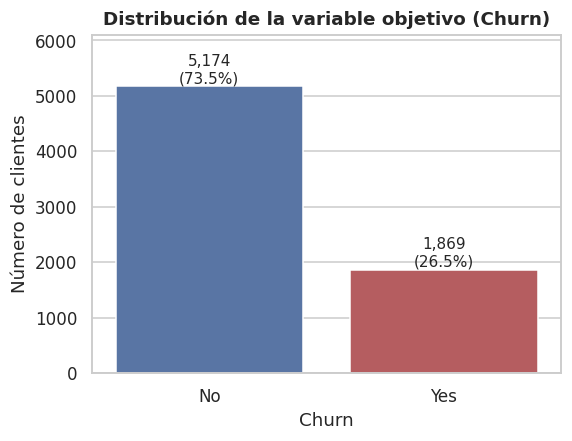

In [8]:
df["Churn_bin"] = (df["Churn"] == "Yes").astype(int)
counts = df["Churn"].value_counts()
pct = df["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"clientes": counts, "porcentaje": pct.round(2)}))
print(f"\nRazón de desbalance (No:Yes) = {counts['No'] / counts['Yes']:.2f} : 1")
print(f"Accuracy de un modelo trivial que siempre predice 'No': {pct['No']:.1f}%")

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.barplot(x=counts.index, y=counts.values, palette=CHURN_COLORS, ax=ax)
for i, (v, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, v + 60, f"{v:,}\n({p:.1f}%)", ha="center", fontsize=10)
ax.set_title("Distribución de la variable objetivo (Churn)")
ax.set_xlabel("Churn"); ax.set_ylabel("Número de clientes"); ax.set_ylim(0, counts.max() * 1.18)
savefig("01_distribucion_churn.png"); plt.show()

**Interpretación:** hay un desbalance **moderado** (≈ 2,8 : 1). Un modelo que siempre responde "No" obtendría ~73,5 % de accuracy sin detectar ningún churner, lo que confirma que **accuracy no es una métrica válida** para este problema. Se usará split **estratificado**, validación cruzada estratificada y se evaluará *class_weight* / SMOTE (solo dentro del entrenamiento) en el modelado.

In [9]:
# Valor económico del problema: ¿cuánto ingreso mensual se va con los clientes que abandonan?
ingreso_total = df["MonthlyCharges"].sum()
ingreso_churn = df.loc[df["Churn"] == "Yes", "MonthlyCharges"].sum()
print(f"Ingreso mensual total de la base: ${ingreso_total:,.0f}")
print(f"Ingreso mensual de los clientes que abandonan: ${ingreso_churn:,.0f}  ({ingreso_churn / ingreso_total * 100:.1f} % del total)")
print("Cargo mensual promedio ->", df.groupby("Churn")["MonthlyCharges"].mean().round(1).to_dict())

Ingreso mensual total de la base: $456,117
Ingreso mensual de los clientes que abandonan: $139,131  (30.5 % del total)
Cargo mensual promedio -> {'No': 61.3, 'Yes': 74.4}


**Interpretación:** los clientes que abandonan son el 26,5 % de la base, pero se llevan ≈ \$139,1 mil de ingreso mensual, es decir **≈ 30,5 % del total**, porque pagan más que los que se quedan. Por eso, además de contar clientes detectados, la evaluación (sección 5.6) mide **cuánto ingreso mensual en riesgo** alcanza el modelo.

### 2.4 Variables numéricas

In [10]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print(df[num_cols].describe().round(2))
print("\nAsimetría (skewness):")
print(df[num_cols].skew().round(3))
print("\nMedia y mediana por grupo de Churn:")
print(df.groupby("Churn")[num_cols].agg(["mean", "median"]).round(1))

        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7032.00
mean     32.37           64.76       2283.30
std      24.56           30.09       2266.77
min       0.00           18.25         18.80
25%       9.00           35.50        401.45
50%      29.00           70.35       1397.48
75%      55.00           89.85       3794.74
max      72.00          118.75       8684.80

Asimetría (skewness):
tenure            0.240
MonthlyCharges   -0.221
TotalCharges      0.962
dtype: float64

Media y mediana por grupo de Churn:
      tenure        MonthlyCharges        TotalCharges        
        mean median           mean median         mean  median
Churn                                                         
No      37.6   38.0           61.3   64.4       2555.3  1683.6
Yes     18.0   10.0           74.4   79.6       1531.8   703.6


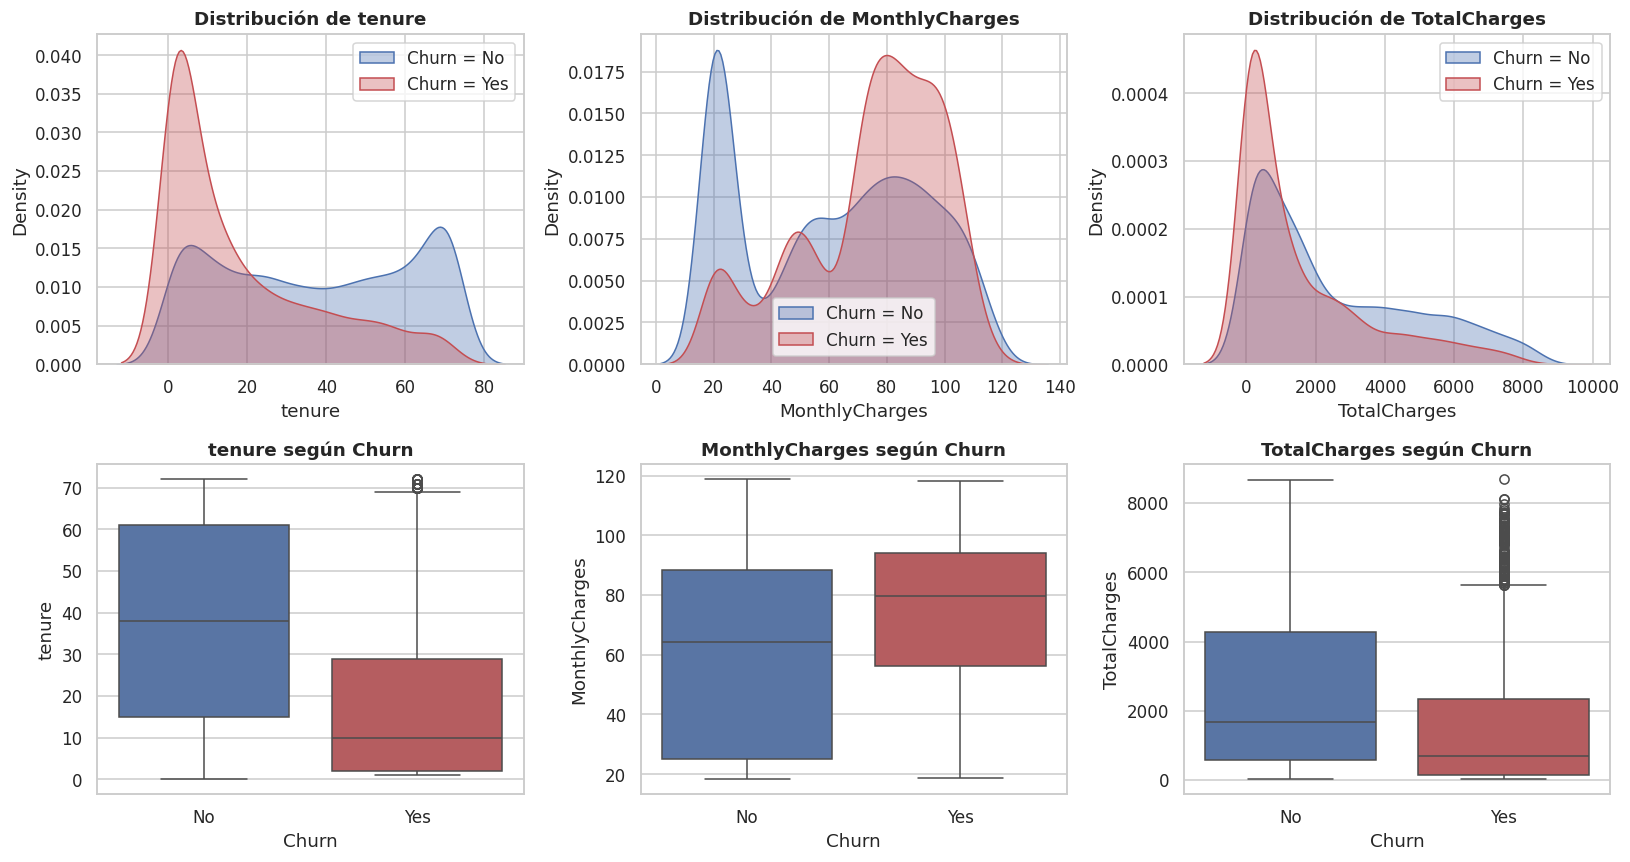

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for j, c in enumerate(num_cols):
    for lab, col in CHURN_COLORS.items():
        sns.kdeplot(df.loc[df["Churn"] == lab, c].dropna(), ax=axes[0, j], color=col, fill=True, alpha=0.35, label=f"Churn = {lab}")
    axes[0, j].set_title(f"Distribución de {c}"); axes[0, j].legend()
    sns.boxplot(data=df, x="Churn", y=c, palette=CHURN_COLORS, ax=axes[1, j])
    axes[1, j].set_title(f"{c} según Churn")
plt.tight_layout(); savefig("02_variables_numericas.png"); plt.show()

In [12]:
# Detección de valores atípicos con la regla del IQR
rows = []
for c in num_cols:
    s = df[c].dropna()
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({"variable": c, "límite_inf": round(lo, 1), "límite_sup": round(hi, 1),
                 "n_atípicos": int(((s < lo) | (s > hi)).sum())})
pd.DataFrame(rows)

,variable,límite_inf,límite_sup,n_atípicos
0,tenure,-60.0,124.0,0
1,MonthlyCharges,-46.0,171.4,0
2,TotalCharges,-4688.5,8884.7,0


**Interpretación:**
- Los clientes que abandonan tienen **mucho menos antigüedad** (mediana 10 vs 38 meses) y **pagan más por mes** (mediana ≈ \$80 vs \$64).
- `tenure` y `MonthlyCharges` tienen distribuciones sin atípicos por IQR. `TotalCharges` tiene asimetría positiva fuerte (≈ 0,96): es un monto acumulado que crece con la antigüedad. Se evaluará una transformación logarítmica en la preparación.
- No hay valores atípicos que justifiquen eliminar registros: los valores extremos son clientes legítimos con tarifas altas o antigüedad larga.

### 2.5 Variables categóricas frente al churn
Para cada categoría se calcula la **tasa de churn** (porcentaje de clientes que abandonan). La línea punteada es la tasa global (26,5 %): las barras por encima indican grupos de mayor riesgo.

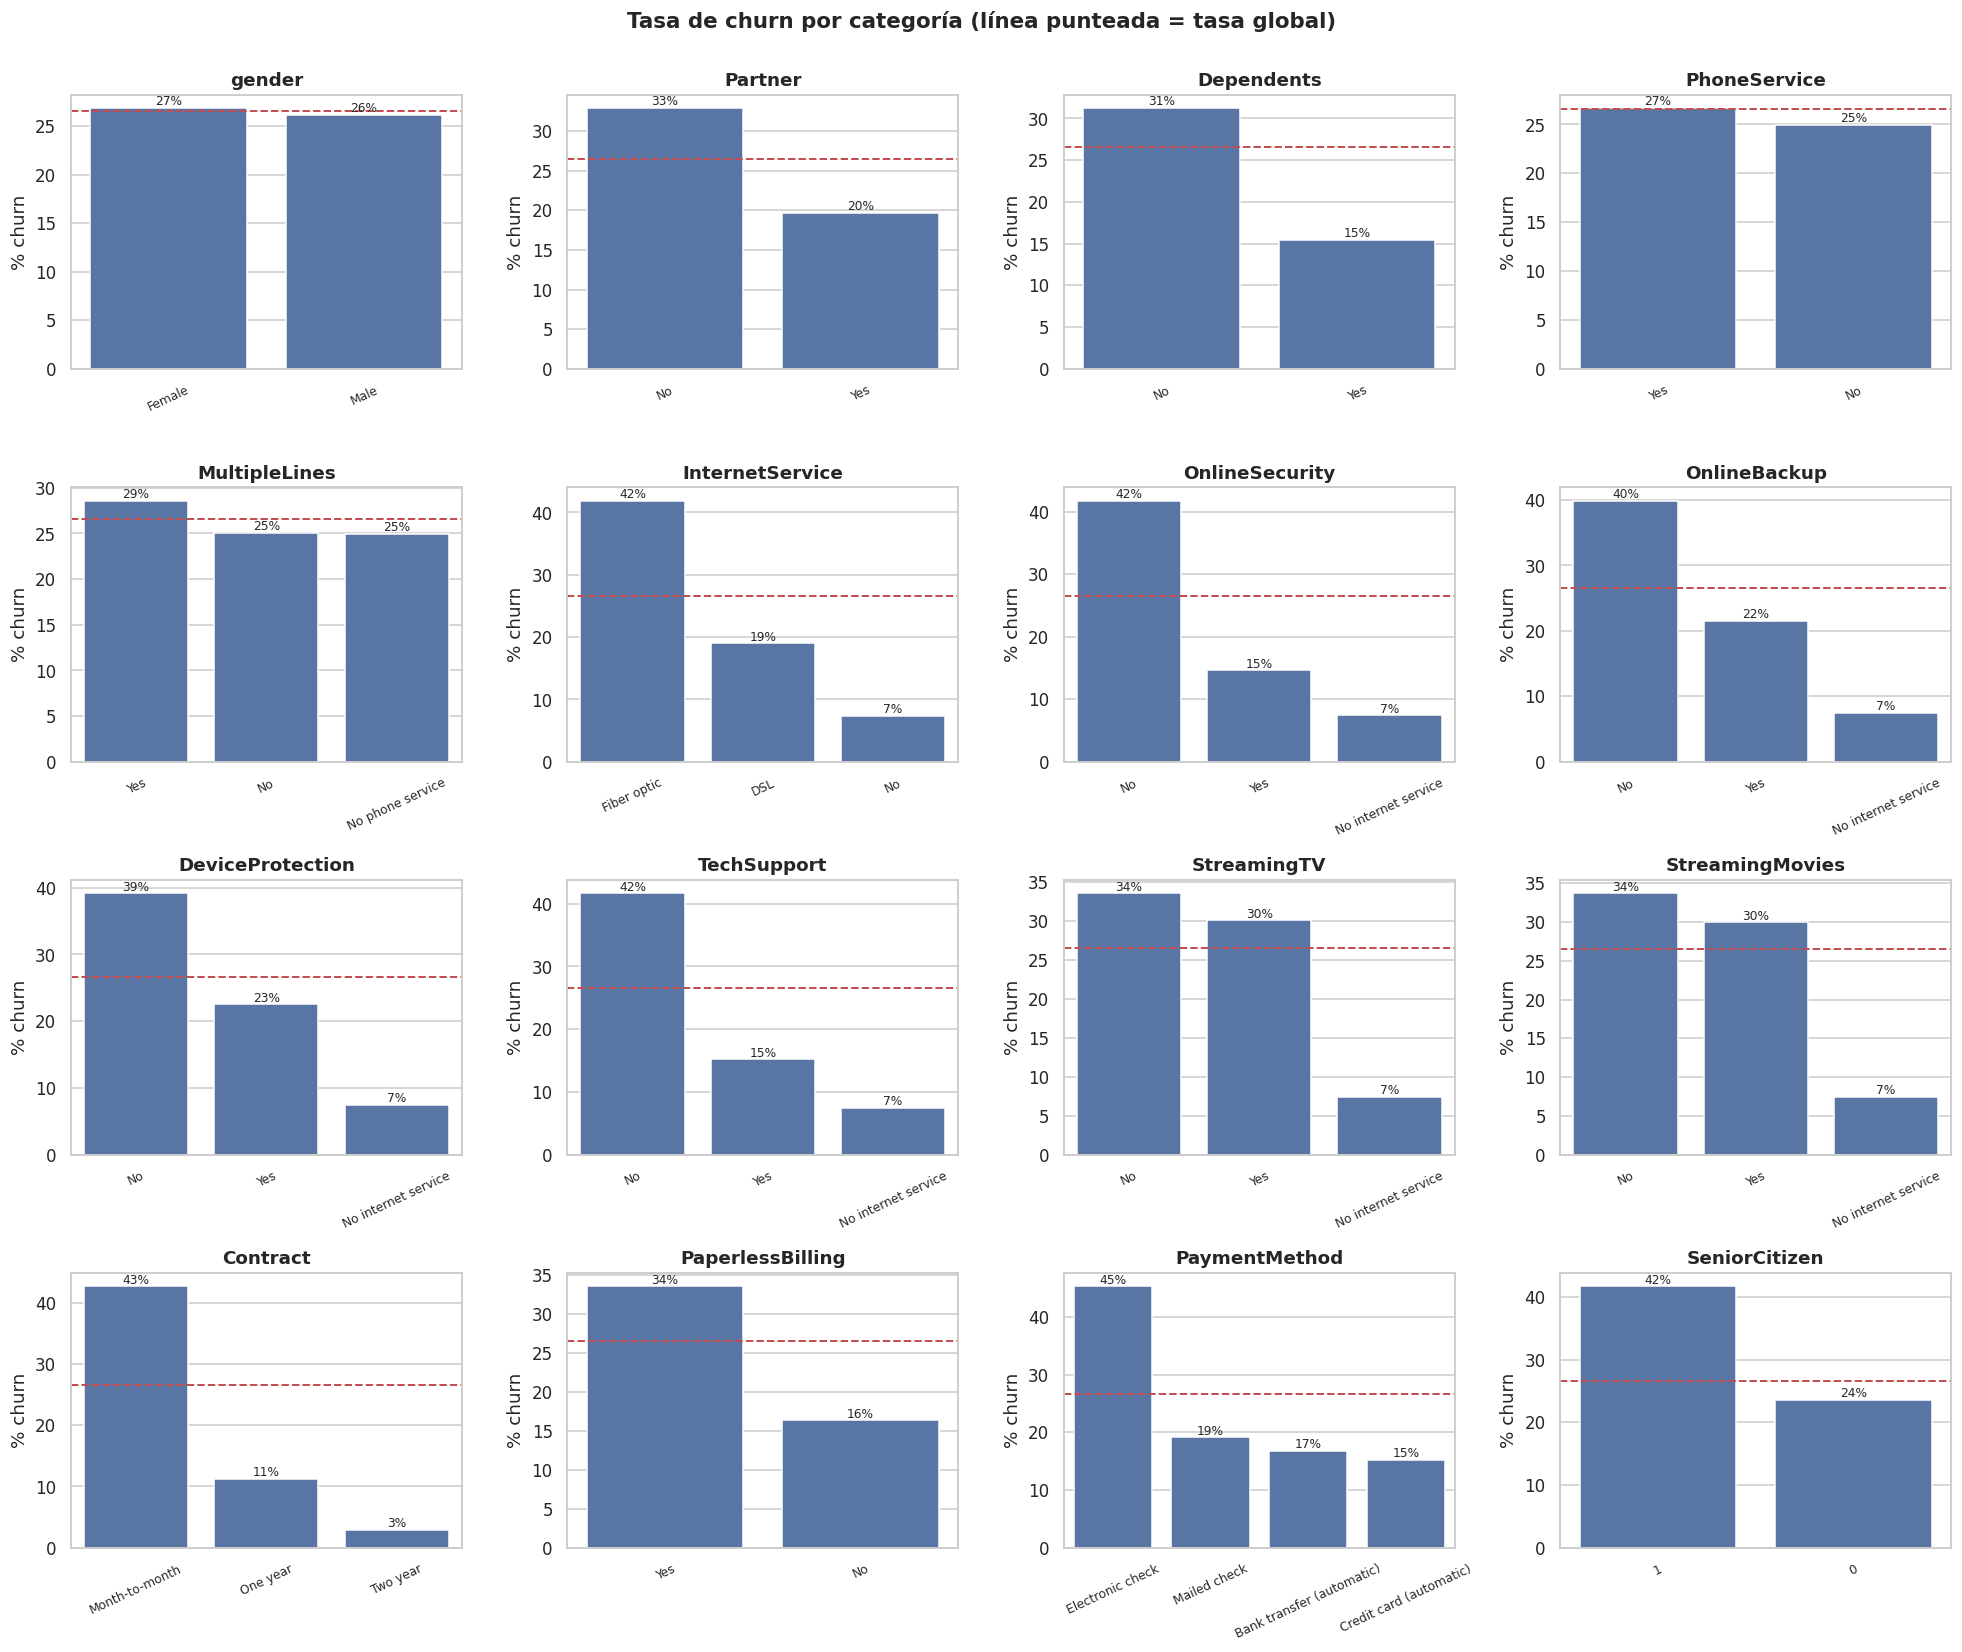

In [13]:
global_rate = df["Churn_bin"].mean() * 100
cat_all = cat_cols + ["SeniorCitizen"]

fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax, c in zip(axes.ravel(), cat_all):
    rate = df.groupby(c)["Churn_bin"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color="#4C72B0")
    ax.axhline(global_rate, ls="--", color="#C44E52", lw=1.3)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("% churn")
    ax.tick_params(axis="x", rotation=25, labelsize=8)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)
plt.suptitle("Tasa de churn por categoría (línea punteada = tasa global)", y=1.0, fontsize=14, fontweight="bold")
plt.tight_layout(); savefig("03_churn_por_categoria.png"); plt.show()

**Interpretación:**
- **Contrato:** *Month-to-month* tiene ≈ 43 % de churn frente a 11 % (1 año) y 3 % (2 años). Es el factor más fuerte.
- **Internet:** *Fiber optic* ≈ 42 % vs 19 % en DSL y 7 % sin internet.
- **Pago:** *Electronic check* ≈ 45 %, muy por sobre las formas automáticas (15–17 %).
- **Servicios de protección:** sin `OnlineSecurity` ni `TechSupport`, el churn se duplica o triplica (≈ 42 % vs ≈ 15 %).
- **Demografía:** `SeniorCitizen` (42 % vs 24 %), sin pareja (33 % vs 20 %) y sin dependientes (31 % vs 16 %) muestran más churn.
- **`gender` y `PhoneService` casi no discriminan** (≈ 27 % vs 26 %), lo que será relevante en el análisis ético.

### 2.6 Antigüedad (tenure) y riesgo

              % churn  clientes
tenure_group                   
0-12 m           47.4      2186
13-24 m          28.7      1024
25-48 m          20.4      1594
49-72 m           9.5      2239


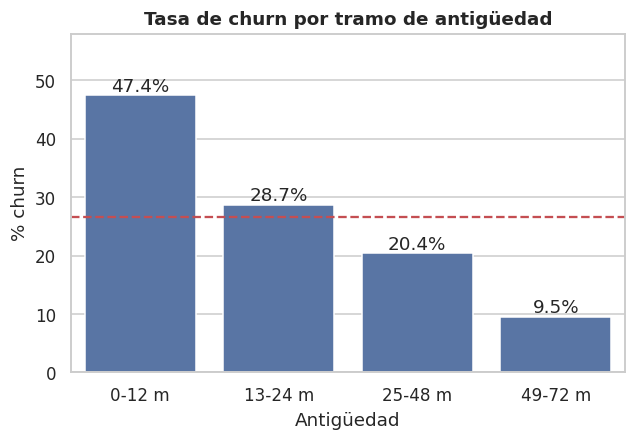

In [14]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])
tg = df.groupby("tenure_group", observed=True)["Churn_bin"].agg(["mean", "count"])
tg["mean"] = (tg["mean"] * 100).round(1)
print(tg.rename(columns={"mean": "% churn", "count": "clientes"}))

fig, ax = plt.subplots(figsize=(6.5, 4))
sns.barplot(x=tg.index.astype(str), y=tg["mean"], color="#4C72B0", ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.axhline(global_rate, ls="--", color="#C44E52"); ax.set_ylim(0, 58)
ax.set_title("Tasa de churn por tramo de antigüedad"); ax.set_xlabel("Antigüedad"); ax.set_ylabel("% churn")
savefig("04_churn_por_tenure.png"); plt.show()

**Interpretación:** el riesgo cae de forma monótona con la antigüedad: casi **1 de cada 2** clientes con hasta 12 meses abandona, frente a menos de 1 de cada 10 en el tramo de 49–72 meses. Los **primeros 12 meses son la ventana crítica de retención**. Esta variable derivada (`tenure_group`) se usará en la preparación.

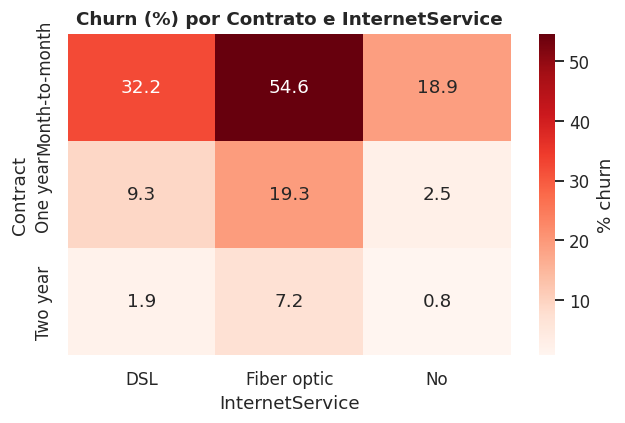

In [15]:
# Interacción Contrato x Tipo de internet: tasa de churn (%)
pivot = df.pivot_table(index="Contract", columns="InternetService", values="Churn_bin", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% churn"}, ax=ax)
ax.set_title("Churn (%) por Contrato e InternetService")
savefig("05_heatmap_contrato_internet.png"); plt.show()

**Interpretación:** la combinación **contrato mensual + fibra óptica** concentra el mayor riesgo, mientras que los contratos de 2 años casi no presentan churn independientemente del servicio. Esto sugiere un perfil claro para segmentar y para ofertas de migración a contratos largos.

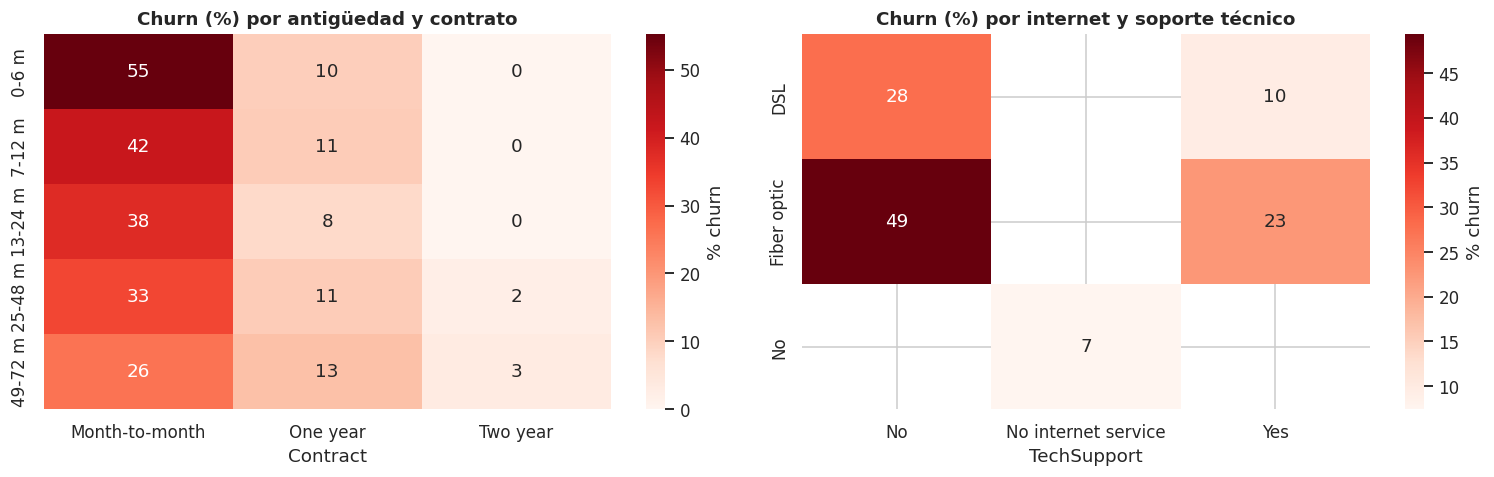

In [16]:
# Interacciones adicionales: antigüedad (tramos más finos, para ver el primer semestre) x contrato, e internet x soporte técnico
df["tramo_fino"] = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72], labels=["0-6 m", "7-12 m", "13-24 m", "25-48 m", "49-72 m"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(df.pivot_table(index="tramo_fino", columns="Contract", values="Churn_bin", aggfunc="mean", observed=True) * 100,
            annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% churn"}, ax=axes[0])
axes[0].set_title("Churn (%) por antigüedad y contrato"); axes[0].set_ylabel("")
sns.heatmap(df.pivot_table(index="InternetService", columns="TechSupport", values="Churn_bin", aggfunc="mean") * 100,
            annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% churn"}, ax=axes[1])
axes[1].set_title("Churn (%) por internet y soporte técnico"); axes[1].set_ylabel("")
plt.tight_layout(); savefig("29_interacciones_antiguedad_soporte.png"); plt.show()

**Interpretación:**
- El peor caso es el **contrato mensual con hasta 6 meses de antigüedad: 55 % de churn**, frente a ≈ 10 % con contrato de 1 año y 0 % con contrato de 2 años en ese mismo tramo. El riesgo del contrato mensual baja con la antigüedad (55 % → 26 %), pero se mantiene muy por sobre el de los contratos largos (≤ 13 %).
- **Fibra óptica sin soporte técnico: 49 % de churn**, frente a 23 % con soporte; en DSL, 28 % sin soporte frente a 10 % con soporte. Los clientes sin internet tienen solo 7 %.
- Ambos patrones respaldan las variables derivadas `tenure_group`, `fiber_monthly` y `n_protection` que se crean en la etapa de preparación.

### 2.7 Relevancia de variables y correlaciones
**Numéricas:** correlación de Pearson (incluye churn codificado 0/1).
**Categóricas:** *V de Cramér* frente al churn (0 = sin asociación, 1 = asociación perfecta) con prueba chi-cuadrado.

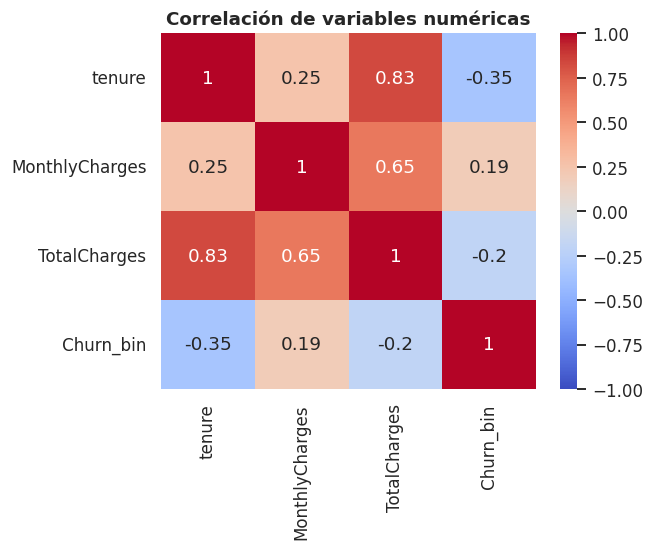

                tenure  MonthlyCharges  TotalCharges  Churn_bin
tenure            1.00            0.25          0.83      -0.35
MonthlyCharges    0.25            1.00          0.65       0.19
TotalCharges      0.83            0.65          1.00      -0.20
Churn_bin        -0.35            0.19         -0.20       1.00


In [17]:
corr = df[num_cols + ["Churn_bin"]].corr().round(2)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de variables numéricas")
savefig("06_correlacion_numericas.png"); plt.show()
print(corr)

**Interpretación:** `tenure` y `TotalCharges` están muy correlacionadas (≈ 0,83), lo que implica **multicolinealidad** que afectará a la Regresión Logística y justifica el uso de regularización y de PCA. `tenure` es la numérica más asociada al churn (≈ −0,35).

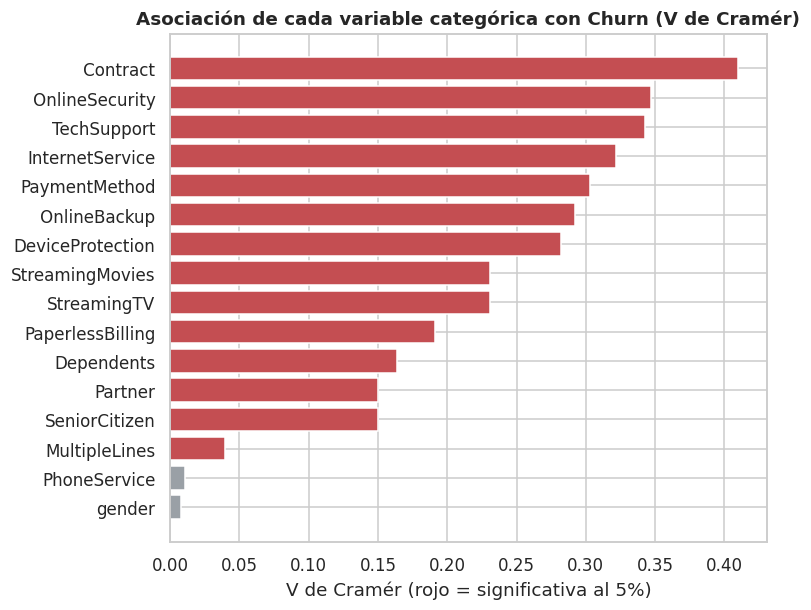

,variable,V_Cramér,p_valor,significativa_5%
0,Contract,0.410,5.86e-258,True
1,OnlineSecurity,0.347,2.66e-185,True
2,TechSupport,0.343,1.44e-180,True
3,InternetService,0.322,9.57e-160,True
4,PaymentMethod,0.303,3.68e-140,True
5,OnlineBackup,0.292,2.08e-131,True
6,DeviceProtection,0.282,5.51e-122,True
7,StreamingMovies,0.231,2.67e-82,True
8,StreamingTV,0.231,5.53e-82,True
9,PaperlessBilling,0.191,4.07e-58,True


In [18]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(ct)
    n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1))), p

res = []
for c in cat_all:
    v, p = cramers_v(df[c], df["Churn_bin"])
    res.append({"variable": c, "V_Cramér": round(v, 3), "p_valor": p})
assoc = pd.DataFrame(res).sort_values("V_Cramér", ascending=False).reset_index(drop=True)
assoc["significativa_5%"] = assoc["p_valor"] < 0.05
assoc["p_valor"] = assoc["p_valor"].map(lambda x: f"{x:.2e}")

fig, ax = plt.subplots(figsize=(7, 6))
colors = ["#C44E52" if s else "#9aa0a6" for s in assoc["significativa_5%"]]
ax.barh(assoc["variable"][::-1], assoc["V_Cramér"][::-1], color=colors[::-1])
ax.set_title("Asociación de cada variable categórica con Churn (V de Cramér)")
ax.set_xlabel("V de Cramér (rojo = significativa al 5%)")
savefig("07_cramers_v.png"); plt.show()
assoc

**Interpretación:** las variables más asociadas al churn son **Contract** (V ≈ 0,41), **OnlineSecurity**, **TechSupport**, **InternetService** y **PaymentMethod**. En cambio **gender** (V ≈ 0,01) y **PhoneService** (≈ 0,01) no son significativas, por lo que no aportan poder predictivo. Esto respalda excluir o monitorear `gender` por razones éticas sin perder desempeño.

### 2.8 Conclusiones del EDA y decisiones para la preparación
| # | Hallazgo | Decisión para Data Preparation |
|---|---|---|
| 1 | `TotalCharges` es texto y tiene 11 vacíos (todos `tenure = 0`) | Convertir a numérico e imputar con **0** |
| 2 | "No internet service" / "No phone service" ≡ "No" | Unificar a **"No"** |
| 3 | Churn desbalanceado (26,5 % / 73,5 %) | Split **estratificado**, CV estratificada, `class_weight` / SMOTE solo en train |
| 4 | `TotalCharges` asimétrica y muy correlacionada con `tenure` | Probar **log-transform**; **regularización** y **PCA** |
| 5 | El churn cae con la antigüedad (47 % → 9,5 %) | Crear `tenure_group` y razones de cargos |
| 6 | Contract, servicios de protección, Internet y pago son los mejores predictores | Encoding One-Hot (y ordinal para `Contract`), variable derivada de nº de servicios |
| 7 | `gender` y `PhoneService` no discriminan | Excluir `gender` del modelo y auditarlo en la sección ética |
| 8 | No hay atípicos que eliminar ni duplicados | Conservar todos los registros |
| 9 | Los clientes que se van pagan más: concentran ≈ 30,5 % del ingreso mensual con el 26,5 % de la base | Medir el impacto también como **ingreso en riesgo capturado**, no solo como clientes detectados |

## 3. Data Preparation
Objetivo: transformar los datos crudos en una matriz numérica lista para modelar, **sin data leakage**.

**Regla de oro aplicada en todo el proyecto**
- Lo que es una *regla fija* (convertir tipos, unificar etiquetas, crear variables derivadas fila a fila) se hace **antes** del split, porque no aprende nada de los datos.
- Lo que *aprende de los datos* (media/desv. del escalado, categorías del One-Hot, componentes del PCA) se ajusta **solo con train** y luego se aplica a test.

La lógica vive en `src/preprocessing.py` para que el notebook y los modelos usen exactamente las mismas transformaciones.

In [19]:
import sys, joblib
sys.path.insert(0, str(ROOT / "src"))
import importlib, preprocessing
importlib.reload(preprocessing)
from preprocessing import (clean_and_engineer, build_preprocessor, FEATURES, NUM_COLS, ORD_COLS,
                           OHE_COLS, BIN_COLS, TARGET)
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)

### 3.1 Limpieza y creación de variables derivadas
Se parte del CSV original (no del `df` del EDA) para que esta sección sea autónoma y reproducible.

| Transformación | Justificación (según el EDA) |
|---|---|
| `TotalCharges` a numérico; vacíos (`tenure = 0`) → **0** | Son clientes sin primera factura; la mediana distorsionaría el significado |
| "No internet service" / "No phone service" → "No" | Equivalentes lógicos; la información la conservan `InternetService` y `PhoneService` |
| `Churn` y variables Yes/No → 1/0 | Codificación binaria directa |
| `log_TotalCharges = log(1 + TotalCharges)` | Reduce la asimetría (0,96) y la dominancia de valores altos |
| `tenure_group` (0-12, 13-24, 25-48, 49-72) | El EDA mostró que el riesgo cambia por tramos de antigüedad |
| `charge_ratio = MonthlyCharges / cargo mensual histórico promedio` | Valores > 1 indican que hoy paga más que su promedio histórico (alza de tarifa o upgrade) |
| `n_services`, `n_protection` | Cantidad de servicios contratados y de servicios de protección/soporte |
| `auto_payment` | 1 si paga con débito/tarjeta automático (el EDA mostró 15–17 % vs 45 % con electronic check) |
| `fiber_monthly` | Interacción de mayor riesgo detectada en el heatmap (fibra + contrato mensual) |
| **Se excluye `gender` y `customerID`** | `gender` no discrimina (V ≈ 0,01) y es un atributo sensible; se conserva aparte solo para auditoría ética |

In [21]:
raw = pd.read_csv(DATA_PATH)
clean = clean_and_engineer(raw)

print("Shape tras limpieza:", clean.shape)
print("Nulos en las features del modelo:", int(clean[FEATURES].isna().sum().sum()))
print("TotalCharges imputados con 0 (tenure=0):", int(((clean['tenure'] == 0)).sum()))
print("\nCategorías de InternetService:", clean['InternetService'].unique().tolist())
clean[["tenure", "tenure_group", "MonthlyCharges", "log_TotalCharges", "charge_ratio",
       "n_services", "n_protection", "auto_payment", "fiber_monthly", "Churn"]].head()

Shape tras limpieza: (7043, 28)
Nulos en las features del modelo: 0
TotalCharges imputados con 0 (tenure=0): 11

Categorías de InternetService: ['DSL', 'Fiber optic', 'No']


,tenure,tenure_group,MonthlyCharges,log_TotalCharges,charge_ratio,n_services,n_protection,auto_payment,fiber_monthly,Churn
0,1,0-12,29.85,3.429137,1.000000,1,1,0,0,0
1,34,25-48,56.95,7.544597,1.024768,3,2,0,0,0
2,2,0-12,53.85,4.692723,0.995839,3,2,0,0,1
3,45,25-48,42.30,7.518471,1.034089,3,3,1,0,0
4,2,0-12,70.70,5.028148,0.932410,1,0,0,1,1


#### Validación de las variables derivadas
Antes de usarlas se comprueba que realmente se relacionan con el churn.

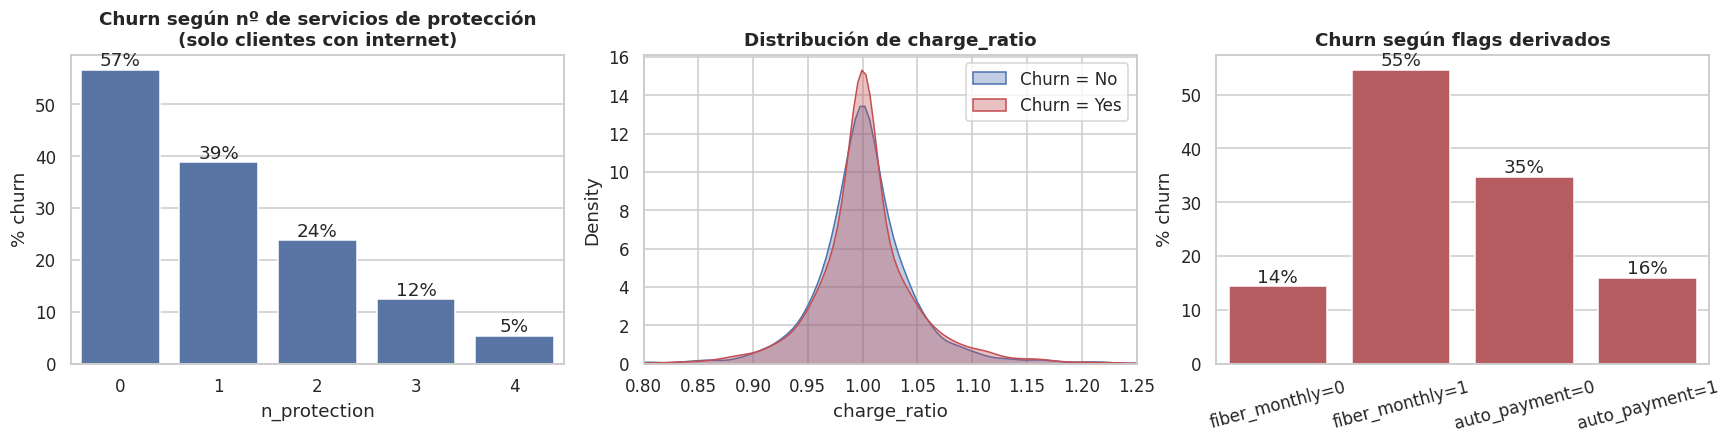

Media de charge_ratio por churn: {0: 1.0019, 1: 1.0033}
Desv. estándar de charge_ratio: 0.0512


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (a) n_protection solo en clientes CON internet (sin internet el valor 0 no significa "sin protección")
with_net = clean[clean["InternetService"] != "No"]
r = with_net.groupby("n_protection")["Churn"].mean() * 100
sns.barplot(x=r.index, y=r.values, color="#4C72B0", ax=axes[0])
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.0f}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
axes[0].set_title("Churn según nº de servicios de protección\n(solo clientes con internet)")
axes[0].set_xlabel("n_protection"); axes[0].set_ylabel("% churn")

# (b) charge_ratio por churn
for lab, col in CHURN_COLORS.items():
    sns.kdeplot(clean.loc[clean["Churn"] == (lab == "Yes"), "charge_ratio"], color=col, fill=True, alpha=0.35,
                label=f"Churn = {lab}", ax=axes[1])
axes[1].set_xlim(0.8, 1.25); axes[1].legend(); axes[1].set_title("Distribución de charge_ratio")

# (c) fiber_monthly y auto_payment
combo = pd.DataFrame({
    "fiber_monthly": clean.groupby("fiber_monthly")["Churn"].mean() * 100,
}).T
vals = {"fiber_monthly=0": clean.loc[clean.fiber_monthly == 0, "Churn"].mean() * 100,
        "fiber_monthly=1": clean.loc[clean.fiber_monthly == 1, "Churn"].mean() * 100,
        "auto_payment=0": clean.loc[clean.auto_payment == 0, "Churn"].mean() * 100,
        "auto_payment=1": clean.loc[clean.auto_payment == 1, "Churn"].mean() * 100}
sns.barplot(x=list(vals.keys()), y=list(vals.values()), color="#C44E52", ax=axes[2])
for p in axes[2].patches:
    axes[2].annotate(f"{p.get_height():.0f}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
axes[2].set_title("Churn según flags derivados"); axes[2].set_ylabel("% churn"); axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout(); savefig("08_variables_derivadas.png"); plt.show()

print("Media de charge_ratio por churn:", clean.groupby("Churn")["charge_ratio"].mean().round(4).to_dict())
print("Desv. estándar de charge_ratio:", round(clean["charge_ratio"].std(), 4))

**Interpretación:**
- `n_protection`: entre clientes con internet, el churn **baja de forma clara al contratar más protección/soporte** (≈ 57 % sin ningún servicio → ≈ 5 % con los 4). Se muestra solo para clientes con internet porque en quienes no tienen internet el valor 0 no significa "sin protección".
- `fiber_monthly` y `auto_payment` separan grupos con tasas de churn muy distintas, tal como anticipó el EDA.
- `charge_ratio` casi no varía (desv. ≈ 0,05) y sus distribuciones por churn se solapan casi por completo: es una variable **débil**. Se conserva por ser una hipótesis de negocio razonable (alzas de tarifa), pero su aporte real se verificará con la importancia de variables y se descartará si no suma.

### 3.2 Transformación logarítmica de `TotalCharges`

Asimetría TotalCharges: 0.963  ->  log1p(TotalCharges): -0.824


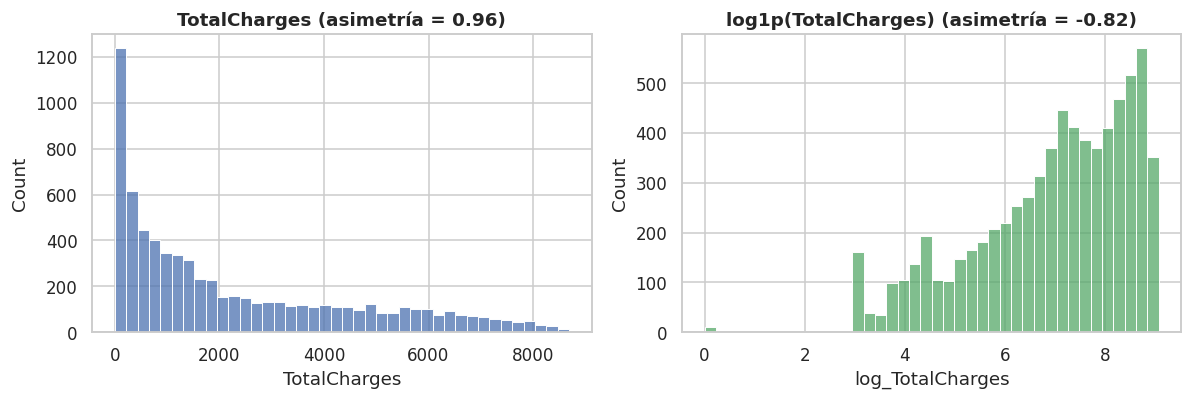

In [23]:
sk_before = clean["TotalCharges"].skew()
sk_after = clean["log_TotalCharges"].skew()
print(f"Asimetría TotalCharges: {sk_before:.3f}  ->  log1p(TotalCharges): {sk_after:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(clean["TotalCharges"], bins=40, color="#4C72B0", ax=axes[0]); axes[0].set_title(f"TotalCharges (asimetría = {sk_before:.2f})")
sns.histplot(clean["log_TotalCharges"], bins=40, color="#55A868", ax=axes[1]); axes[1].set_title(f"log1p(TotalCharges) (asimetría = {sk_after:.2f})")
plt.tight_layout(); savefig("09_log_transform.png"); plt.show()

**Interpretación:** el logaritmo **cambia el signo de la asimetría (0,96 → −0,82) pero casi no reduce su magnitud**: la distribución queda sesgada hacia la izquierda por la gran masa de clientes con pocos meses y cargo acumulado bajo. Es decir, no "normaliza" la variable; solo comprime los valores altos, lo que ayuda a los modelos lineales a no ser dominados por ellos. Los modelos de árboles no necesitan esta transformación y tampoco se perjudican. En resumen, el beneficio de la transformación es moderado y se validará en el modelado.

### 3.3 Split estratificado train / test (80 / 20)
El split se hace **antes** de ajustar cualquier transformación que aprenda de los datos. Se estratifica por `Churn` para mantener la proporción de la clase minoritaria en ambos conjuntos. `gender` se conserva en una tabla aparte solo para la auditoría ética posterior.

In [24]:
X = clean[FEATURES]
y = clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]:,} filas | Test: {X_test.shape[0]:,} filas")
print(f"% churn  total: {y.mean()*100:.2f} | train: {y_train.mean()*100:.2f} | test: {y_test.mean()*100:.2f}")

# Datos limpios (antes de codificar) con gender y customerID, para auditoría ética y trazabilidad
audit_cols = ["customerID", "gender", "SeniorCitizen", TARGET]
clean.loc[X_train.index, audit_cols].to_csv(PROC / "train_audit.csv", index=False)
clean.loc[X_test.index, audit_cols].to_csv(PROC / "test_audit.csv", index=False)

Train: 5,634 filas | Test: 1,409 filas
% churn  total: 26.54 | train: 26.54 | test: 26.54


### 3.4 Codificación y escalado (ajustados solo con train)
| Tipo | Variables | Técnica | Justificación |
|---|---|---|---|
| Numéricas | `tenure`, `MonthlyCharges`, `log_TotalCharges`, `charge_ratio`, `n_services`, `n_protection` | `StandardScaler` | Media 0 y desv. 1; necesario para regresión logística regularizada, K-Means y PCA |
| Ordinales | `Contract`, `tenure_group` | `OrdinalEncoder` con orden explícito | Tienen un orden natural (mensual < 1 año < 2 años; tramos de antigüedad) |
| Nominales | `InternetService`, `PaymentMethod` | `OneHotEncoder(drop="first")` | Sin orden; `drop="first"` evita colinealidad perfecta en modelos lineales |
| Binarias | 14 columnas 0/1 | *passthrough* | Ya están codificadas |

**¿Target Encoding?** Se evaluó y **no se aplica**: las variables nominales tienen solo 3–4 categorías, así que One-Hot no genera alta dimensionalidad. El Target Encoding introduce riesgo de *leakage* (usa la variable objetivo para codificar) y requeriría validación cruzada interna, sin beneficio aquí. Sería una buena opción con variables de alta cardinalidad (por ejemplo, código postal).

In [25]:
preprocessor = build_preprocessor()
preprocessor.fit(X_train)                       # <- aprende SOLO con train

X_train_p = preprocessor.transform(X_train)
X_test_p = preprocessor.transform(X_test)

print("Matriz procesada  train:", X_train_p.shape, "| test:", X_test_p.shape)
print("Nulos train/test:", int(X_train_p.isna().sum().sum()), "/", int(X_test_p.isna().sum().sum()))
print("\nMedia y desv. de las numéricas en TRAIN (deben ser ~0 y ~1):")
print(X_train_p[NUM_COLS].agg(["mean", "std"]).round(3))
print("\nMedia y desv. de las numéricas en TEST (no son exactamente 0 y 1: se usó la escala de train):")
print(X_test_p[NUM_COLS].agg(["mean", "std"]).round(3))
print("\nColumnas finales:", list(X_train_p.columns))

Matriz procesada  train: (5634, 27) | test: (1409, 27)
Nulos train/test: 0 / 0

Media y desv. de las numéricas en TRAIN (deben ser ~0 y ~1):
      tenure  MonthlyCharges  log_TotalCharges  charge_ratio  n_services  \
mean    -0.0            -0.0              -0.0           0.0        -0.0   
std      1.0             1.0               1.0           1.0         1.0   

      n_protection  
mean          -0.0  
std            1.0  

Media y desv. de las numéricas en TEST (no son exactamente 0 y 1: se usó la escala de train):
      tenure  MonthlyCharges  log_TotalCharges  charge_ratio  n_services  \
mean  -0.023          -0.028            -0.036         0.031      -0.049   
std    0.998           0.992             1.011         1.018       0.977   

      n_protection  
mean        -0.046  
std          0.994  

Columnas finales: ['tenure', 'MonthlyCharges', 'log_TotalCharges', 'charge_ratio', 'n_services', 'n_protection', 'Contract', 'tenure_group', 'InternetService_Fiber optic', 'Intern

**Evidencia anti-leakage:** en train las numéricas tienen media 0 y desviación 1 por construcción; en test **no** (se escalaron con los parámetros de train). Si el escalador se hubiera ajustado con todos los datos, ambos conjuntos tendrían media ≈ 0 y desv. ≈ 1, señal de que el test habría influido en la transformación.

In [26]:
# Persistencia: preprocesador ajustado + conjuntos procesados
joblib.dump(preprocessor, MODELS / "preprocessor.joblib")
X_train_p.assign(Churn=y_train.values).to_csv(PROC / "train_processed.csv", index=False)
X_test_p.assign(Churn=y_test.values).to_csv(PROC / "test_processed.csv", index=False)
print("Guardado: models/preprocessor.joblib, data/processed/train_processed.csv y test_processed.csv")

Guardado: models/preprocessor.joblib, data/processed/train_processed.csv y test_processed.csv


### 3.5 Estrategia frente al desbalance de clases
No se remuestrea aquí a propósito: aplicar SMOTE sobre todos los datos o antes de la validación cruzada genera *leakage* (muestras sintéticas derivadas de filas que luego aparecen en validación). En la etapa de modelado se comparan, **dentro de un `Pipeline` y solo sobre cada fold de entrenamiento**: (a) `class_weight="balanced"`, (b) SMOTE y (c) ajuste del umbral de decisión. El conjunto de test queda siempre intacto, con su desbalance real.

### 3.6 Análisis de Componentes Principales (PCA)
**Propósito:** (1) medir cuánta información (varianza) concentran pocas dimensiones, (2) visualizar los clientes en 2D y (3) evaluar más adelante si usar componentes mejora o simplifica algún modelo.

**Metodología:** se ajusta **solo con train**, sobre la matriz ya procesada y estandarizada completa (para que las binarias y las numéricas pesen igual).

> **Limitación:** PCA asume variables continuas y mide varianza lineal; aquí hay muchas binarias/one-hot, por lo que los componentes son menos "limpios" que con datos puramente numéricos. Por eso PCA se usa como herramienta de análisis y visualización, y se compara contra los modelos con las variables originales en lugar de reemplazarlas por defecto.

Componentes para 80% de varianza: 11 | 90%: 15 | 95%: 18  (de 27 variables)
Varianza explicada por PC1..PC5: [27.7, 15.6, 7.4, 6.0, 4.6]


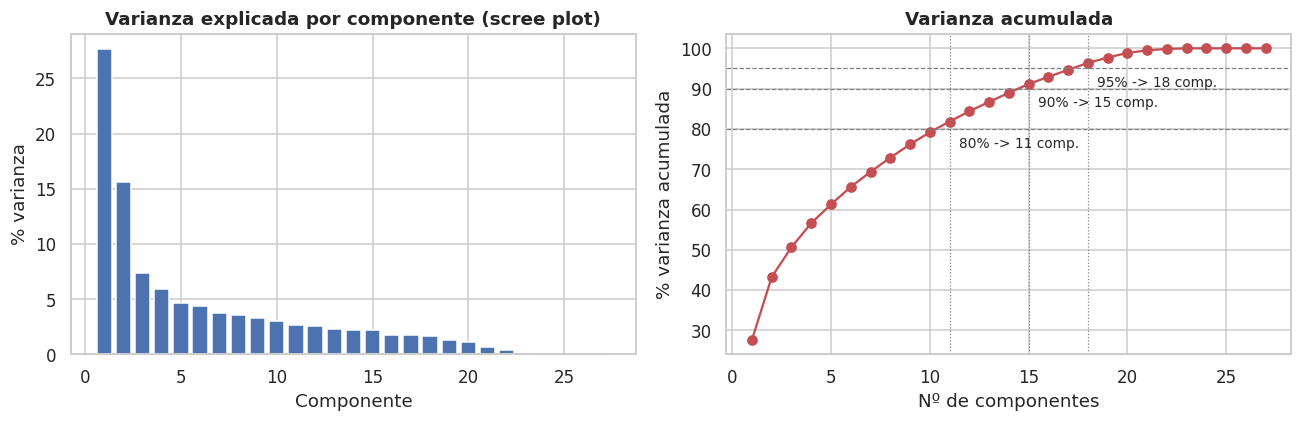

In [27]:
scaler_pca = StandardScaler().fit(X_train_p)
Z_train = scaler_pca.transform(X_train_p)

pca_full = PCA(random_state=RANDOM_STATE).fit(Z_train)
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)
n80, n90, n95 = [int(np.argmax(cum >= t) + 1) for t in (0.80, 0.90, 0.95)]
print(f"Componentes para 80% de varianza: {n80} | 90%: {n90} | 95%: {n95}  (de {Z_train.shape[1]} variables)")
print("Varianza explicada por PC1..PC5:", (evr[:5] * 100).round(1).tolist())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, len(evr) + 1), evr * 100, color="#4C72B0")
axes[0].set_title("Varianza explicada por componente (scree plot)"); axes[0].set_xlabel("Componente"); axes[0].set_ylabel("% varianza")
axes[1].plot(range(1, len(cum) + 1), cum * 100, marker="o", color="#C44E52")
for thr, n in ((80, n80), (90, n90), (95, n95)):
    axes[1].axhline(thr, ls="--", color="gray", lw=0.8); axes[1].axvline(n, ls=":", color="gray", lw=0.8)
    axes[1].annotate(f"{thr}% -> {n} comp.", (n, thr), textcoords="offset points", xytext=(6, -12), fontsize=9)
axes[1].set_title("Varianza acumulada"); axes[1].set_xlabel("Nº de componentes"); axes[1].set_ylabel("% varianza acumulada")
plt.tight_layout(); savefig("10_pca_varianza.png"); plt.show()

**Interpretación:** PC1 captura 27,7 % y PC2 15,6 % de la varianza (43,3 % entre ambas). Se necesitan **11 componentes para el 80 %, 15 para el 90 % y 18 para el 95 %** de las 27 variables, sin un "codo" marcado: lo esperable cuando hay muchas variables binarias poco correlacionadas entre sí. PCA permite reducir de 27 a 15 dimensiones conservando el 90 % de la varianza, pero no comprimir los datos a 2–3 variables sin perder mucha información.

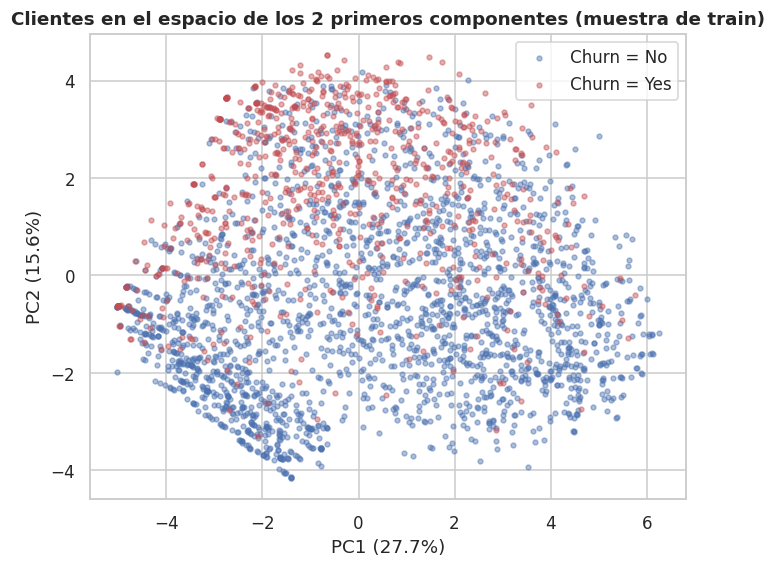

In [28]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z_train)
P = pca2.transform(Z_train)
samp = np.random.RandomState(RANDOM_STATE).choice(len(P), size=3000, replace=False)

fig, ax = plt.subplots(figsize=(7, 5.5))
for lab, col in CHURN_COLORS.items():
    m = (y_train.values[samp] == (lab == "Yes"))
    ax.scatter(P[samp][m, 0], P[samp][m, 1], s=10, alpha=0.45, color=col, label=f"Churn = {lab}")
ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Clientes en el espacio de los 2 primeros componentes (muestra de train)"); ax.legend()
savefig("11_pca_scatter.png"); plt.show()

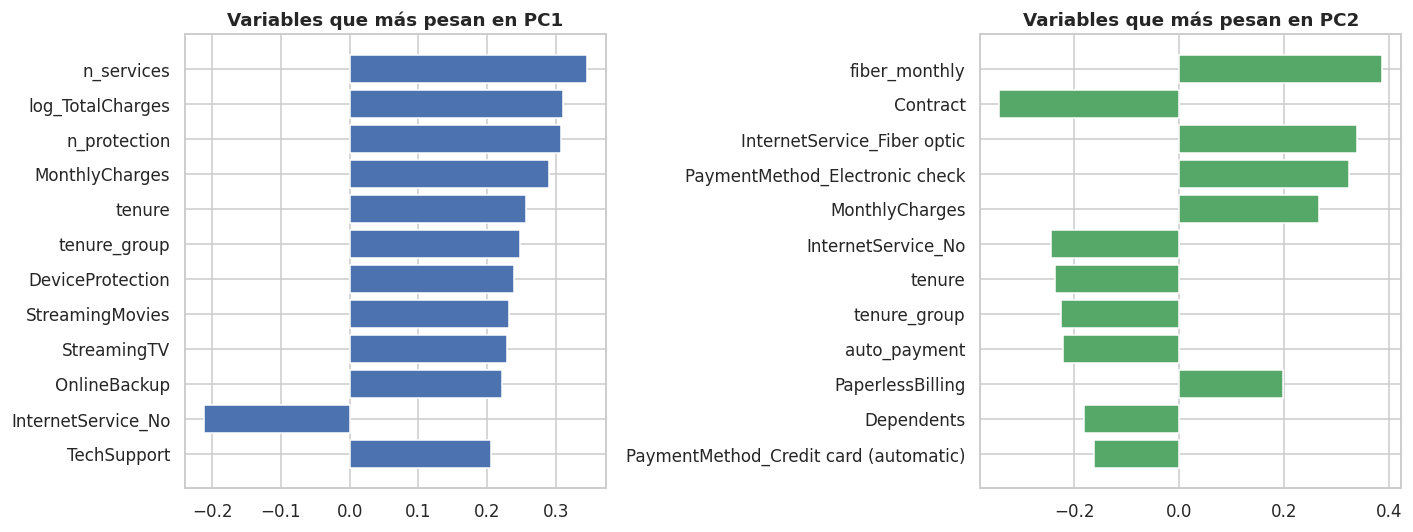

     n_services  log_TotalCharges  n_protection  MonthlyCharges  tenure  \
PC1        0.35              0.31          0.31            0.29    0.26   
PC2        0.04             -0.07         -0.07            0.27   -0.24   

     tenure_group  DeviceProtection  StreamingMovies  StreamingTV  \
PC1          0.25              0.24             0.23         0.23   
PC2         -0.23             -0.00             0.11         0.12   

     OnlineBackup  InternetService_No  TechSupport  
PC1          0.22               -0.21         0.21  
PC2         -0.00               -0.25        -0.10  


In [29]:
loadings = pd.DataFrame(pca2.components_.T, index=X_train_p.columns, columns=["PC1", "PC2"])
top = loadings.reindex(loadings["PC1"].abs().sort_values(ascending=False).index).head(12)
top2 = loadings.reindex(loadings["PC2"].abs().sort_values(ascending=False).index).head(12)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(top.index[::-1], top["PC1"][::-1], color="#4C72B0"); axes[0].set_title("Variables que más pesan en PC1")
axes[1].barh(top2.index[::-1], top2["PC2"][::-1], color="#55A868"); axes[1].set_title("Variables que más pesan en PC2")
plt.tight_layout(); savefig("12_pca_loadings.png"); plt.show()
print(top.round(2).T)

**Interpretación:**
- **PC1** es un eje de *"tamaño de la relación con la compañía"*: pesan juntos `n_services`, `log_TotalCharges`, `n_protection`, `MonthlyCharges` y `tenure`. Valores altos = clientes con muchos servicios, cargo acumulado alto y mayor antigüedad.
- **PC2** contrasta **cargo mensual alto** (positivo) con **antigüedad** y **no tener internet** (negativos): separa a clientes nuevos con tarifa alta de clientes antiguos o sin internet.
- En el plano PC1–PC2 los churners se concentran en la zona **superior izquierda** (PC1 bajo, PC2 alto: pocos servicios/poca antigüedad y tarifa mensual alta), coherente con el EDA, pero **no se separan nítidamente** de los no-churners: hay un solapamiento importante. Esto anticipa que un modelo supervisado aportará más que una proyección 2D.

In [30]:
# PCA reutilizable (se ajusta solo con train): conserva 90% de la varianza
pca_pipe = Pipeline([("scaler", StandardScaler()),
                     ("pca", PCA(n_components=0.90, random_state=RANDOM_STATE))]).fit(X_train_p)
joblib.dump(pca_pipe, MODELS / "pca_90.joblib")
print("Componentes retenidos (90% varianza):", pca_pipe.named_steps["pca"].n_components_)
print("Guardado: models/pca_90.joblib")

Componentes retenidos (90% varianza): 15
Guardado: models/pca_90.joblib


### 3.7 Checklist anti-leakage y resumen de la etapa
| Control | Cómo se cumple |
|---|---|
| El test no influye en ninguna transformación | Escalador, One-Hot, Ordinal y PCA se ajustan solo con `X_train` |
| Reglas deterministas fuera del ajuste | `clean_and_engineer` no calcula estadísticos de los datos |
| Imputación sin usar el target ni el test | `TotalCharges` vacío → 0 por regla de negocio (`tenure = 0`) |
| Sin target encoding | Evita usar `Churn` para construir features |
| Remuestreo sin contaminar validación | SMOTE solo dentro de Pipeline y por fold (etapa 4) |
| Variable sensible fuera del modelo | `gender` excluida; guardada aparte para auditoría |
| Distribución de clases preservada | Split estratificado (26,5 % de churn en train y test) |

**Salidas de esta etapa:** `models/preprocessor.joblib`, `models/pca_90.joblib`, `data/processed/train_processed.csv`, `test_processed.csv`, `train_audit.csv`, `test_audit.csv` y los gráficos `08` a `12` en `images/`.

## 4. Modeling
**Regla de oro:** en esta etapa **no se toca el conjunto de test**. Toda comparación y selección se hace con **validación cruzada estratificada (5 folds) sobre train**; el test se usará una sola vez, en la etapa 5, para la evaluación final.

**Modelos supervisados elegidos y por qué**
| Modelo | Rol | Justificación |
|---|---|---|
| `DummyClassifier` | Línea base | Fija el piso: cualquier modelo útil debe superarlo |
| **Regresión Logística** (L1/L2) | Modelo lineal interpretable | Coeficientes explicables al negocio; la regularización controla el overfitting y la multicolinealidad detectada en el EDA |
| **Random Forest** | Ensamble *bagging* de árboles | Captura no linealidades e interacciones; robusto, con riesgo de overfitting controlado por `max_depth` y `min_samples_leaf` |
| **Gradient Boosting** (`HistGradientBoosting`) | Ensamble *boosting* | Suele ser el mejor en datos tabulares; incluye **early stopping**, profundidad limitada y regularización L2 |

**Métrica de selección:** **PR-AUC** (`average_precision`). No depende del umbral y es la más informativa con la clase minoritaria (línea base = prevalencia ≈ 0,265). Se reportan también ROC-AUC, F1, Recall y Precision.

Todo el preprocesamiento va **dentro del `Pipeline`**: en cada fold el escalador y los codificadores se ajustan solo con las filas de entrenamiento de ese fold.

In [31]:
import time
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import cross_validate
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import modeling
importlib.reload(modeling)
from modeling import (SCORING, get_cv, make_pipe, search_logreg, search_rf, search_hgb,
                      pick_parsimonious, fit_selected)

REPORTS = ROOT / "reports"; REPORTS.mkdir(exist_ok=True)
cv = get_cv()

### 4.1 Línea base
Un clasificador que predice siempre según la prevalencia. Es el piso contra el cual se mide todo lo demás.

In [32]:
r = cross_validate(make_pipe(DummyClassifier(strategy="prior")), X_train, y_train, cv=cv, scoring=SCORING)
baseline = {m: r[f"test_{m}"].mean() for m in SCORING}
print({k: round(v, 3) for k, v in baseline.items()})

{'pr_auc': np.float64(0.265), 'roc_auc': np.float64(0.5), 'f1': np.float64(0.0), 'recall': np.float64(0.0), 'precision': np.float64(0.0)}


**Interpretación:** PR-AUC = 0,265 (igual a la prevalencia de churn) y ROC-AUC = 0,5: es el azar. Recall y F1 son 0 porque nunca detecta churners. Cualquier modelo debe superar **PR-AUC 0,265** y **ROC-AUC 0,5** con holgura.

### 4.2 Estrategias frente al desbalance (comparación justa, dentro de la validación cruzada)
Se comparan tres enfoques con cada algoritmo (hiperparámetros razonables por defecto):
1. **Sin tratamiento**
2. **`class_weight="balanced"`**: penaliza más los errores sobre la clase churn.
3. **SMOTE**: genera clientes sintéticos de la clase minoritaria, **solo sobre los folds de entrenamiento** (dentro del pipeline).

> *Caveat de SMOTE:* interpola entre vecinos y puede generar valores fraccionarios en columnas binarias (p. ej. 0,4 en `Partner`). `SMOTENC` evitaría esto, pero no cambia la conclusión práctica de abajo.

In [33]:
def make_model(name, cw=None):
    if name == "LogReg":
        return LogisticRegression(max_iter=2000, class_weight=cw, random_state=RANDOM_STATE)
    if name == "RandomForest":
        return RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=cw, n_jobs=-1,
                                      random_state=RANDOM_STATE)
    return HistGradientBoostingClassifier(early_stopping=True, class_weight=cw, random_state=RANDOM_STATE)

rows = []
for mname in ["LogReg", "RandomForest", "HistGB"]:
    for strat in ["none", "class_weight", "smote"]:
        if strat == "smote":
            pipe = ImbPipeline([("pre", build_preprocessor()), ("smote", SMOTE(random_state=RANDOM_STATE)),
                                ("model", make_model(mname))])
        else:
            pipe = make_pipe(make_model(mname, "balanced" if strat == "class_weight" else None))
        res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True)
        rows.append({"modelo": mname, "estrategia": strat,
                     **{m: res[f"test_{m}"].mean() for m in SCORING},
                     "train_pr_auc": res["train_pr_auc"].mean()})
imb = pd.DataFrame(rows)
imb["gap_pr_auc"] = imb["train_pr_auc"] - imb["pr_auc"]
imb.round(3)

,modelo,estrategia,pr_auc,roc_auc,f1,recall,precision,train_pr_auc,gap_pr_auc
0,LogReg,none,0.672,0.850,0.601,0.548,0.666,0.680,0.008
1,LogReg,class_weight,0.671,0.849,0.632,0.801,0.522,0.678,0.007
2,LogReg,smote,0.659,0.844,0.635,0.710,0.574,0.667,0.008
3,RandomForest,none,0.656,0.844,0.573,0.501,0.669,0.865,0.210
4,RandomForest,class_weight,0.657,0.844,0.634,0.715,0.569,0.863,0.206
5,RandomForest,smote,0.636,0.838,0.629,0.704,0.569,0.884,0.248
6,HistGB,none,0.643,0.839,0.569,0.512,0.640,0.821,0.178
7,HistGB,class_weight,0.649,0.841,0.629,0.762,0.536,0.782,0.133
8,HistGB,smote,0.628,0.830,0.620,0.657,0.588,0.858,0.230


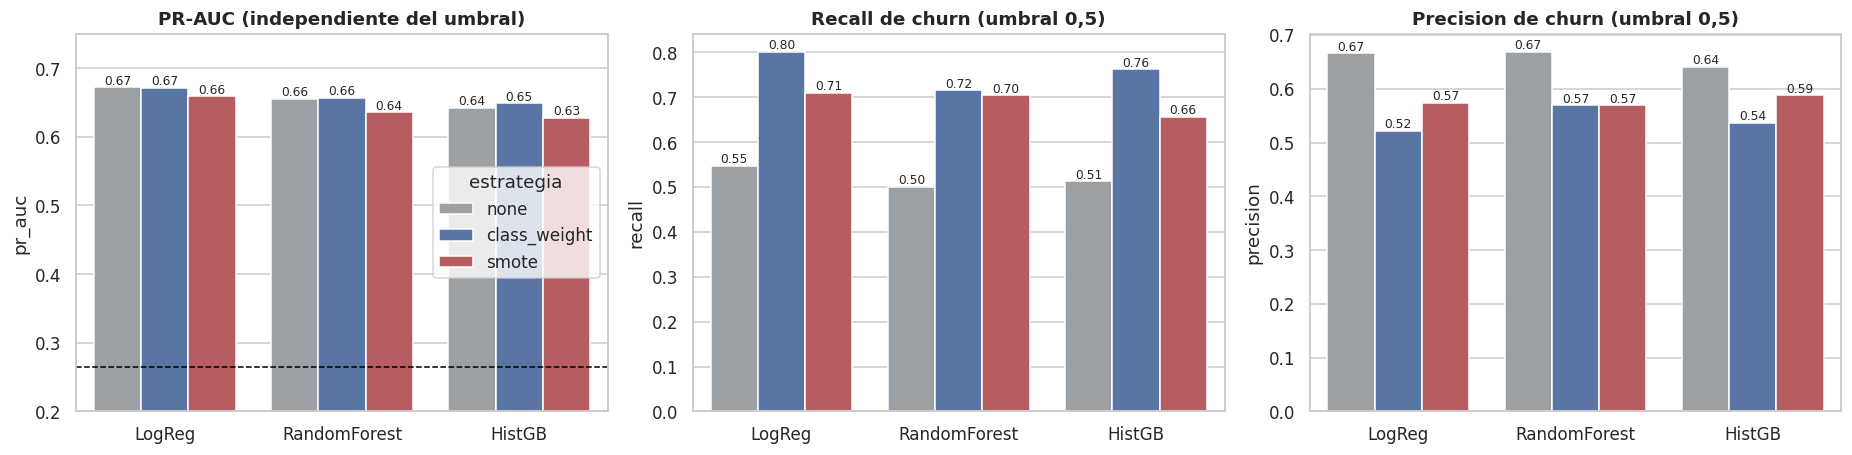

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
order = ["none", "class_weight", "smote"]
for ax, metric, title in zip(axes, ["pr_auc", "recall", "precision"],
                             ["PR-AUC (independiente del umbral)", "Recall de churn (umbral 0,5)", "Precision de churn (umbral 0,5)"]):
    sns.barplot(data=imb, x="modelo", y=metric, hue="estrategia", hue_order=order, ax=ax,
                palette=["#9aa0a6", "#4C72B0", "#C44E52"])
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel(metric)
    if metric == "pr_auc":
        ax.axhline(baseline["pr_auc"], ls="--", color="black", lw=1); ax.set_ylim(0.2, 0.75)
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha="center", va="bottom", fontsize=8)
axes[1].legend_.remove(); axes[2].legend_.remove()
plt.tight_layout(); savefig("13_estrategias_desbalance.png"); plt.show()

**Interpretación:**
- **PR-AUC casi no cambia** entre "sin tratamiento" y `class_weight` (LogReg 0,672 → 0,671; RF 0,656 → 0,657; HGB 0,643 → 0,649): `class_weight` **no mejora la capacidad de ordenar clientes por riesgo, solo desplaza el punto de operación**: el Recall sube (LogReg 0,55 → 0,80; RF 0,50 → 0,72; HGB 0,51 → 0,76) a costa de Precision (LogReg 0,67 → 0,52). Es el trade-off buscado, porque un falso negativo cuesta más que un falso positivo.
- **SMOTE empeora el PR-AUC en los tres modelos** (LogReg 0,659; RF 0,636; HGB 0,628) y no entrega más Recall que `class_weight`. Se descarta.
- **Primera señal de overfitting:** con parámetros por defecto, RF alcanza PR-AUC 0,865 en train frente a 0,656 en validación (brecha ≈ 0,21), y HGB sin tratamiento 0,82 frente a 0,64; la regresión logística tiene brecha ≈ 0,01. Esto motiva la regularización y el tuning de la sección siguiente.
- **Decisión:** usar `class_weight="balanced"` en los tres modelos, y en la etapa 5 ajustar el **umbral de decisión** con validación cruzada, que es la forma más directa de controlar el trade-off Recall/Precision.

### 4.3 Optimización de hiperparámetros con validación cruzada estratificada
- **Regresión Logística:** `GridSearchCV` sobre penalización (L1/L2) y fuerza de regularización `C`.
- **Random Forest y Gradient Boosting:** `RandomizedSearchCV`; el espacio de búsqueda solo contiene configuraciones que **limitan la complejidad** (`max_depth`, `min_samples_leaf`, `max_features`, regularización L2, `learning_rate` pequeño) y el boosting usa **early stopping**.
- Todos con `StratifiedKFold(5)`, **PR-AUC** como métrica de selección y `return_train_score=True` para medir la **brecha train–validación**.

**Criterio de selección anti-overfitting (regla del error estándar):** entre las configuraciones cuyo PR-AUC de validación queda a menos de **1 error estándar** de la mejor, se elige la de **menor brecha train–validación**. Así no se premia a un modelo que gana 0,001 de PR-AUC a costa de memorizar el entrenamiento.

In [35]:
searches = {}
for name, fn in [("LogReg", search_logreg), ("RandomForest", search_rf), ("HistGB", search_hgb)]:
    t0 = time.time()
    searches[name] = fn().fit(X_train, y_train)
    print(f"{name:13s} listo en {time.time() - t0:5.1f} s | configuraciones evaluadas: {len(searches[name].cv_results_['params'])}")

LogReg        listo en  22.6 s | configuraciones evaluadas: 16
RandomForest  listo en  96.9 s | configuraciones evaluadas: 12
HistGB        listo en  76.7 s | configuraciones evaluadas: 25


In [36]:
def summarize(name, search):
    r = pd.DataFrame(search.cv_results_)
    out = []
    for tag, i in [("mejor PR-AUC CV", int(search.best_index_)), ("parsimoniosa (1-SE)", pick_parsimonious(search))]:
        row = r.loc[i]
        d = {"modelo": name, "selección": tag}
        d.update({f"cv_{m}": row[f"mean_test_{m}"] for m in SCORING})
        d.update({f"std_{m}": row[f"std_test_{m}"] for m in SCORING})
        d["train_pr_auc"] = row["mean_train_pr_auc"]
        d["gap_pr_auc"] = row["mean_train_pr_auc"] - row["mean_test_pr_auc"]
        d["train_roc_auc"] = row["mean_train_roc_auc"]
        d["gap_roc_auc"] = row["mean_train_roc_auc"] - row["mean_test_roc_auc"]
        d["params"] = {k.replace("model__", ""): v for k, v in row["params"].items()}
        out.append(d)
    return out

summary = pd.DataFrame([r for n, s in searches.items() for r in summarize(n, s)])
pd.set_option("display.max_colwidth", 120)
summary[["modelo", "selección", "cv_pr_auc", "cv_roc_auc", "cv_recall", "cv_precision", "cv_f1",
         "train_pr_auc", "gap_pr_auc", "params"]].round(3)

,modelo,selección,cv_pr_auc,cv_roc_auc,cv_recall,cv_precision,cv_f1,train_pr_auc,gap_pr_auc,params
0,LogReg,mejor PR-AUC CV,0.671,0.849,0.803,0.523,0.633,0.679,0.007,"{'C': 3, 'penalty': 'l2'}"
1,LogReg,parsimoniosa (1-SE),0.667,0.848,0.795,0.527,0.634,0.670,0.003,"{'C': 0.01, 'penalty': 'l2'}"
2,RandomForest,mejor PR-AUC CV,0.661,0.847,0.764,0.549,0.639,0.772,0.111,"{'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 8}"
3,RandomForest,parsimoniosa (1-SE),0.659,0.846,0.801,0.523,0.633,0.690,0.031,"{'n_estimators': 200, 'min_samples_leaf': 40, 'max_features': 'sqrt', 'max_depth': 6}"
4,HistGB,mejor PR-AUC CV,0.661,0.848,0.810,0.521,0.634,0.691,0.030,"{'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'max_depth': 2, 'learning_rate': 0.1, 'l2_regularization': 10}"
5,HistGB,parsimoniosa (1-SE),0.658,0.847,0.809,0.518,0.632,0.683,0.025,"{'min_samples_leaf': 100, 'max_leaf_nodes': 8, 'max_depth': 2, 'learning_rate': 0.03, 'l2_regularization': 50}"


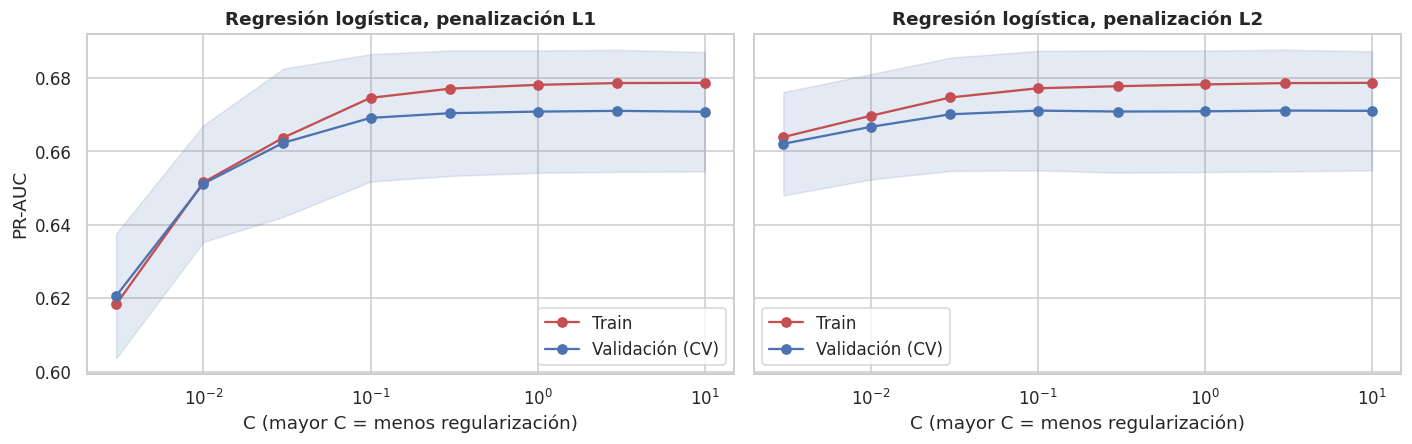

In [37]:
# Curva de validación de la regresión logística: efecto de la regularización (C)
r = pd.DataFrame(searches["LogReg"].cv_results_)
r["penalty"] = r["param_model__penalty"]; r["C"] = r["param_model__C"].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, pen in zip(axes, ["l1", "l2"]):
    s = r[r["penalty"] == pen].sort_values("C")
    ax.plot(s["C"], s["mean_train_pr_auc"], marker="o", color="#C44E52", label="Train")
    ax.plot(s["C"], s["mean_test_pr_auc"], marker="o", color="#4C72B0", label="Validación (CV)")
    ax.fill_between(s["C"], s["mean_test_pr_auc"] - s["std_test_pr_auc"], s["mean_test_pr_auc"] + s["std_test_pr_auc"],
                    color="#4C72B0", alpha=0.15)
    ax.set_xscale("log"); ax.set_title(f"Regresión logística, penalización {pen.upper()}")
    ax.set_xlabel("C (mayor C = menos regularización)"); ax.legend()
axes[0].set_ylabel("PR-AUC")
plt.tight_layout(); savefig("14_curva_validacion_logreg.png"); plt.show()

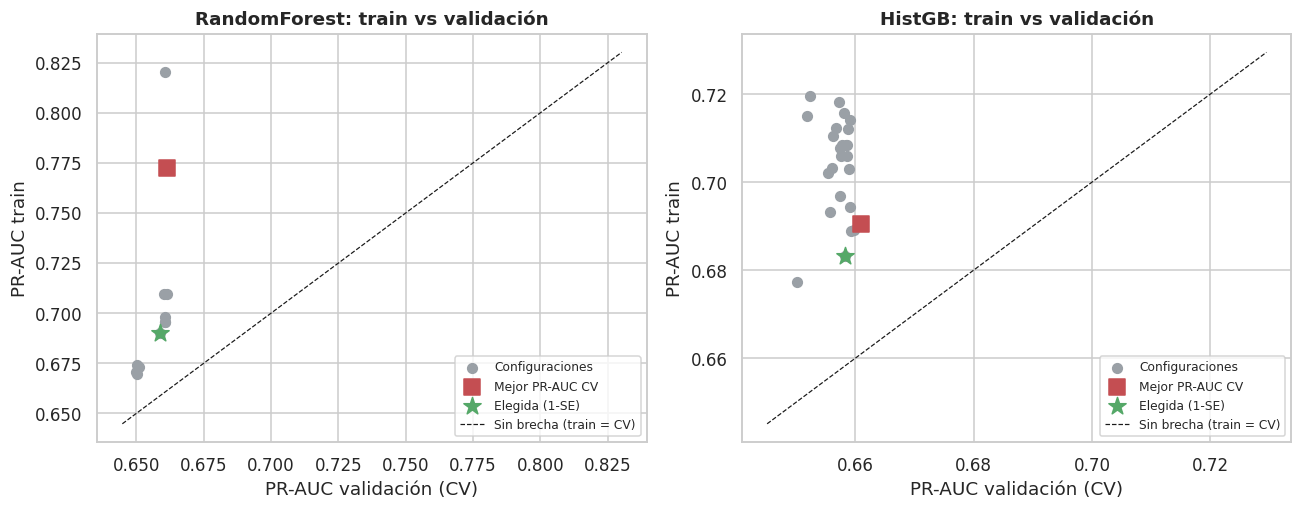

In [38]:
# Train vs validación para todas las configuraciones probadas en RF y Gradient Boosting
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=False)
for ax, name in zip(axes, ["RandomForest", "HistGB"]):
    s = searches[name]; r = pd.DataFrame(s.cv_results_); ip = pick_parsimonious(s)
    ax.scatter(r["mean_test_pr_auc"], r["mean_train_pr_auc"], color="#9aa0a6", s=40, label="Configuraciones")
    ax.scatter(r.loc[int(s.best_index_), "mean_test_pr_auc"], r.loc[int(s.best_index_), "mean_train_pr_auc"],
               color="#C44E52", s=110, marker="s", label="Mejor PR-AUC CV")
    ax.scatter(r.loc[ip, "mean_test_pr_auc"], r.loc[ip, "mean_train_pr_auc"], color="#55A868", s=140, marker="*", label="Elegida (1-SE)")
    lims = [r["mean_test_pr_auc"].min() - 0.005, r["mean_train_pr_auc"].max() + 0.01]
    ax.plot(lims, lims, "k--", lw=0.8, label="Sin brecha (train = CV)")
    ax.set_title(f"{name}: train vs validación"); ax.set_xlabel("PR-AUC validación (CV)"); ax.set_ylabel("PR-AUC train"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("15_train_vs_cv_candidatos.png"); plt.show()

**Interpretación del tuning y del control de overfitting**

- **Regresión logística (curva de validación):** con regularización extrema (L1, `C = 0,003`) train y validación quedan casi iguales y bajos (≈ 0,62): **underfitting**, el modelo es demasiado simple. Desde `C ≈ 0,1` la curva se aplana en PR-AUC ≈ 0,671 con una brecha train–validación de apenas ≈ 0,006: **no hay overfitting**. La mejor configuración por PR-AUC fue L2 con `C = 3` (0,671). La regla del error estándar eligió **L2 con `C = 0,01`** (0,667, brecha 0,003): cede 0,004 de PR-AUC, dentro del ruido entre folds (error estándar ≈ 0,008), a cambio de coeficientes más estables.
- **Random Forest:** la mejor configuración por PR-AUC (0,661; `min_samples_leaf = 5`, `max_depth = 8`) tiene una **brecha de 0,111** (train 0,772). La regla eligió `min_samples_leaf = 40`, `max_depth = 6`, 200 árboles: PR-AUC 0,659 y **brecha 0,031**. Se pierden 0,002 de PR-AUC y la brecha se reduce a la cuarta parte; con los parámetros por defecto de la sección 4.2 era ≈ 0,21.
- **Gradient Boosting:** el `early_stopping` y la profundidad máxima 2 ya aparecen en la mejor configuración. La elegida usa `learning_rate = 0,03`, 8 hojas, `min_samples_leaf = 100` y regularización L2 = 50: PR-AUC 0,658 y brecha 0,025.
- **Lectura global:** las tres familias convergen a un mismo techo (PR-AUC ≈ 0,66–0,67). En Random Forest las configuraciones más complejas suben el PR-AUC de train (hasta ≈ 0,82) sin mejorar el de validación (0,661), que es justamente la firma del overfitting (panel izquierdo de `15_train_vs_cv_candidatos.png`).

### 4.4 Modelos finales y comparación
Se reajusta con **todo el train** la configuración parsimoniosa de cada modelo y se guarda en `models/`. La comparación usa los resultados de validación cruzada (media ± desviación entre folds); **todavía no se usa el test**.

In [39]:
final_models = {}
for name, s in searches.items():
    final_models[name] = fit_selected(s, pick_parsimonious(s), X_train, y_train)
joblib.dump(final_models["LogReg"], MODELS / "logreg_tuned.joblib")
joblib.dump(final_models["RandomForest"], MODELS / "random_forest_tuned.joblib")
joblib.dump(final_models["HistGB"], MODELS / "hist_gradient_boosting_tuned.joblib")

sel = summary[summary["selección"] == "parsimoniosa (1-SE)"].set_index("modelo")
sel.drop(columns=["selección"]).to_csv(REPORTS / "cv_resultados_modelos_seleccionados.csv")

comp = pd.DataFrame({m: [f"{sel.loc[n, f'cv_{m}']:.3f} ± {sel.loc[n, f'std_{m}']:.3f}" for n in sel.index]
                     for m in SCORING}, index=sel.index)
comp["brecha PR-AUC (train-CV)"] = sel["gap_pr_auc"].round(3)
comp.loc["Línea base"] = [f"{baseline[m]:.3f}" for m in SCORING] + ["-"]
comp

,pr_auc,roc_auc,f1,recall,precision,brecha PR-AUC (train-CV)
modelo,,,,,,
LogReg,0.667 ± 0.014,0.848 ± 0.011,0.634 ± 0.019,0.795 ± 0.023,0.527 ± 0.017,0.003
RandomForest,0.659 ± 0.018,0.846 ± 0.010,0.633 ± 0.014,0.801 ± 0.015,0.523 ± 0.015,0.031
HistGB,0.658 ± 0.022,0.847 ± 0.012,0.632 ± 0.016,0.809 ± 0.025,0.518 ± 0.014,0.025
Línea base,0.265,0.500,0.000,0.000,0.000,-


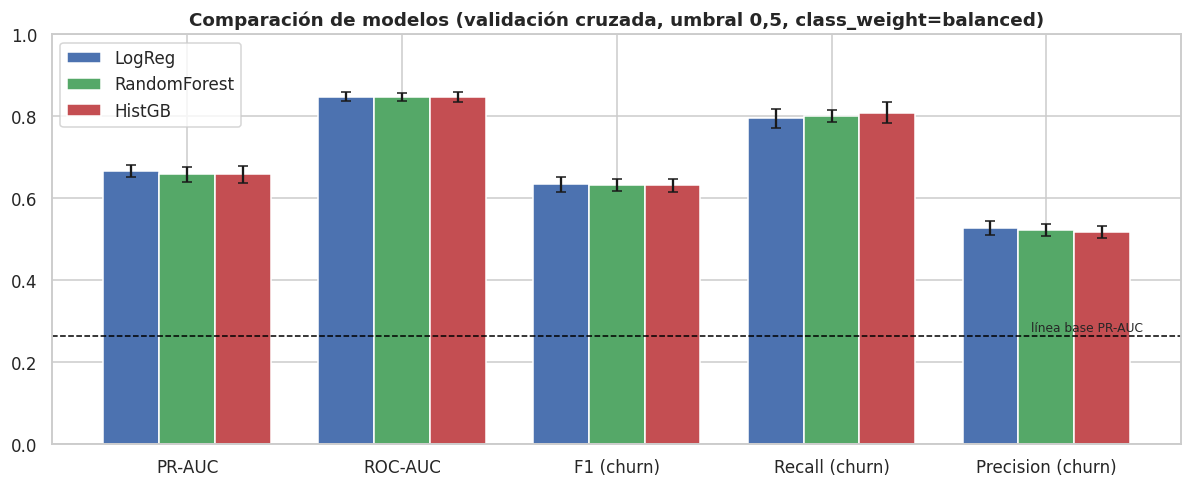

In [40]:
metrics = ["pr_auc", "roc_auc", "f1", "recall", "precision"]
fig, ax = plt.subplots(figsize=(11, 4.6))
w = 0.26
for i, (n, col) in enumerate(zip(sel.index, ["#4C72B0", "#55A868", "#C44E52"])):
    ax.bar(np.arange(len(metrics)) + (i - 1) * w, [sel.loc[n, f"cv_{m}"] for m in metrics], w,
           yerr=[sel.loc[n, f"std_{m}"] for m in metrics], color=col, label=n, capsize=3)
ax.set_xticks(range(len(metrics))); ax.set_xticklabels(["PR-AUC", "ROC-AUC", "F1 (churn)", "Recall (churn)", "Precision (churn)"])
ax.axhline(baseline["pr_auc"], ls="--", color="black", lw=1); ax.text(4.45, baseline["pr_auc"] + 0.01, "línea base PR-AUC", ha="right", fontsize=8)
ax.set_ylim(0, 1); ax.set_title("Comparación de modelos (validación cruzada, umbral 0,5, class_weight=balanced)"); ax.legend(loc="upper left")
plt.tight_layout(); savefig("16_comparacion_modelos_cv.png"); plt.show()

**Interpretación de la comparación (validación cruzada, umbral 0,5)**

| Modelo | PR-AUC | ROC-AUC | Recall | Precision | F1 | Brecha PR-AUC |
|---|---|---|---|---|---|---|
| Regresión logística | 0,667 ± 0,014 | 0,848 | 0,795 | 0,527 | 0,634 | 0,003 |
| Random Forest | 0,659 ± 0,018 | 0,846 | 0,801 | 0,523 | 0,633 | 0,031 |
| Gradient Boosting | 0,658 ± 0,022 | 0,847 | 0,809 | 0,518 | 0,632 | 0,025 |
| Línea base | 0,265 | 0,500 | 0 | 0 | 0 | – |

- **Los tres modelos superan ampliamente la línea base** (PR-AUC 0,66 frente a 0,265; ROC-AUC 0,85 frente a 0,50).
- **Entre ellos no hay diferencias estadísticamente relevantes:** la distancia entre modelos (≈ 0,01 de PR-AUC) es menor que la desviación entre folds (0,014–0,022). No es legítimo declarar un ganador solo por esa diferencia.
- **Implicancia:** la señal de churn en este dataset es mayormente **aditiva y casi lineal**, y las interacciones más importantes (fibra + contrato mensual, pago automático) ya están capturadas por las variables derivadas. Por eso modelos más complejos no aportan. Por **parsimonia e interpretabilidad**, la regresión logística es la candidata principal; Random Forest y Gradient Boosting se mantienen como alternativas para confirmar en test y para contrastar la importancia de variables.
- **En términos de negocio (umbral 0,5):** el modelo detecta ≈ 80 % de los churners (Recall) y ≈ 52 % de las alertas son churners reales (Precision): por cada 100 clientes alertados, ≈ 52 realmente se irían. La Precision está apenas sobre la meta de 0,50, por lo que el **ajuste del umbral** (etapa 5) será clave.
- **KPIs en validación cruzada:** Recall ≥ 0,75, Precision ≥ 0,50, F1 ≥ 0,60, ROC-AUC ≥ 0,83 y brecha ≤ 0,05 se cumplen en los tres modelos. Es evidencia de validación, **no de test**: se confirmará en la etapa 5.

### 4.5 Aprendizaje no supervisado: segmentación de clientes con K-Means
**Para qué sirve en este negocio:** el modelo supervisado dice *quién* tiene riesgo; la segmentación dice *qué tipo de cliente es* y por tanto *qué acción de retención corresponde*. Es el puente entre predicción y campaña.

**Diseño metodológico**
- **No se usa la variable objetivo** para formar los clusters: `Churn` solo se usa después, para perfilar cada segmento.
- Se ajusta **solo con train** sobre la matriz preprocesada y estandarizada (las mismas 27 variables), y luego se asignan los clientes de test al centroide más cercano.
- **Elección de k:** inercia (codo), *silhouette*, índice de Davies-Bouldin y Calinski-Harabasz, comparando además la entrada con las 27 variables frente a los 15 componentes PCA (90 % de varianza).

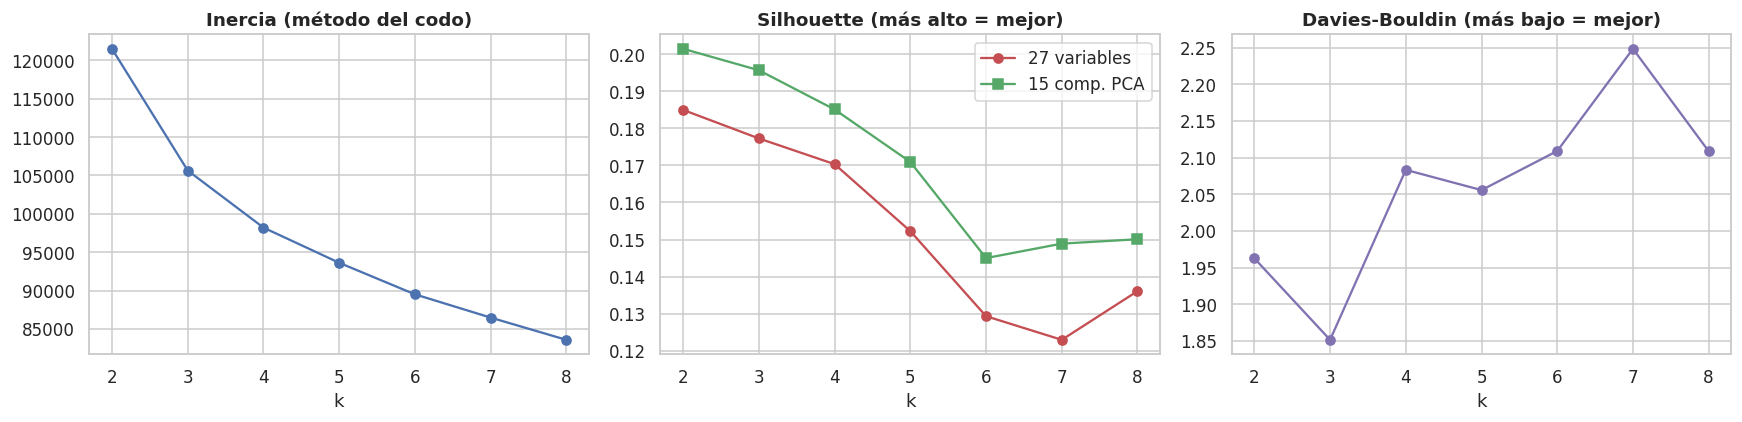

,inercia,silhouette_27var,silhouette_PCA15,davies_bouldin,calinski_harabasz
k,,,,,
2,121495.415,0.185,0.201,1.963,1419.531
3,105650.399,0.177,0.196,1.852,1238.326
4,98217.191,0.170,0.185,2.083,1029.901
5,93637.778,0.152,0.171,2.056,878.880
6,89530.133,0.129,0.145,2.109,786.876
7,86500.405,0.123,0.149,2.249,711.423
8,83603.182,0.136,0.150,2.109,658.663


In [41]:
Z_pca_train = pca_pipe.named_steps["pca"].transform(Z_train)   # entrada alternativa: 15 componentes PCA
rows = []
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Z_train)
    kp = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Z_pca_train)
    rows.append({"k": k, "inercia": km.inertia_,
                 "silhouette_27var": silhouette_score(Z_train, km.labels_),
                 "silhouette_PCA15": silhouette_score(Z_pca_train, kp.labels_),
                 "davies_bouldin": davies_bouldin_score(Z_train, km.labels_),
                 "calinski_harabasz": calinski_harabasz_score(Z_train, km.labels_)})
kdf = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(kdf.index, kdf["inercia"], marker="o", color="#4C72B0"); axes[0].set_title("Inercia (método del codo)")
axes[1].plot(kdf.index, kdf["silhouette_27var"], marker="o", label="27 variables", color="#C44E52")
axes[1].plot(kdf.index, kdf["silhouette_PCA15"], marker="s", label="15 comp. PCA", color="#55A868"); axes[1].legend(); axes[1].set_title("Silhouette (más alto = mejor)")
axes[2].plot(kdf.index, kdf["davies_bouldin"], marker="o", color="#8172B2"); axes[2].set_title("Davies-Bouldin (más bajo = mejor)")
for a in axes: a.set_xlabel("k")
plt.tight_layout(); savefig("17_kmeans_seleccion_k.png"); plt.show()
kdf.round(3)

**Interpretación de la elección de k:**
- La inercia baja de forma gradual, **sin un codo marcado**, y el *silhouette* es bajo en todos los k (≈ 0,13–0,20): los clientes forman una **nube continua más que grupos nítidamente separados**, algo esperable con muchas variables binarias. Esto se declara abiertamente: los segmentos son una herramienta de **descripción y accionabilidad**, no clusters "naturales" perfectos.
- El *silhouette* favorece k = 2–3 por muy poco (0,185 / 0,177 frente a 0,170 de k = 4), pero con k = 2–3 el grupo de **clientes sin internet y bajo costo** queda mezclado con otros perfiles. Con **k = 4** ese grupo se separa y los cuatro segmentos tienen perfiles de negocio distintos y accionables.
- Se usan las **27 variables** (en lugar de los 15 componentes PCA) para no perder información y mantener interpretable cada segmento, aunque la entrada PCA da un *silhouette* algo mayor.

In [42]:
K = 4
km = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(Z_train)
seg_train = km.labels_
seg_test = km.predict(scaler_pca.transform(X_test_p))

# --- Estabilidad: ¿los clusters cambian con otra semilla? (Adjusted Rand Index, 1 = idénticos)
ari = [adjusted_rand_score(seg_train, KMeans(K, n_init=10, random_state=s).fit(Z_train).labels_) for s in range(1, 6)]
print("ARI entre semillas (5 corridas):", np.round(ari, 3))

# --- Perfilado (aquí SÍ se usa Churn, solo para describir)
def profile(Xd, y_, seg):
    d = Xd.assign(segment=seg, churn=np.asarray(y_))
    g = d.groupby("segment")
    out = pd.DataFrame({
        "clientes": g.size(),
        "% clientes": g.size() / len(d) * 100,
        "% churn": g["churn"].mean() * 100,
        "tenure (meses)": g["tenure"].mean(),
        "cargo mensual ($)": g["MonthlyCharges"].mean(),
        "n servicios": g["n_services"].mean(),
        "% senior": g["SeniorCitizen"].mean() * 100,
        "% fibra": g["InternetService"].apply(lambda s: (s == "Fiber optic").mean() * 100),
        "% sin internet": g["InternetService"].apply(lambda s: (s == "No").mean() * 100),
        "% contrato mensual": g["Contract"].apply(lambda s: (s == "Month-to-month").mean() * 100),
        "% pago automático": g["auto_payment"].mean() * 100,
    })
    return out

prof_train = profile(X_train, y_train, seg_train)

# Nombres asignados por reglas sobre el perfil (robusto al orden arbitrario de los clusters)
names, left = {}, set(prof_train.index)
c = prof_train["% sin internet"].idxmax(); names[c] = "Sin internet · bajo costo"; left.discard(c)
c = prof_train.loc[list(left), "% fibra"].idxmax(); names[c] = "Fibra + contrato mensual · alto riesgo"; left.discard(c)
c = prof_train.loc[list(left), "tenure (meses)"].idxmax(); names[c] = "Leales de alto valor"; left.discard(c)
for c in left: names[c] = "Mensuales DSL · valor medio"
prof_train.index = [names[i] for i in prof_train.index]
prof_train.round(1)

ARI entre semillas (5 corridas): [1.    0.999 0.998 0.999 0.999]


,clientes,% clientes,% churn,tenure (meses),cargo mensual ($),n servicios,% senior,% fibra,% sin internet,% contrato mensual,% pago automático
Mensuales DSL · valor medio,1127,20.0,28.6,17.1,48.8,2.4,11.4,0.7,0.0,79.1,30.1
Leales de alto valor,1668,29.6,10.2,56.8,87.4,5.7,15.4,51.5,0.0,13.0,70.7
Fibra + contrato mensual · alto riesgo,1615,28.7,56.6,19.8,86.0,3.3,30.5,99.9,0.0,97.2,24.9
Sin internet · bajo costo,1224,21.7,7.3,30.3,21.4,1.2,3.4,0.2,99.2,34.6,43.8


In [43]:
# Validación fuera de muestra: ¿el riesgo por segmento se mantiene en clientes que no se usaron para formar los clusters?
prof_test = profile(X_test, y_test, seg_test)
prof_test.index = [names[i] for i in prof_test.index]
cmp = pd.DataFrame({"% clientes (train)": prof_train["% clientes"], "% clientes (test)": prof_test["% clientes"],
                    "% churn (train)": prof_train["% churn"], "% churn (test)": prof_test["% churn"]})
# Concentración de churners: qué parte del total de churners cae en cada segmento (train)
ch = pd.Series(y_train.values).groupby(pd.Series([names[i] for i in seg_train])).sum()
cmp["% de todos los churners (train)"] = (ch / ch.sum() * 100).reindex(cmp.index)
cmp.round(1)

,% clientes (train),% clientes (test),% churn (train),% churn (test),% de todos los churners (train)
Mensuales DSL · valor medio,20.0,21.0,28.6,29.4,21.5
Leales de alto valor,29.6,27.8,10.2,10.7,11.4
Fibra + contrato mensual · alto riesgo,28.7,28.8,56.6,54.2,61.1
Sin internet · bajo costo,21.7,22.4,7.3,7.9,6.0


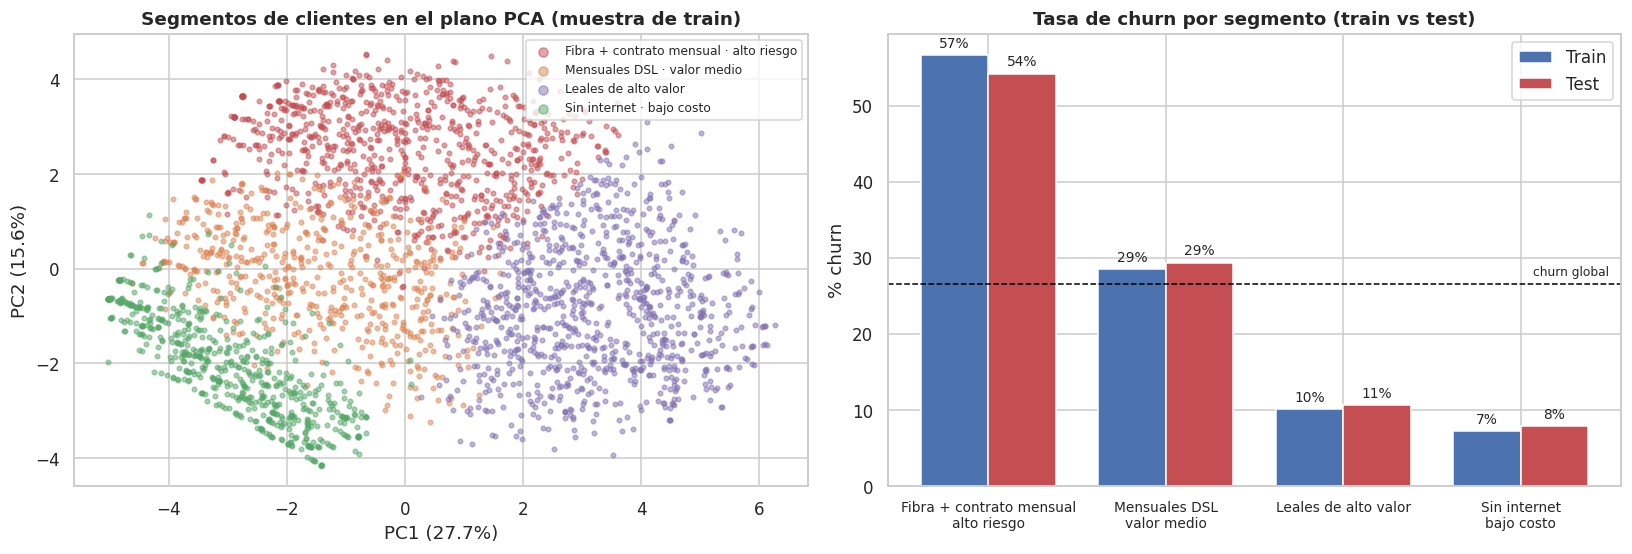

In [44]:
order = prof_train.sort_values("% churn", ascending=False).index.tolist()
seg_colors = dict(zip(order, ["#C44E52", "#DD8452", "#8172B2", "#55A868"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
# (a) PCA 2D coloreado por segmento
P2 = pca2.transform(Z_train)
samp = np.random.RandomState(RANDOM_STATE).choice(len(P2), size=3000, replace=False)
for nm in order:
    m = np.array([names[i] for i in seg_train])[samp] == nm
    axes[0].scatter(P2[samp][m, 0], P2[samp][m, 1], s=9, alpha=0.5, color=seg_colors[nm], label=nm)
axes[0].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]*100:.1f}%)"); axes[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].set_title("Segmentos de clientes en el plano PCA (muestra de train)"); axes[0].legend(fontsize=8, markerscale=2)
# (b) churn por segmento: train vs test
x = np.arange(len(order)); w = 0.38
axes[1].bar(x - w/2, cmp.loc[order, "% churn (train)"], w, color="#4C72B0", label="Train")
axes[1].bar(x + w/2, cmp.loc[order, "% churn (test)"], w, color="#C44E52", label="Test")
axes[1].axhline(y.mean() * 100, ls="--", color="black", lw=1); axes[1].text(len(order) - 0.5, y.mean() * 100 + 1.2, "churn global", ha="right", fontsize=8)
for xi, nm in zip(x, order):
    axes[1].text(xi - w/2, cmp.loc[nm, "% churn (train)"] + 1, f"{cmp.loc[nm, '% churn (train)']:.0f}%", ha="center", fontsize=9)
    axes[1].text(xi + w/2, cmp.loc[nm, "% churn (test)"] + 1, f"{cmp.loc[nm, '% churn (test)']:.0f}%", ha="center", fontsize=9)
axes[1].set_xticks(x); axes[1].set_xticklabels([o.replace(" · ", "\n") for o in order], fontsize=9)
axes[1].set_ylabel("% churn"); axes[1].set_title("Tasa de churn por segmento (train vs test)"); axes[1].legend()
plt.tight_layout(); savefig("18_kmeans_segmentos.png"); plt.show()

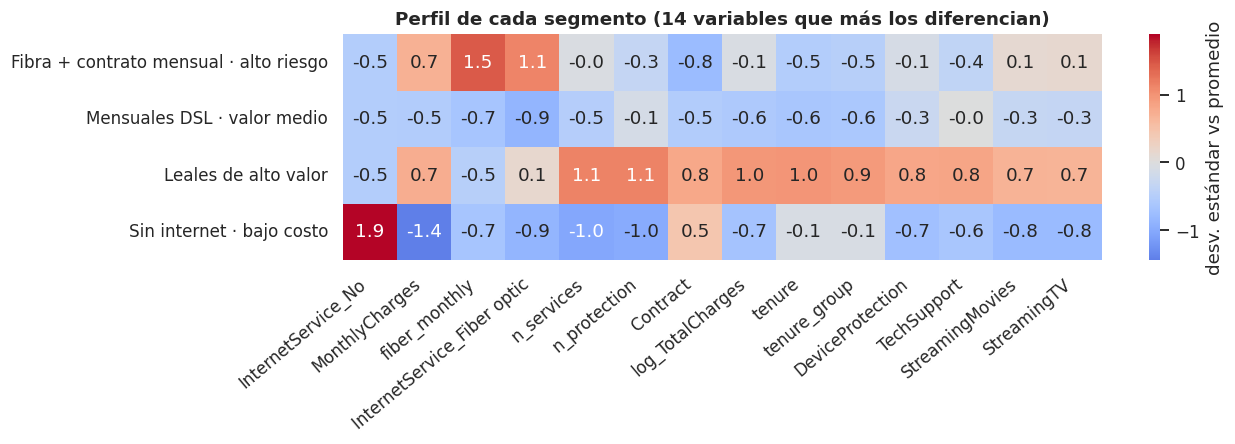

In [45]:
# Mapa de calor: perfil estandarizado de cada segmento (valores > 0 = por sobre el promedio de la base)
Zdf = pd.DataFrame(Z_train, columns=X_train_p.columns)
Zdf["segment"] = [names[i] for i in seg_train]
cm = Zdf.groupby("segment").mean()
top_feats = cm.var().sort_values(ascending=False).head(14).index
fig, ax = plt.subplots(figsize=(12, 4.2))
sns.heatmap(cm.loc[order, top_feats], annot=True, fmt=".1f", cmap="coolwarm", center=0, ax=ax, cbar_kws={"label": "desv. estándar vs promedio"})
ax.set_title("Perfil de cada segmento (14 variables que más los diferencian)"); ax.set_ylabel("")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); savefig("19_perfil_segmentos.png"); plt.show()

# Guardar el modelo de segmentación (preprocesador -> escalador -> K-Means) y los nombres
seg_pipe = Pipeline([("pre", preprocessor), ("scaler", scaler_pca), ("kmeans", km)])
joblib.dump(seg_pipe, MODELS / "kmeans_segmentation.joblib")
import json
(REPORTS / "segment_names.json").write_text(json.dumps({int(k): v for k, v in names.items()}, ensure_ascii=False, indent=2), encoding="utf-8")
prof_train.round(2).to_csv(REPORTS / "perfil_segmentos_train.csv")

#### Ingreso mensual en riesgo por segmento
Además del % de churn, interesa **cuánto ingreso mensual** se pierde en cada segmento (suma del cargo mensual de los clientes que abandonan, en train).

In [46]:
seg_nombre_train = pd.Series([names[i] for i in seg_train], index=X_train.index)
es_churn = (y_train.values == 1)
ingreso_seg = X_train.loc[es_churn, "MonthlyCharges"].groupby(seg_nombre_train[es_churn]).agg(["sum", "mean", "size"])
ingreso_seg.columns = ["ingreso mensual en riesgo ($)", "cargo medio del churner ($)", "churners"]
ingreso_seg["% del ingreso en riesgo"] = ingreso_seg["ingreso mensual en riesgo ($)"] / ingreso_seg["ingreso mensual en riesgo ($)"].sum() * 100
ingreso_seg.sort_values("ingreso mensual en riesgo ($)", ascending=False).round(1)

,ingreso mensual en riesgo ($),cargo medio del churner ($),churners,% del ingreso en riesgo
Fibra + contrato mensual · alto riesgo,78739.6,86.1,914,70.4
Leales de alto valor,16345.4,96.1,170,14.6
Mensuales DSL · valor medio,14977.8,46.5,322,13.4
Sin internet · bajo costo,1853.2,20.8,89,1.7


**Interpretación de los segmentos**

| Segmento | % clientes | % churn (train → test) | Perfil | Acción sugerida |
|---|---|---|---|---|
| **Fibra + contrato mensual · alto riesgo** | 28,7 % | 56,6 % → 54,2 % | 20 meses de antigüedad, \$86/mes, 99,9 % fibra, 97 % contrato mensual, 25 % pago automático, 30 % senior | Incentivos para migrar a contrato de 1–2 años, pago automático, paquete de seguridad/soporte; revisar calidad/precio de la fibra |
| **Mensuales DSL · valor medio** | 20,0 % | 28,6 % → 29,4 % | 17 meses, \$49/mes, 2,4 servicios, 79 % contrato mensual | Onboarding reforzado en el primer año, venta cruzada de protección/soporte, oferta de contrato anual |
| **Leales de alto valor** | 29,6 % | 10,2 % → 10,7 % | 57 meses, \$87/mes, 5,7 servicios, 13 % contrato mensual, 71 % pago automático | Proteger la relación con fidelización; **evitar descuentos masivos** que regalen margen a clientes que ya se quedan |
| **Sin internet · bajo costo** | 21,7 % | 7,3 % → 7,9 % | \$21/mes, 1,2 servicios, 99 % sin internet | Baja prioridad de retención |

- **Concentración del riesgo:** el segmento *Fibra + contrato mensual* es el 28,7 % de los clientes pero reúne el **61,1 % de todos los churners**; junto con *Mensuales DSL* acumulan ≈ 83 %. Focalizar la retención ahí es más eficiente que una campaña masiva.
- **Concentración del ingreso en riesgo:** el segmento *Fibra + contrato mensual* reúne el **70,4 % del ingreso mensual en riesgo** (más que su 61,1 % de los churners, porque sus clientes pagan más: cargo medio de \$86 entre quienes se van), mientras que los *Leales de alto valor* aportan solo el 14,6 %.
- **Los segmentos generalizan:** la proporción de clientes y la tasa de churn por segmento en test (clientes que no se usaron para formar los clusters) difieren a lo más 2,4 puntos de las de train, y los clusters son prácticamente idénticos entre semillas (ARI ≈ 0,998–1,0).
- **Matiz importante:** el riesgo no lo da la fibra por sí sola (el segmento de leales también tiene ≈ 52 % de clientes con fibra), sino la **combinación fibra + contrato mensual**, coherente con el heatmap del EDA. K-Means en gran parte **redescubre** la estructura contrato–internet ya vista y aporta una partición accionable de la base. No es un descubrimiento independiente.
- **Limitación:** el *silhouette* es bajo (0,17), así que los segmentos son una herramienta de descripción y priorización, no grupos naturalmente separados. Los nombres se asignaron por reglas sobre el perfil, después de formar los clusters.

### 4.6 Resumen de la etapa de modelado
| Control | Cómo se cumple |
|---|---|
| Test intacto | Toda selección con validación cruzada estratificada sobre train |
| Preprocesamiento sin leakage en CV | Preprocesador dentro del `Pipeline` (se reajusta en cada fold) |
| SMOTE sin contaminar validación | Solo dentro del pipeline, sobre folds de entrenamiento (y descartado por no mejorar) |
| Control de overfitting | Espacios de búsqueda con `max_depth`, `min_samples_leaf`, L1/L2, early stopping; regla del error estándar; brecha train–CV reportada |
| Clustering sin usar el target | `Churn` solo se usa para perfilar los segmentos, no para formarlos |
| Estabilidad de los segmentos | ARI entre semillas y consistencia del churn por segmento en test |

**Artefactos:** `models/logreg_tuned.joblib`, `random_forest_tuned.joblib`, `hist_gradient_boosting_tuned.joblib`, `kmeans_segmentation.joblib`, `reports/cv_resultados_modelos_seleccionados.csv`, `reports/segment_names.json`, `reports/perfil_segmentos_train.csv` y los gráficos `13` a `19`.

**Siguiente (etapa 5, Evaluation):** evaluación **única** sobre test, matrices de confusión, curvas ROC/PR, ajuste del umbral, curvas de aprendizaje, importancia de variables / SHAP e interpretación de negocio.

## 5. Evaluation
Hasta aquí el **test no se había tocado**. En esta etapa se usa **una sola vez**, con modelos y umbrales decididos previamente con validación cruzada sobre train.

**Qué significa cada métrica en el contexto del churn**
| Métrica | Pregunta de negocio que responde | Costo del error asociado |
|---|---|---|
| **Recall** (churn) | De los clientes que realmente se iban, ¿a cuántos detecté? | Su baja = **falsos negativos**: ingresos recurrentes perdidos |
| **Precision** (churn) | De los clientes que alerté, ¿cuántos realmente se iban? | Su baja = **falsos positivos**: ofertas de retención gastadas en clientes que se quedaban |
| **F1** | Equilibrio entre ambos | Resumen a un umbral dado |
| **ROC-AUC** | Probabilidad de que un churner reciba mayor riesgo que un no-churner | Mide el ordenamiento, no depende del umbral |
| **PR-AUC** | Calidad del ranking sobre la clase minoritaria | Más exigente que ROC-AUC con desbalance (línea base ≈ 0,265) |
| **Matriz de confusión** | Cuántos aciertos y errores de cada tipo hay | Permite valorizar FN y FP |
| **Accuracy** | % de aciertos totales | **Engañosa** aquí: "nunca hay churn" acierta ≈ 73,5 % |

In [47]:
from sklearn.model_selection import cross_val_predict, learning_curve
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (precision_recall_curve, roc_curve, roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score, accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
import shap

MODEL_COLORS = {"LogReg": "#4C72B0", "RandomForest": "#55A868", "HistGB": "#C44E52"}
MODEL_LABEL = {"LogReg": "Regresión logística", "RandomForest": "Random Forest", "HistGB": "Gradient Boosting"}
sel_cv = pd.read_csv(REPORTS / "cv_resultados_modelos_seleccionados.csv", index_col="modelo")
yt = y_test.values

### 5.1 Elección del umbral de decisión (usando solo train)
Con `class_weight="balanced"` los modelos ya están sesgados hacia detectar churn, pero el umbral 0,5 no tiene por qué ser el mejor para el negocio. El umbral se elige con las **predicciones fuera de muestra (OOF) de la validación cruzada sobre train**: cada cliente se predice con un modelo que no lo vio. Así el test sigue intacto.

**Criterio:** minimizar el costo esperado `R × FN + 1 × FP`, donde **R = costo de perder un churner / costo de una oferta innecesaria**. Se usa **R = 5 como supuesto ilustrativo** (un churner no detectado cuesta cinco veces una oferta desperdiciada) y se muestra la sensibilidad a R = 2, 3, 5 y 10. En una aplicación real, R debe calibrarse con datos de la empresa: `R ≈ (probabilidad de éxito de la oferta × valor del cliente) / costo de la oferta`.

In [48]:
oof = {n: cross_val_predict(clone(m), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
       for n, m in final_models.items()}
y_tr = y_train.values
thr_grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
RATIOS, R_BASE = [2, 3, 5, 10], 5

def expected_cost(y_true, p, R):
    out = []
    for t in thr_grid:
        pred = p >= t
        fn = ((~pred) & (y_true == 1)).sum(); fp = (pred & (y_true == 0)).sum()
        out.append(R * fn + fp)
    return np.array(out)

rows, chosen_thr = [], {}
for n, p in oof.items():
    for R in RATIOS:
        t = thr_grid[int(np.argmin(expected_cost(y_tr, p, R)))]
        pred = p >= t
        rows.append({"modelo": n, "R": R, "umbral óptimo": t, "recall (OOF)": recall_score(y_tr, pred),
                     "precision (OOF)": precision_score(y_tr, pred), "% alertados": pred.mean() * 100})
        if R == R_BASE:
            chosen_thr[n] = float(t)

def kpi_threshold(y_true, p, R=R_BASE, min_precision=0.50):
    # Menor costo esperado (R) entre los umbrales que cumplen el KPI Precision >= 0,50 (en OOF de train)
    costs = expected_cost(y_true, p, R); feas = []
    for t, c in zip(thr_grid, costs):
        pred = p >= t
        if pred.sum() > 0 and precision_score(y_true, pred) >= min_precision:
            feas.append((c, t))
    return float(min(feas)[1]) if feas else 0.5

thr_kpi = {n: kpi_threshold(y_tr, p) for n, p in oof.items()}
for n, p in oof.items():
    pred = p >= thr_kpi[n]
    rows.append({"modelo": n, "R": "5 + Precision>=0,5 (KPI)", "umbral óptimo": thr_kpi[n], "recall (OOF)": recall_score(y_tr, pred),
                 "precision (OOF)": precision_score(y_tr, pred), "% alertados": pred.mean() * 100})
thr_table = pd.DataFrame(rows)
print("Umbral de costo mínimo (R = 5):", chosen_thr)
print("Umbral con restricción de KPI (Precision >= 0,50):", thr_kpi)
thr_table.round(3)

Umbral de costo mínimo (R = 5): {'LogReg': 0.34, 'RandomForest': 0.33, 'HistGB': 0.42}
Umbral con restricción de KPI (Precision >= 0,50): {'LogReg': 0.47, 'RandomForest': 0.46, 'HistGB': 0.46}


,modelo,R,umbral óptimo,recall (OOF),precision (OOF),% alertados
0,LogReg,2,0.53,0.775,0.548,37.540
1,LogReg,3,0.52,0.784,0.542,38.410
2,LogReg,5,0.34,0.913,0.442,54.846
3,LogReg,10,0.21,0.962,0.377,67.678
4,RandomForest,2,0.55,0.753,0.554,36.031
5,RandomForest,3,0.52,0.787,0.535,39.013
6,RandomForest,5,0.33,0.902,0.442,54.224
7,RandomForest,10,0.23,0.959,0.379,67.039
8,HistGB,2,0.63,0.680,0.590,30.547
9,HistGB,3,0.45,0.848,0.499,45.101


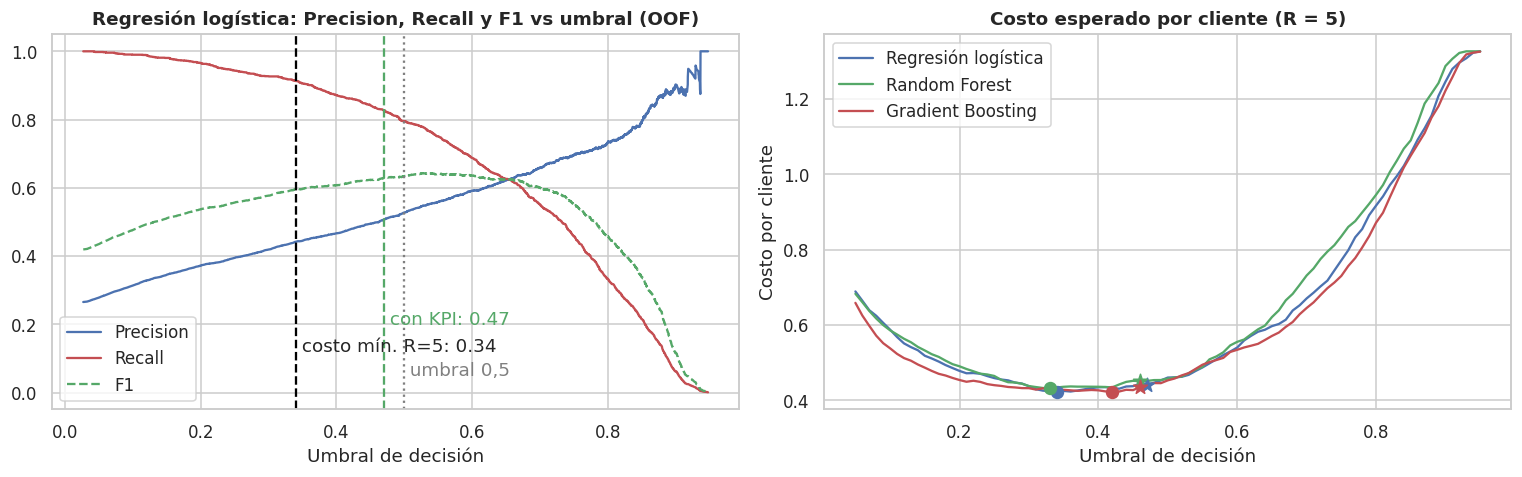

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
p = oof["LogReg"]
prec, rec, thr_pr = precision_recall_curve(y_tr, p)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
axes[0].plot(thr_pr, prec[:-1], label="Precision", color="#4C72B0")
axes[0].plot(thr_pr, rec[:-1], label="Recall", color="#C44E52")
axes[0].plot(thr_pr, f1[:-1], label="F1", color="#55A868", ls="--")
axes[0].axvline(0.5, color="gray", ls=":"); axes[0].text(0.5, 0.05, " umbral 0,5", color="gray")
axes[0].axvline(chosen_thr["LogReg"], color="black", ls="--"); axes[0].text(chosen_thr["LogReg"], 0.12, f" costo mín. R=5: {chosen_thr['LogReg']:.2f}")
axes[0].axvline(thr_kpi["LogReg"], color="#55A868", ls="--"); axes[0].text(thr_kpi["LogReg"], 0.20, f" con KPI: {thr_kpi['LogReg']:.2f}", color="#55A868")
axes[0].set_title("Regresión logística: Precision, Recall y F1 vs umbral (OOF)")
axes[0].set_xlabel("Umbral de decisión"); axes[0].legend()
for n, p in oof.items():
    c = expected_cost(y_tr, p, R_BASE)
    axes[1].plot(thr_grid, c / len(y_tr), color=MODEL_COLORS[n], label=MODEL_LABEL[n])
    axes[1].scatter(chosen_thr[n], c.min() / len(y_tr), color=MODEL_COLORS[n], s=60, zorder=5)
    axes[1].scatter(thr_kpi[n], c[list(thr_grid).index(thr_kpi[n])] / len(y_tr), color=MODEL_COLORS[n], s=90, marker="*", zorder=6)
axes[1].set_title("Costo esperado por cliente (R = 5)")
axes[1].set_xlabel("Umbral de decisión"); axes[1].set_ylabel("Costo por cliente"); axes[1].legend()
plt.tight_layout(); savefig("20_seleccion_umbral.png"); plt.show()

**Interpretación y decisión del umbral**

- El costo esperado es **muy plano** entre umbrales ≈ 0,25 y 0,50 (panel derecho): afinar el umbral al milímetro importa menos que tener un buen ranking de clientes.
- El umbral de **costo mínimo con R = 5** es 0,34 para la regresión logística: en OOF logra Recall 0,91, pero con **Precision 0,44** y alertando al 55 % de la base. Esa Precision queda **bajo la meta de 0,50** definida en la sección 1.
- Se adopta como **punto de operación final** el umbral de **costo mínimo entre los que cumplen Precision ≥ 0,50**: **0,47** para la regresión logística (OOF: Recall 0,83, Precision 0,51, 43 % de clientes alertados). Todo se calcula solo con train.
- **Transparencia:** la decisión de pasar del umbral de costo mínimo al umbral con restricción de KPI se tomó después de una primera corrida exploratoria en la que ya se habían visto los resultados de test del umbral R = 5 (Precision 0,44). La regla en sí solo usa datos de train, pero por honestidad metodológica se reportan los tres puntos de operación.
- Con `class_weight="balanced"` las probabilidades **no están calibradas** por construcción: sirven para **ordenar** clientes y compararlos con un umbral, no para leerlas como "probabilidad real de churn".

### 5.2 Evaluación final en el conjunto de test
Primera evaluación formal sobre los 1.409 clientes de test. Se reportan tres puntos de operación, todos definidos solo con train: umbral 0,5, umbral de costo mínimo (R = 5) y **umbral con restricción de KPI** (costo mínimo entre los umbrales con Precision ≥ 0,50), que es el punto de operación final.

In [50]:
proba_test = {n: m.predict_proba(X_test)[:, 1] for n, m in final_models.items()}

def metrics_at(y_true, p, t):
    pred = p >= t
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred),
            "recall": recall_score(y_true, pred), "f1": f1_score(y_true, pred),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

rows = []
for n, p in proba_test.items():
    for lab, t in [("umbral 0,5", 0.5), ("costo mínimo R=5", chosen_thr[n]), ("con restricción de KPI", thr_kpi[n])]:
        rows.append({"modelo": n, "punto de operación": lab, "umbral": t,
                     "ROC-AUC": roc_auc_score(yt, p), "PR-AUC": average_precision_score(yt, p),
                     **metrics_at(yt, p, t)})
test_res = pd.DataFrame(rows)
test_res.to_csv(REPORTS / "resultados_test.csv", index=False)
test_res.round(3)

,modelo,punto de operación,umbral,ROC-AUC,PR-AUC,accuracy,precision,recall,f1,TP,FP,FN,TN
0,LogReg,"umbral 0,5",0.50,0.844,0.651,0.749,0.517,0.794,0.627,297,277,77,758
1,LogReg,costo mínimo R=5,0.34,0.844,0.651,0.670,0.441,0.909,0.594,340,431,34,604
2,LogReg,con restricción de KPI,0.47,0.844,0.651,0.727,0.491,0.824,0.615,308,319,66,716
3,RandomForest,"umbral 0,5",0.50,0.844,0.652,0.755,0.526,0.797,0.633,298,269,76,766
4,RandomForest,costo mínimo R=5,0.33,0.844,0.652,0.671,0.442,0.906,0.594,339,428,35,607
5,RandomForest,con restricción de KPI,0.46,0.844,0.652,0.742,0.509,0.813,0.626,304,293,70,742
6,HistGB,"umbral 0,5",0.50,0.845,0.661,0.742,0.508,0.802,0.622,300,290,74,745
7,HistGB,costo mínimo R=5,0.42,0.845,0.661,0.717,0.481,0.842,0.612,315,340,59,695
8,HistGB,con restricción de KPI,0.46,0.845,0.661,0.732,0.497,0.821,0.619,307,311,67,724


In [51]:
# Incertidumbre: intervalos de confianza bootstrap (1.000 remuestreos del test) y diferencias pareadas vs regresión logística
rng = np.random.RandomState(RANDOM_STATE)
B = 1000
boot = {n: {"pr": [], "roc": []} for n in proba_test}
for _ in range(B):
    ix = rng.randint(0, len(yt), len(yt))
    if yt[ix].sum() == 0:
        continue
    for n, p in proba_test.items():
        boot[n]["pr"].append(average_precision_score(yt[ix], p[ix]))
        boot[n]["roc"].append(roc_auc_score(yt[ix], p[ix]))
rows = []
for n in proba_test:
    for m, lab in [("pr", "PR-AUC"), ("roc", "ROC-AUC")]:
        a = np.array(boot[n][m]); lo, hi = np.percentile(a, [2.5, 97.5])
        row = {"modelo": n, "métrica": lab, "estimado": np.mean(a), "IC95%": f"[{lo:.3f}, {hi:.3f}]"}
        if n != "LogReg":
            d = a - np.array(boot["LogReg"][m]); dlo, dhi = np.percentile(d, [2.5, 97.5])
            row["diferencia vs LogReg (IC95%)"] = f"[{dlo:+.3f}, {dhi:+.3f}]"
        rows.append(row)
pd.DataFrame(rows).round(3)

,modelo,métrica,estimado,IC95%,diferencia vs LogReg (IC95%)
0,LogReg,PR-AUC,0.652,"[0.601, 0.702]",NaN
1,LogReg,ROC-AUC,0.844,"[0.824, 0.865]",NaN
2,RandomForest,PR-AUC,0.653,"[0.601, 0.699]","[-0.015, +0.018]"
3,RandomForest,ROC-AUC,0.844,"[0.823, 0.864]","[-0.006, +0.004]"
4,HistGB,PR-AUC,0.662,"[0.609, 0.709]","[-0.007, +0.027]"
5,HistGB,ROC-AUC,0.845,"[0.825, 0.866]","[-0.005, +0.006]"


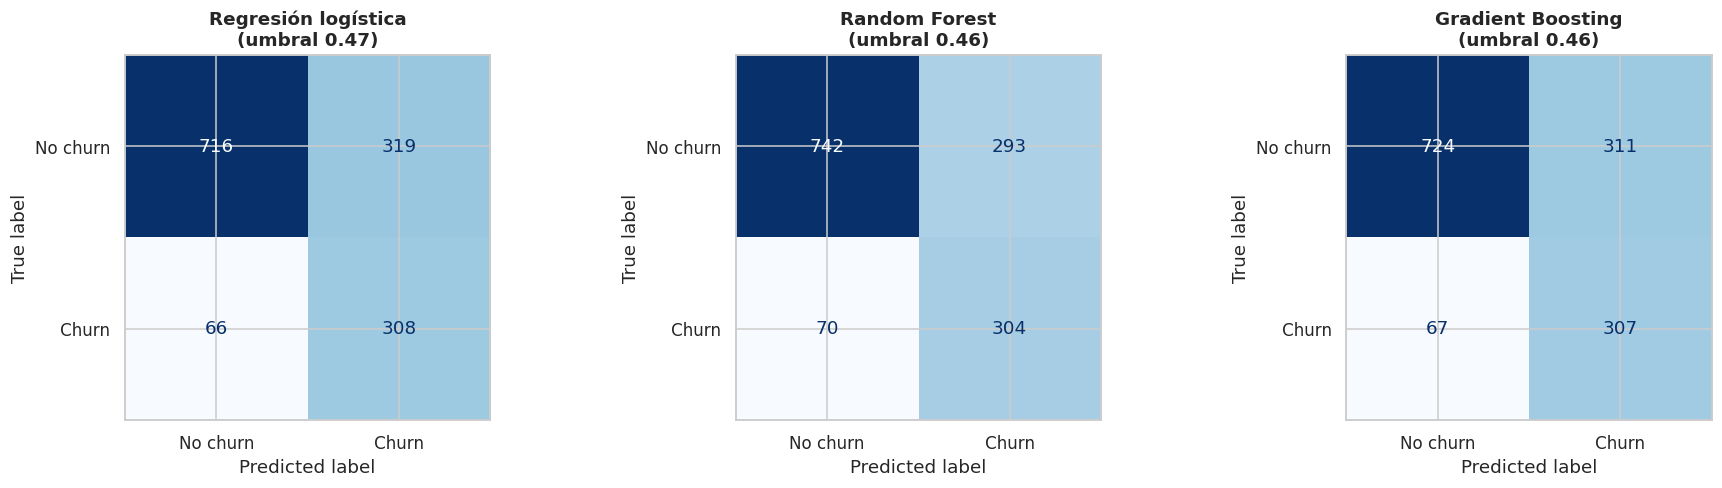

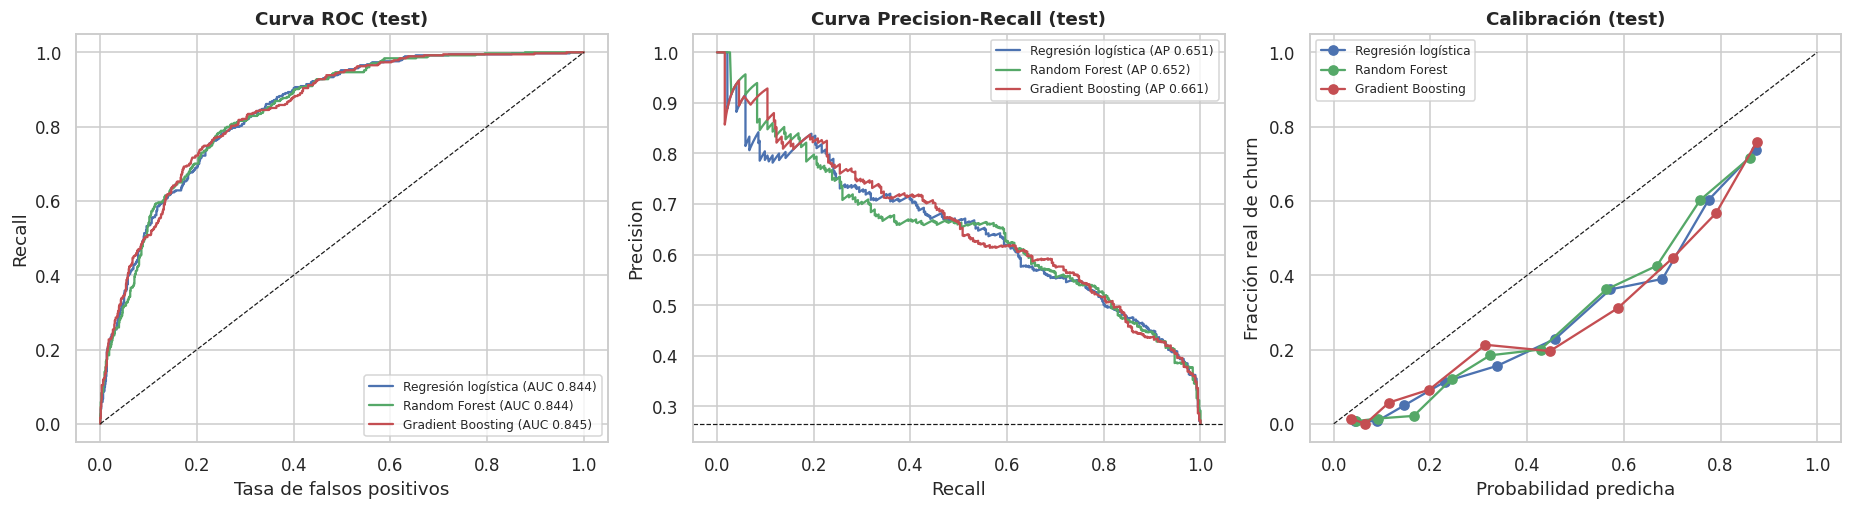

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for n, m in final_models.items():
    p = proba_test[n]; t = thr_kpi[n]
    ConfusionMatrixDisplay.from_predictions(yt, p >= t, display_labels=["No churn", "Churn"], cmap="Blues",
                                            colorbar=False, ax=axes[list(final_models).index(n)])
    axes[list(final_models).index(n)].set_title(f"{MODEL_LABEL[n]}\n(umbral {t:.2f})")
plt.tight_layout(); savefig("21_matrices_confusion_test.png"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for n, p in proba_test.items():
    fpr, tpr, _ = roc_curve(yt, p); axes[0].plot(fpr, tpr, color=MODEL_COLORS[n], label=f"{MODEL_LABEL[n]} (AUC {roc_auc_score(yt, p):.3f})")
    pr, rc, _ = precision_recall_curve(yt, p); axes[1].plot(rc, pr, color=MODEL_COLORS[n], label=f"{MODEL_LABEL[n]} (AP {average_precision_score(yt, p):.3f})")
    fo, mp = calibration_curve(yt, p, n_bins=10, strategy="quantile"); axes[2].plot(mp, fo, marker="o", color=MODEL_COLORS[n], label=MODEL_LABEL[n])
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8); axes[0].set_title("Curva ROC (test)"); axes[0].set_xlabel("Tasa de falsos positivos"); axes[0].set_ylabel("Recall")
axes[1].axhline(yt.mean(), color="k", ls="--", lw=0.8); axes[1].set_title("Curva Precision-Recall (test)"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[2].plot([0, 1], [0, 1], "k--", lw=0.8); axes[2].set_title("Calibración (test)"); axes[2].set_xlabel("Probabilidad predicha"); axes[2].set_ylabel("Fracción real de churn")
for a in axes: a.legend(fontsize=8)
plt.tight_layout(); savefig("22_roc_pr_calibracion_test.png"); plt.show()

**Interpretación de la evaluación en test (punto de operación con KPI)**

| Modelo | ROC-AUC | PR-AUC | Recall | Precision | F1 |
|---|---|---|---|---|---|
| Regresión logística (umbral 0,47) | 0,844 | 0,651 | 0,824 | 0,491 | 0,615 |
| Random Forest (umbral 0,46) | 0,844 | 0,652 | 0,813 | 0,509 | 0,626 |
| Gradient Boosting (umbral 0,46) | 0,845 | 0,661 | 0,821 | 0,497 | 0,619 |

- **El desempeño de validación se confirma en datos nuevos:** PR-AUC en test 0,651–0,661 frente a 0,658–0,667 en validación cruzada (caída de 0,007 a 0,016, dentro del intervalo de confianza 95 % ≈ [0,60 ; 0,71]); ROC-AUC 0,844–0,845 frente a 0,846–0,848.
- **Sin ganador estadístico:** las diferencias pareadas frente a la regresión logística tienen intervalos que incluyen el 0 (PR-AUC: Random Forest [−0,015 ; +0,018], Gradient Boosting [−0,007 ; +0,027]; ROC-AUC: [−0,006 ; +0,004] y [−0,005 ; +0,006]). Se elige la **regresión logística** por parsimonia, interpretabilidad y menor brecha train–test.
- **Matriz de confusión (regresión logística, umbral 0,47):** 308 verdaderos positivos, 66 falsos negativos, 319 falsos positivos y 716 verdaderos negativos. Detecta 308 de los 374 churners (82,4 %) a costa de 319 ofertas a clientes que se quedaban.
- **Costo con R = 5** (en unidades de "oferta desperdiciada"): modelo = 5 × 66 + 319 = **649**; contactar a todos = 1.035; no hacer nada = 5 × 374 = 1.870. El modelo reduce el costo un 37 % frente a contactar a todos y un 65 % frente a no actuar.
- **Accuracy engañosa:** 72,7 % es menor que el 73,5 % de un modelo que nunca predice churn, pero ese modelo detectaría 0 % de los churners. Por eso no se usa como métrica principal.
- **Metas de KPI en test:** Recall 0,824 ≥ 0,75 ✓; F1 0,615 ≥ 0,60 ✓; ROC-AUC 0,844 ≥ 0,83 ✓; PR-AUC 0,651 frente a línea base 0,265 ✓. **La Precision (0,491) queda 0,009 bajo la meta de 0,50**: no se cumple estrictamente, aunque la diferencia es menor que el ruido muestral (con 627 alertas el error estándar es ≈ 0,02, intervalo ≈ ±0,04). Se reporta como cumplimiento marginal.

In [53]:
FINAL = "LogReg"        # decisión justificada en la interpretación de arriba
t_final = thr_kpi[FINAL]
p_final = proba_test[FINAL]
print(f"Modelo final: {MODEL_LABEL[FINAL]} | umbral = {t_final:.2f}\n")
print(classification_report(yt, p_final >= t_final, target_names=["No churn", "Churn"], digits=3))

Modelo final: Regresión logística | umbral = 0.47

              precision    recall  f1-score   support

    No churn      0.916     0.692     0.788      1035
       Churn      0.491     0.824     0.615       374

    accuracy                          0.727      1409
   macro avg      0.703     0.758     0.702      1409
weighted avg      0.803     0.727     0.742      1409



### 5.3 Control de overfitting y underfitting
**(a) Brecha train vs validación cruzada vs test** y **(b) curvas de aprendizaje** (qué pasa con el desempeño al aumentar los datos de entrenamiento).

In [54]:
rows = []
for n, m in final_models.items():
    ptr = m.predict_proba(X_train)[:, 1]
    rows.append({"modelo": n,
                 "PR-AUC train": average_precision_score(y_train, ptr), "PR-AUC CV": sel_cv.loc[n, "cv_pr_auc"],
                 "PR-AUC test": average_precision_score(yt, proba_test[n]),
                 "ROC-AUC train": roc_auc_score(y_train, ptr), "ROC-AUC CV": sel_cv.loc[n, "cv_roc_auc"],
                 "ROC-AUC test": roc_auc_score(yt, proba_test[n])})
gap = pd.DataFrame(rows).set_index("modelo")
gap["brecha PR-AUC train-test"] = gap["PR-AUC train"] - gap["PR-AUC test"]
gap.round(3)

,PR-AUC train,PR-AUC CV,PR-AUC test,ROC-AUC train,ROC-AUC CV,ROC-AUC test,brecha PR-AUC train-test
modelo,,,,,,,
LogReg,0.670,0.667,0.651,0.851,0.848,0.844,0.019
RandomForest,0.688,0.659,0.652,0.862,0.846,0.844,0.036
HistGB,0.685,0.658,0.661,0.859,0.847,0.845,0.025


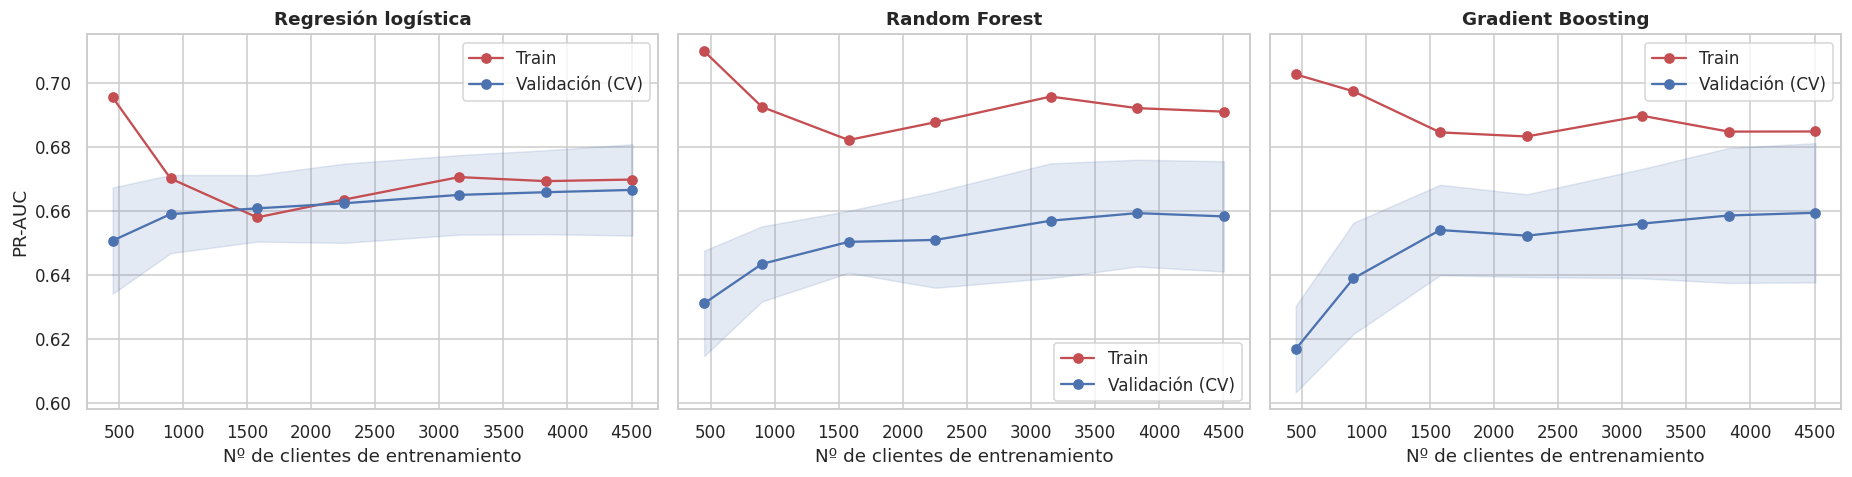

,brecha con 10% de datos,brecha con 100% de datos,PR-AUC val. con 50% de datos,PR-AUC val. con 100%
LogReg,0.045,0.003,0.662,0.667
RandomForest,0.079,0.033,0.651,0.658
HistGB,0.086,0.025,0.652,0.659


In [55]:
sizes = [0.1, 0.2, 0.35, 0.5, 0.7, 0.85, 1.0]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
lc_res = {}
for ax, (n, m) in zip(axes, final_models.items()):
    ts, tr_sc, va_sc = learning_curve(clone(m), X_train, y_train, train_sizes=sizes, cv=cv,
                                      scoring="average_precision", n_jobs=1, random_state=RANDOM_STATE, shuffle=True)
    lc_res[n] = (ts, tr_sc.mean(1), va_sc.mean(1))
    ax.plot(ts, tr_sc.mean(1), marker="o", color="#C44E52", label="Train")
    ax.plot(ts, va_sc.mean(1), marker="o", color="#4C72B0", label="Validación (CV)")
    ax.fill_between(ts, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), color="#4C72B0", alpha=0.15)
    ax.set_title(MODEL_LABEL[n]); ax.set_xlabel("Nº de clientes de entrenamiento"); ax.legend()
axes[0].set_ylabel("PR-AUC")
plt.tight_layout(); savefig("23_curvas_aprendizaje.png"); plt.show()
pd.DataFrame({n: {"brecha con 10% de datos": v[1][0] - v[2][0], "brecha con 100% de datos": v[1][-1] - v[2][-1],
                  "PR-AUC val. con 50% de datos": v[2][3], "PR-AUC val. con 100%": v[2][-1]} for n, v in lc_res.items()}).T.round(3)

**Interpretación del control de overfitting y underfitting**

- **Brecha train–test (PR-AUC):** regresión logística 0,019, Random Forest 0,036 y Gradient Boosting 0,025: las tres bajo la meta de 0,05. Los modelos finales están regularizados y no memorizan el entrenamiento.
- **Curvas de aprendizaje:** en la regresión logística la brecha baja de 0,045 (con 10 % de los datos) a 0,003 (con 100 %), y el PR-AUC de validación apenas sube de 0,662 (50 % de los datos) a 0,667 (100 %): **la curva ya se aplanó**, por lo que más datos del mismo tipo aportarían muy poco. En Random Forest (brecha 0,079 → 0,033) y Gradient Boosting (0,086 → 0,025) la validación sube modestamente (0,651 → 0,658 y 0,652 → 0,659).
- **Diagnóstico:** no hay overfitting relevante ni underfitting severo. Los modelos más flexibles no superan a la regresión logística (y sin regularización llegaban a PR-AUC 0,86 en train frente a 0,66 en validación), lo que indica que **el techo lo pone la información disponible en las variables, no la capacidad del modelo**. Mejorar el desempeño requiere **datos nuevos** (uso y consumo, llamadas a soporte, reclamos, historial de alzas de precio) más que modelos más complejos.

### 5.4 Interpretabilidad: ¿qué impulsa el riesgo de churn?
Se contrastan tres miradas: **coeficientes** de la regresión logística (odds ratios), **importancia por permutación** sobre test para los tres modelos (a nivel de variable original) y **valores SHAP**.

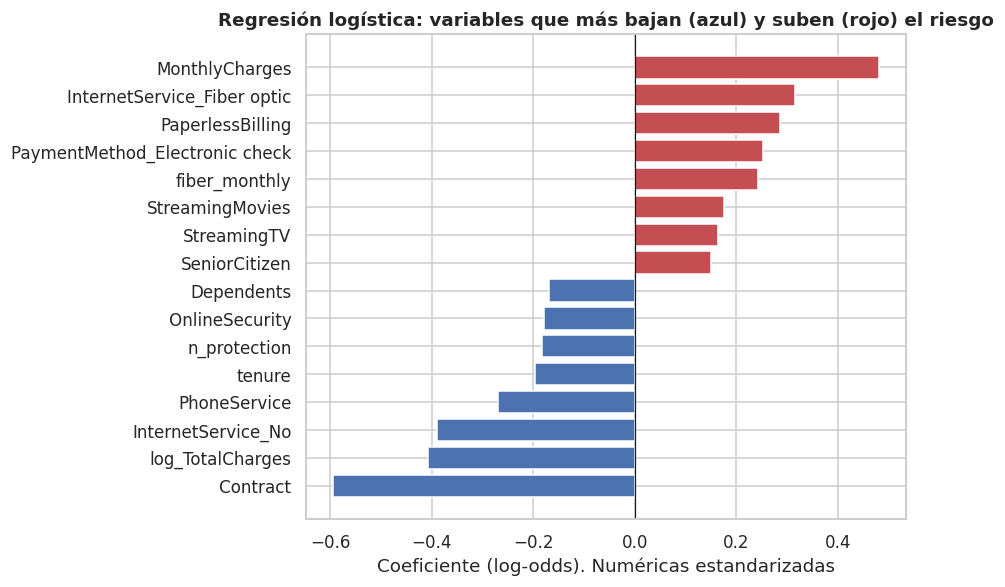

,coeficiente,odds ratio
Contract,-0.594,0.552
log_TotalCharges,-0.407,0.666
InternetService_No,-0.390,0.677
PhoneService,-0.270,0.763
tenure,-0.197,0.821
n_protection,-0.182,0.834
OnlineSecurity,-0.179,0.836
Dependents,-0.169,0.844
SeniorCitizen,0.150,1.162
StreamingTV,0.163,1.177


In [56]:
lr_pipe = final_models["LogReg"]
fn_names = lr_pipe.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=fn_names)
odds = pd.DataFrame({"coeficiente": coef, "odds ratio": np.exp(coef)}).sort_values("coeficiente")
top = pd.concat([odds.head(8), odds.tail(8)])

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.barh(top.index, top["coeficiente"], color=["#4C72B0" if v < 0 else "#C44E52" for v in top["coeficiente"]])
ax.axvline(0, color="k", lw=0.8); ax.set_title("Regresión logística: variables que más bajan (azul) y suben (rojo) el riesgo")
ax.set_xlabel("Coeficiente (log-odds). Numéricas estandarizadas")
plt.tight_layout(); savefig("24_coeficientes_logreg.png"); plt.show()
top.round(3)

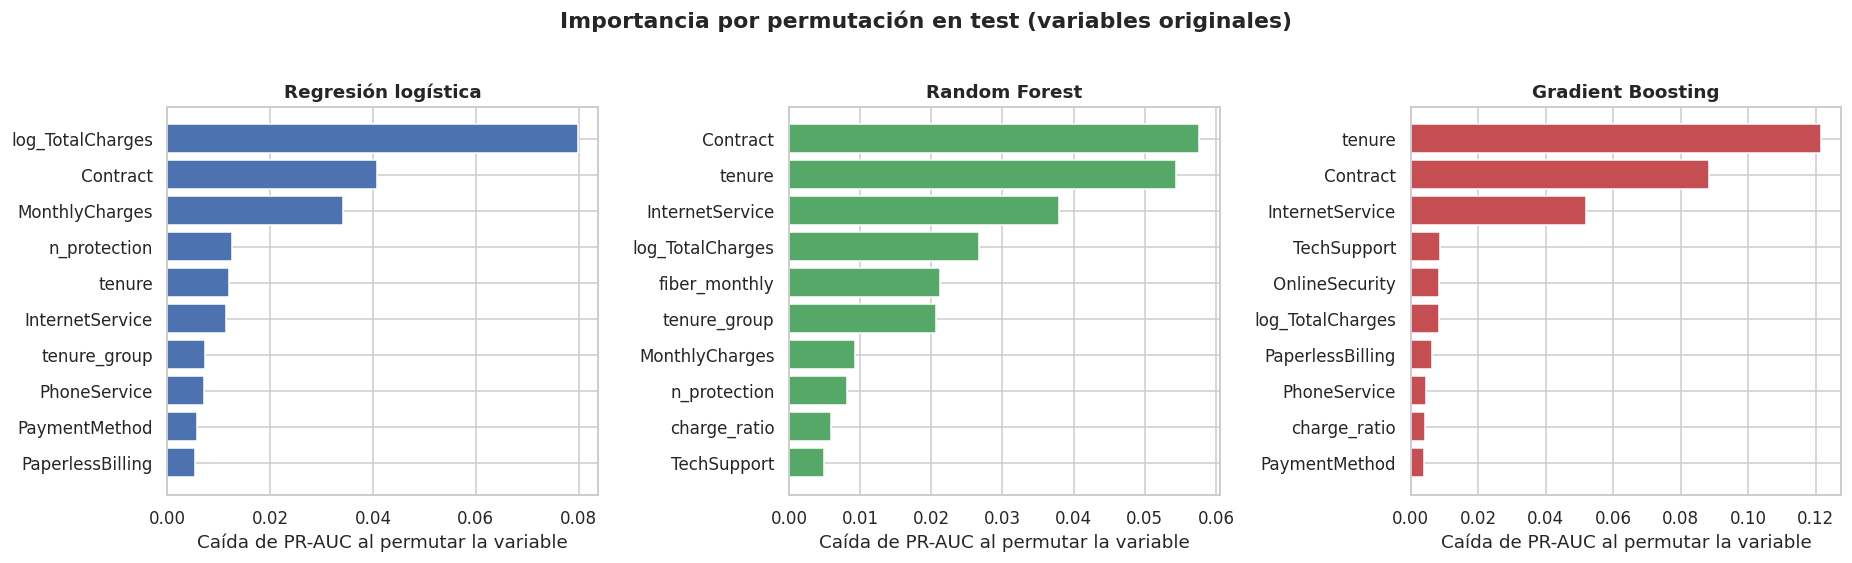

,Regresión logística,Random Forest,Gradient Boosting
0,log_TotalCharges,Contract,tenure
1,Contract,tenure,Contract
2,MonthlyCharges,InternetService,InternetService
3,n_protection,log_TotalCharges,TechSupport
4,tenure,fiber_monthly,OnlineSecurity
5,InternetService,tenure_group,log_TotalCharges
6,tenure_group,MonthlyCharges,PaperlessBilling
7,PhoneService,n_protection,PhoneService


In [57]:
perm = {}
for n, m in final_models.items():
    r = permutation_importance(m, X_test, y_test, scoring="average_precision", n_repeats=10,
                               random_state=RANDOM_STATE, n_jobs=1)
    perm[n] = pd.Series(r.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (n, s) in zip(axes, perm.items()):
    s10 = s.head(10)[::-1]
    ax.barh(s10.index, s10.values, color=MODEL_COLORS[n]); ax.set_title(MODEL_LABEL[n]); ax.set_xlabel("Caída de PR-AUC al permutar la variable")
plt.suptitle("Importancia por permutación en test (variables originales)", y=1.02, fontweight="bold")
plt.tight_layout(); savefig("25_importancia_permutacion.png"); plt.show()
pd.DataFrame({MODEL_LABEL[n]: s.head(8).index for n, s in perm.items()})

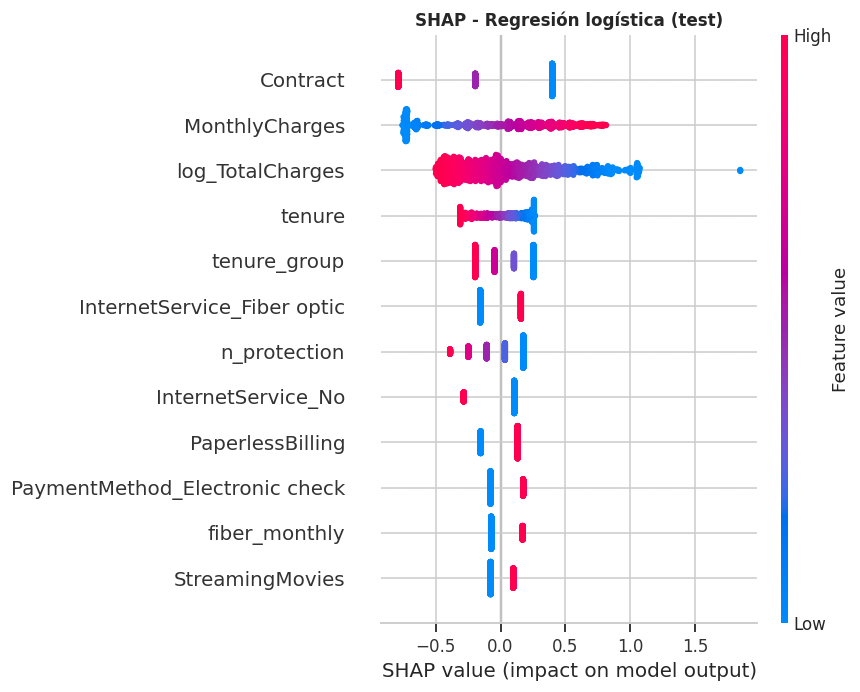

Top-8 |SHAP| medio (LogReg):
Contract                       0.448
MonthlyCharges                 0.412
log_TotalCharges               0.326
tenure                         0.176
tenure_group                   0.169
InternetService_Fiber optic    0.157
n_protection                   0.156
InternetService_No             0.145
dtype: float64


In [58]:
Xtr_p_lr = lr_pipe.named_steps["pre"].transform(X_train)
Xte_p_lr = lr_pipe.named_steps["pre"].transform(X_test)
expl = shap.LinearExplainer(lr_pipe.named_steps["model"], Xtr_p_lr)
sv_lr = expl.shap_values(Xte_p_lr)
plt.figure()
shap.summary_plot(sv_lr, Xte_p_lr, show=False, max_display=12)
plt.title("SHAP - Regresión logística (test)", fontsize=11, fontweight="bold")
savefig("26_shap_logreg.png"); plt.show()
shap_lr = pd.Series(np.abs(sv_lr).mean(0), index=Xte_p_lr.columns).sort_values(ascending=False)
print("Top-8 |SHAP| medio (LogReg):"); print(shap_lr.head(8).round(3))

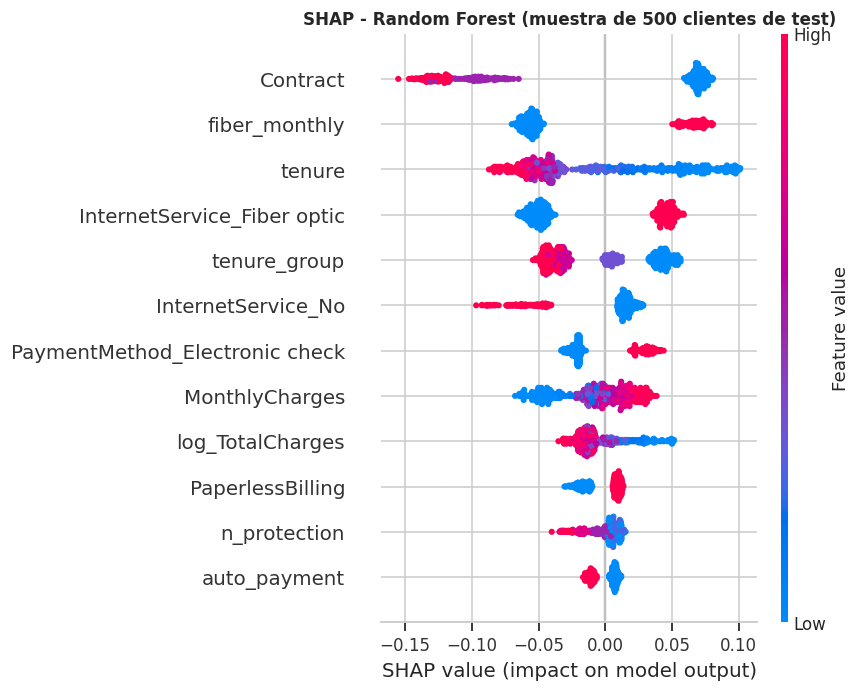

Top-8 |SHAP| medio (Random Forest):
Contract                          0.089
fiber_monthly                     0.059
tenure                            0.050
InternetService_Fiber optic       0.049
tenure_group                      0.036
InternetService_No                0.026
PaymentMethod_Electronic check    0.025
MonthlyCharges                    0.022
dtype: float64


In [59]:
try:
    rf_pipe = final_models["RandomForest"]
    Xte_p_rf = rf_pipe.named_steps["pre"].transform(X_test)
    Xs = Xte_p_rf.sample(500, random_state=RANDOM_STATE)
    sv = shap.TreeExplainer(rf_pipe.named_steps["model"]).shap_values(Xs)
    sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if np.ndim(sv) == 3 else sv)
    plt.figure()
    shap.summary_plot(sv, Xs, show=False, max_display=12)
    plt.title("SHAP - Random Forest (muestra de 500 clientes de test)", fontsize=11, fontweight="bold")
    savefig("27_shap_random_forest.png"); plt.show()
    shap_rf = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values(ascending=False)
    print("Top-8 |SHAP| medio (Random Forest):"); print(shap_rf.head(8).round(3))
except Exception as e:
    print("SHAP del Random Forest no disponible en este entorno:", repr(e))

**Interpretación: ¿qué impulsa el churn?**

- **Hay consistencia entre los tres métodos** (coeficientes, permutación y SHAP) y entre modelos. Las variables más importantes son el **tipo de contrato** y la **antigüedad** (y sus derivadas `log_TotalCharges` y `tenure_group`), seguidas por el **tipo de internet** (fibra), los **servicios de protección y soporte** y el **cargo mensual**. Por permutación: regresión logística (`log_TotalCharges`, `Contract`, `MonthlyCharges`, `n_protection`, `tenure`), Random Forest (`Contract`, `tenure`, `InternetService`, `log_TotalCharges`, `fiber_monthly`) y Gradient Boosting (`tenure`, `Contract`, `InternetService`, `TechSupport`, `OnlineSecurity`).
- **Odds ratios de la regresión logística** (manteniendo lo demás constante): cada nivel más largo de contrato (mensual → 1 año → 2 años) multiplica la odds de churn por **0,55**; fibra óptica 1,37; pago con *electronic check* 1,29; facturación electrónica 1,33; la interacción `fiber_monthly` 1,27; cada servicio de protección adicional 0,83; no tener internet 0,68; +1 desviación estándar de cargo mensual 1,62.
- **Precauciones de lectura:** (1) `tenure`, `log_TotalCharges` y `MonthlyCharges` están fuertemente relacionadas (`TotalCharges` ≈ `tenure` × cargo mensual), por lo que sus coeficientes se leen **en conjunto**, no por separado; (2) los coeficientes son condicionales: `PhoneService` aparece con signo negativo aunque su asociación individual con el churn era casi nula; (3) son **asociaciones, no causas**: el contrato largo es en parte un compromiso del cliente, no una palanca que por sí sola evite la baja.
- **`charge_ratio` no aparece entre las variables más importantes en ningún método**, lo que confirma que es débil; es candidata a eliminarse en una versión futura.
- **Traducción a acciones:** los factores más fuertes son accionables: migración a contratos largos, paquetes de protección y soporte, pago automático y revisión de precio y calidad de la fibra.

### 5.5 Auditoría de equidad (ética)
Se evalúa el modelo final **sobre test** en subgrupos. `gender` **no** es una variable del modelo, pero se audita igual para verificar que no hay sesgo indirecto (variables proxy). `SeniorCitizen` **sí** es una variable del modelo, por lo que se audita y además se mide el costo de excluirla.

Métricas por grupo: **tasa de alerta** (% de clientes marcados como riesgo), **Recall** (igualdad de oportunidad: ¿se detecta igual de bien a los que se van?), **Precision** y **tasa de falsos positivos** (¿se molesta más a un grupo con ofertas innecesarias?).

In [60]:
aud = clean.loc[X_test.index, ["gender", "SeniorCitizen"]].copy()
aud["senior"] = aud["SeniorCitizen"].map({0: "No senior", 1: "Senior"})
aud["y"] = yt; aud["pred"] = (p_final >= t_final).astype(int)

def group_metrics(df, col):
    rows = []
    for g, d in df.groupby(col):
        tn, fp, fn, tp = confusion_matrix(d["y"], d["pred"], labels=[0, 1]).ravel()
        rows.append({"grupo": g, "clientes": len(d), "% churn real": d["y"].mean() * 100,
                     "% alertados": d["pred"].mean() * 100, "recall": tp / (tp + fn), "precision": tp / (tp + fp),
                     "tasa falsos positivos": fp / (fp + tn)})
    return pd.DataFrame(rows).set_index("grupo")

eq_gender = group_metrics(aud, "gender"); eq_senior = group_metrics(aud, "senior")
print("Por género (variable NO usada por el modelo):"); display(eq_gender.round(3))
print("Por SeniorCitizen (variable usada por el modelo):"); display(eq_senior.round(3))
print("Razón de tasas de alerta (mín/máx): género =", round(eq_gender['% alertados'].min() / eq_gender['% alertados'].max(), 3),
      "| senior =", round(eq_senior['% alertados'].min() / eq_senior['% alertados'].max(), 3))
print("Brecha de recall (máx-mín): género =", round(eq_gender['recall'].max() - eq_gender['recall'].min(), 3),
      "| senior =", round(eq_senior['recall'].max() - eq_senior['recall'].min(), 3))

Por género (variable NO usada por el modelo):


,clientes,% churn real,% alertados,recall,precision,tasa falsos positivos
grupo,,,,,,
Female,687,28.093,44.250,0.798,0.507,0.304
Male,722,25.069,44.737,0.851,0.477,0.312


Por SeniorCitizen (variable usada por el modelo):


,clientes,% churn real,% alertados,recall,precision,tasa falsos positivos
grupo,,,,,,
No senior,1187,23.252,39.848,0.786,0.459,0.281
Senior,222,44.144,69.369,0.929,0.591,0.508


Razón de tasas de alerta (mín/máx): género = 0.989 | senior = 0.574
Brecha de recall (máx-mín): género = 0.053 | senior = 0.142


In [61]:
# ¿Las diferencias de Recall entre grupos son estadísticamente significativas? (prueba z de dos proporciones)
from scipy.stats import norm

def ztest_recall(d, col, g1, g2):
    c1 = d[(d[col] == g1) & (d["y"] == 1)]; c2 = d[(d[col] == g2) & (d["y"] == 1)]
    n1, n2 = len(c1), len(c2)
    r1, r2 = c1["pred"].mean(), c2["pred"].mean()
    p_comb = (r1 * n1 + r2 * n2) / (n1 + n2)
    z = (r1 - r2) / np.sqrt(p_comb * (1 - p_comb) * (1 / n1 + 1 / n2))
    return {"comparación": f"{g1} vs {g2}", "churners": f"{n1} / {n2}", "recall": f"{r1:.3f} / {r2:.3f}",
            "diferencia (puntos)": abs(r1 - r2) * 100, "p-valor": 2 * (1 - norm.cdf(abs(z)))}

pd.DataFrame([ztest_recall(aud, "gender", "Female", "Male"),
              ztest_recall(aud, "senior", "Senior", "No senior")]).round(3)

,comparación,churners,recall,diferencia (puntos),p-valor
0,Female vs Male,193 / 181,0.798 / 0.851,5.290,0.180
1,Senior vs No senior,98 / 276,0.929 / 0.786,14.234,0.001


In [66]:
# ¿Cuánto cuesta en desempeño excluir SeniorCitizen? (mismo modelo, mismos hiperparámetros)
# Para evitar romper el pipeline que busca 'SeniorCitizen', creamos versiones donde forzamos la columna a 0 (anulando su efecto en el modelo)
X_train_no_sen = X_train.copy()
X_train_no_sen["SeniorCitizen"] = 0

X_test_no_sen = X_test.copy()
X_test_no_sen["SeniorCitizen"] = 0

# Re-instanciamos el preprocesador y modelo original de LogReg
no_sen_pipe = Pipeline([("pre", build_preprocessor()),
                        ("model", clone(final_models["LogReg"].named_steps["model"]))])

cv_ns = cross_validate(no_sen_pipe, X_train_no_sen, y_train, cv=cv, scoring=SCORING)
no_sen_pipe.fit(X_train_no_sen, y_train)
p_ns = no_sen_pipe.predict_proba(X_test_no_sen)[:, 1]

cmp_ns = pd.DataFrame({
    "con SeniorCitizen": {"PR-AUC CV": sel_cv.loc["LogReg", "cv_pr_auc"], "PR-AUC test": average_precision_score(yt, p_final),
                          "ROC-AUC test": roc_auc_score(yt, p_final), "Recall test (umbral 0,5)": recall_score(yt, p_final >= 0.5)},
    "sin SeniorCitizen": {"PR-AUC CV": cv_ns["test_pr_auc"].mean(), "PR-AUC test": average_precision_score(yt, p_ns),
                          "ROC-AUC test": roc_auc_score(yt, p_ns), "Recall test (umbral 0,5)": recall_score(yt, p_ns >= 0.5)}})
cmp_ns.round(4)

,con SeniorCitizen,sin SeniorCitizen
PR-AUC CV,0.6666,0.6663
PR-AUC test,0.6507,0.6493
ROC-AUC test,0.8443,0.8429
"Recall test (umbral 0,5)",0.7941,0.7861


**Interpretación de la auditoría de equidad (modelo final, test)**

| Grupo | Clientes | % churn real | % alertados | Recall | Precision | Tasa de falsos positivos |
|---|---|---|---|---|---|---|
| Mujeres | 687 | 28,1 % | 44,3 % | 0,798 | 0,507 | 0,304 |
| Hombres | 722 | 25,1 % | 44,7 % | 0,851 | 0,477 | 0,312 |
| No senior | 1.187 | 23,3 % | 39,8 % | 0,786 | 0,459 | 0,281 |
| Senior | 222 | 44,1 % | 69,4 % | 0,929 | 0,591 | 0,508 |

- **Género (variable no usada por el modelo):** la tasa de alerta es prácticamente igual (razón 0,99) y también la de falsos positivos (0,304 frente a 0,312). La brecha de Recall (0,053) es compatible con el ruido muestral (≈ 190 churners por grupo, error estándar ≈ 0,03 por grupo). La prueba z de dos proporciones de esta sección da p ≈ 0,18: la diferencia **no es estadísticamente significativa**. Aun así, supera por poco la meta de 5 puntos fijada en la sección 1, por lo que se mantiene en monitoreo. **No hay evidencia de sesgo por género**, ni siquiera indirecto.
- **SeniorCitizen (variable sí usada):** se alerta al 69 % de los adultos mayores frente al 40 % del resto (razón 0,57), lo que refleja su mayor churn real (44 % frente a 23 %). Sus churners se detectan **mejor** (Recall 0,93 frente a 0,79; la diferencia de 14 puntos sí es estadísticamente significativa, p ≈ 0,001), pero la **tasa de falsos positivos casi se duplica** (0,51 frente a 0,28): los adultos mayores que se quedarían reciben ofertas innecesarias con mucha más frecuencia. No se cumple la igualdad de falsos positivos entre grupos.
- **Excluir `SeniorCitizen` casi no cuesta desempeño:** PR-AUC en test 0,651 → 0,649, ROC-AUC 0,844 → 0,843, Recall a umbral 0,5 de 0,794 → 0,786 (PR-AUC en validación cruzada 0,667 → 0,666).
- **Recomendaciones:** (1) excluir `SeniorCitizen` del modelo, por ser un atributo relacionado con la edad y potencialmente sensible, ya que no aporta de forma material; (2) **monitorear resultados por grupo igualmente**, porque variables como el contrato, la fibra o el método de pago pueden actuar como proxy; (3) que las ofertas sean beneficiosas y no coercitivas, con revisión humana antes de contactar. **Limitación:** el subgrupo de adultos mayores en test es pequeño (222 clientes).

### 5.6 Traducción a negocio: priorización, segmentos y valor esperado

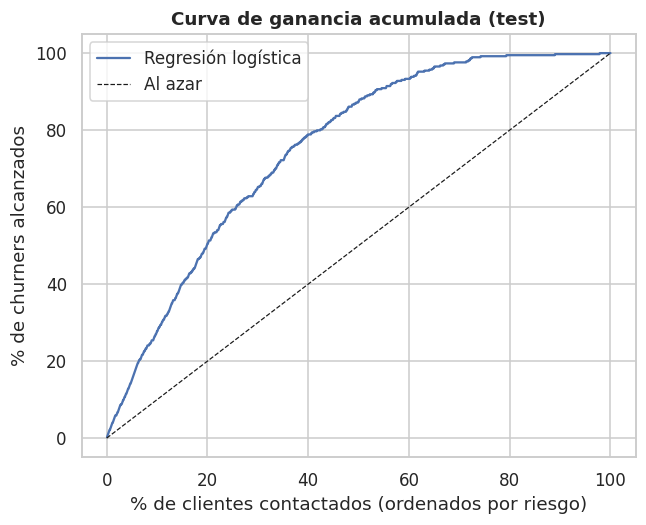

,clientes,% de churners alcanzados,tasa de churn en el grupo,lift vs azar
% de clientes contactados,,,,
10,141,27.81,73.76,2.78
20,282,50.53,67.02,2.52
30,423,65.24,57.68,2.17
40,564,78.88,52.30,1.97
50,704,87.43,46.45,1.75


In [67]:
# Curva de ganancia acumulada (cumulative gains) y lift del modelo final sobre test
order_ix = np.argsort(-p_final)
y_sorted = yt[order_ix]
cum_capt = np.cumsum(y_sorted) / yt.sum()
pct = np.arange(1, len(yt) + 1) / len(yt)

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(pct * 100, cum_capt * 100, color="#4C72B0", label=MODEL_LABEL[FINAL])
ax.plot([0, 100], [0, 100], "k--", lw=0.8, label="Al azar")
ax.set_xlabel("% de clientes contactados (ordenados por riesgo)"); ax.set_ylabel("% de churners alcanzados")
ax.set_title("Curva de ganancia acumulada (test)"); ax.legend()
savefig("28_curva_ganancia.png"); plt.show()

gain_rows = []
for q in [0.10, 0.20, 0.30, 0.40, 0.50]:
    k = int(round(q * len(yt)))
    gain_rows.append({"% de clientes contactados": int(q * 100), "clientes": k,
                      "% de churners alcanzados": y_sorted[:k].sum() / yt.sum() * 100,
                      "tasa de churn en el grupo": y_sorted[:k].mean() * 100,
                      "lift vs azar": (y_sorted[:k].mean() / yt.mean())})
gains = pd.DataFrame(gain_rows).set_index("% de clientes contactados")
gains.round(2)

In [68]:
# Segmentos K-Means x predicciones del modelo final (test)
seg_lab = np.array([names[int(i)] for i in seg_test])
sg = pd.DataFrame({"segmento": seg_lab, "y": yt, "pred": (p_final >= t_final).astype(int)})
rows = []
for s_, d in sg.groupby("segmento"):
    tn, fp, fn, tp = confusion_matrix(d["y"], d["pred"], labels=[0, 1]).ravel()
    rows.append({"segmento": s_, "clientes": len(d), "% churn real": d["y"].mean() * 100,
                 "% alertados": d["pred"].mean() * 100, "recall": tp / (tp + fn) if (tp + fn) else np.nan,
                 "precision": tp / (tp + fp) if (tp + fp) else np.nan})
seg_pred = pd.DataFrame(rows).set_index("segmento").sort_values("% churn real", ascending=False)
seg_pred.round(2)

,clientes,% churn real,% alertados,recall,precision
segmento,,,,,
Fibra + contrato mensual · alto riesgo,406,54.19,97.54,0.98,0.55
Mensuales DSL · valor medio,296,29.39,53.04,0.79,0.44
Leales de alto valor,392,10.71,8.42,0.24,0.30
Sin internet · bajo costo,315,7.94,13.02,0.52,0.32


In [69]:
# Valor esperado bajo SUPUESTOS ILUSTRATIVOS (a reemplazar por datos reales de la empresa)
churn_monthly = clean.loc[X_train.index][y_train.values == 1]["MonthlyCharges"].mean()
VALOR_CHURNER = 12 * churn_monthly     # supuesto: ingresos de 12 meses de un cliente que se va
COSTO_OFERTA = 50.0                    # supuesto: costo de una oferta de retención por cliente contactado
print(f"Valor de un churner (12 meses): ${VALOR_CHURNER:,.0f} | costo oferta: ${COSTO_OFERTA:,.0f}")

def net_benefit(flagged_mask, success):
    tp = (flagged_mask & (yt == 1)).sum(); n_flag = flagged_mask.sum()
    return tp * success * VALOR_CHURNER - n_flag * COSTO_OFERTA

k20 = int(round(0.20 * len(yt))); top20 = np.zeros(len(yt), bool); top20[order_ix[:k20]] = True
strategies = {
    "No hacer nada": np.zeros(len(yt), bool),
    "Contactar a todos": np.ones(len(yt), bool),
    f"Modelo, umbral {t_final:.2f} (con KPI)": p_final >= t_final,
    f"Modelo, umbral {chosen_thr[FINAL]:.2f} (costo mín. R=5)": p_final >= chosen_thr[FINAL],
    "Modelo, umbral 0,5": p_final >= 0.5,
    "Top 20% de mayor riesgo": top20,
}
nb_rows = {}
for nm, mask in strategies.items():
    nb_rows[nm] = {"clientes contactados": int(mask.sum()), **{f"beneficio neto (éxito {int(s*100)}%)": net_benefit(mask, s) for s in [0.2, 0.3, 0.5]}}
nb_df = pd.DataFrame(nb_rows).T
nb_df.round(0)

Valor de un churner (12 meses): $898 | costo oferta: $50


,clientes contactados,beneficio neto (éxito 20%),beneficio neto (éxito 30%),beneficio neto (éxito 50%)
No hacer nada,0.0,0.0,0.0,0.0
Contactar a todos,1409.0,-3256.0,30342.0,97536.0
"Modelo, umbral 0.47 (con KPI)",627.0,23987.0,51655.0,106992.0
"Modelo, umbral 0.34 (costo mín. R=5)",771.0,22536.0,53079.0,114165.0
"Modelo, umbral 0,5",574.0,24660.0,51340.0,104701.0
Top 20% de mayor riesgo,282.0,19857.0,36835.0,70791.0


#### Impacto en ingreso con el cargo real de cada cliente
La celda anterior valoriza cada churner detectado con el promedio de los que se van. Aquí se usa el **cargo mensual real** de cada cliente detectado, lo que permite medir directamente el KPI de **ingreso mensual en riesgo capturado**. Se mantienen los mismos supuestos ilustrativos (oferta de \$50, 12 meses de valor) y se toma un éxito de retención del 30 %. Los beneficios resultan algo menores que en la celda anterior porque los churners de test pagan en promedio \$72,8 al mes, menos que los \$74,8 de train que allí se usaron como valor promedio.

In [70]:
cargo_test = X_test["MonthlyCharges"].values
ingreso_riesgo_test = cargo_test[yt == 1].sum()

def campana(contactar, exito=0.30, meses=12):
    mask = np.asarray(contactar, dtype=bool)
    detectados = mask & (yt == 1)
    retenido = cargo_test[detectados].sum() * meses * exito
    costo = mask.sum() * COSTO_OFERTA
    return {"contactados": int(mask.sum()), "churners detectados": int(detectados.sum()),
            "% ingreso en riesgo capturado": cargo_test[detectados].sum() / ingreso_riesgo_test * 100,
            "ingreso retenido ($)": retenido, "costo ($)": costo, "beneficio neto ($)": retenido - costo}

escenarios = {"No hacer nada": np.zeros(len(yt), bool),
              "Contactar a todos": np.ones(len(yt), bool),
              "Top 20 % de mayor riesgo": top20,
              f"Modelo, umbral {t_final:.2f}": p_final >= t_final}
impacto = pd.DataFrame({k: campana(v) for k, v in escenarios.items()}).T
print(f"Ingreso mensual en riesgo en test (churners reales): ${ingreso_riesgo_test:,.0f}")
impacto.round(1)

Ingreso mensual en riesgo en test (churners reales): $27,215


,contactados,churners detectados,% ingreso en riesgo capturado,ingreso retenido ($),costo ($),beneficio neto ($)
No hacer nada,0.0,0.0,0.0,0.0,0.0,0.0
Contactar a todos,1409.0,374.0,100.0,97973.6,70450.0,27523.6
Top 20 % de mayor riesgo,282.0,189.0,55.8,54687.1,14100.0,40587.1
"Modelo, umbral 0.47",627.0,308.0,83.6,81875.9,31350.0,50525.9


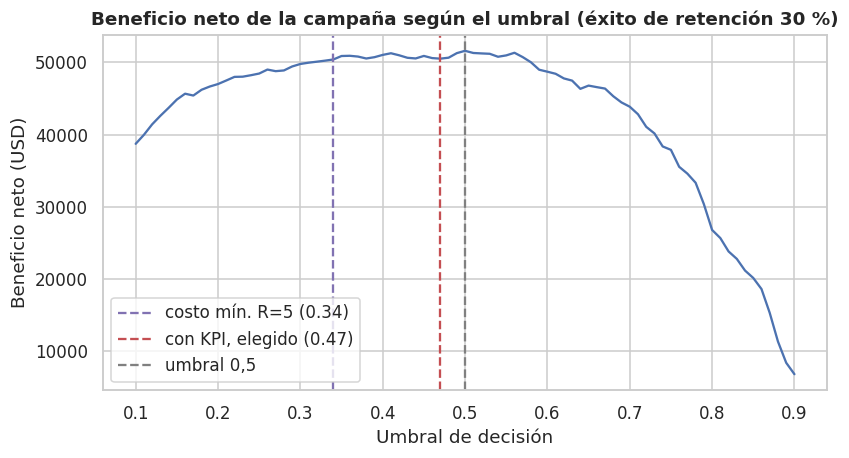

Umbral que maximiza el beneficio neto: 0.50 ($51,614) | con el umbral elegido (0.47): $50,526


In [71]:
# Beneficio neto según el umbral de decisión (modelo final)
umbrales_prueba = np.linspace(0.10, 0.90, 81)
beneficios = [campana(p_final >= u)["beneficio neto ($)"] for u in umbrales_prueba]
mejor_u = umbrales_prueba[int(np.argmax(beneficios))]

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(umbrales_prueba, beneficios, color="#4C72B0")
for u, lab, col in [(chosen_thr[FINAL], f"costo mín. R=5 ({chosen_thr[FINAL]:.2f})", "#8172B2"),
                    (t_final, f"con KPI, elegido ({t_final:.2f})", "#C44E52"), (0.5, "umbral 0,5", "gray")]:
    ax.axvline(u, ls="--", color=col, label=lab)
ax.set_xlabel("Umbral de decisión"); ax.set_ylabel("Beneficio neto (USD)")
ax.set_title("Beneficio neto de la campaña según el umbral (éxito de retención 30 %)"); ax.legend()
savefig("30_beneficio_vs_umbral.png"); plt.show()
print(f"Umbral que maximiza el beneficio neto: {mejor_u:.2f} (${max(beneficios):,.0f}) | con el umbral elegido ({t_final:.2f}): ${campana(p_final >= t_final)['beneficio neto ($)']:,.0f}")

**Interpretación de negocio**

- **Priorización:** contactar al 10 % de clientes de mayor riesgo alcanza al **27,8 % de los churners** (lift 2,8 respecto del azar); al 20 %, al **50,5 %** (lift 2,5); al 30 %, al 65,2 %. Con presupuesto limitado, el 20 % de mayor riesgo cubre la mitad de las bajas con 2,5 veces la eficiencia de una campaña al azar.
- **Segmentos y modelo se complementan:**
  - *Fibra + contrato mensual:* el modelo alerta al **97,5 %** del segmento (Recall 0,98, Precision 0,55): como el segmento entero es de riesgo alto (54 % de churn real), la puntuación individual discrimina poco dentro de él. Conviene una acción estructural a nivel de segmento (migración de contrato, paquete de soporte, revisión de precio/calidad) en vez de ofertas personalizadas.
  - *Mensuales DSL:* se alerta al 53 % (Recall 0,79, Precision 0,44): aquí la puntuación sí selecciona a quién contactar.
  - *Leales de alto valor:* se alerta solo al 8 % (Recall 0,24, Precision 0,30 frente a 10,7 % de base): el modelo **encuentra pocos de los pocos churners de este segmento**; probablemente se van por razones no capturadas en los datos.
  - *Sin internet:* se alerta al 13 % (Recall 0,52).
- **Valor esperado (supuestos ilustrativos):** valor de un churner = \$898 (12 meses del cargo promedio de quienes se van) y oferta de \$50 por cliente contactado. Con 30 % de éxito de la oferta, el beneficio neto sobre los 1.409 clientes de test es de **\$51,7 mil** con el modelo (627 contactos) frente a \$30,3 mil al contactar a todos (+\$21,3 mil, ≈ \$15 por cliente evaluado) y \$36,8 mil con el 20 % de mayor riesgo. Con 20 % de éxito, contactar a todos **pierde dinero** (−\$3,3 mil) mientras el modelo gana \$24,0 mil; con 50 %, el modelo gana \$107,0 mil frente a \$97,5 mil.
- **El umbral importa menos que el ranking:** los tres umbrales (0,34; 0,47; 0,50) dan beneficios netos similares (con 30 % de éxito, entre \$51,3 mil y \$53,1 mil).
- **Ingreso mensual en riesgo capturado:** valorizando cada cliente con su cargo real, el modelo con umbral 0,47 contacta al **44,5 % de los clientes y captura el 83,6 % del ingreso mensual en riesgo** (meta ≥ 70 %); contactar solo al 20 % de mayor riesgo captura el 55,8 %.
- **Sensibilidad al umbral:** la curva de beneficio neto es muy plana alrededor del umbral elegido (\$50,5 mil frente a \$51,6 mil en el óptimo, umbral 0,50), lo que confirma que importa más tener un buen ranking que afinar el umbral.
- **Salvedad importante:** los montos dependen de supuestos que deben reemplazarse por datos reales. Además, el modelo predice el **riesgo de irse, no la respuesta a la oferta**: hay clientes de alto riesgo a los que ninguna oferta retiene. Medir el éxito real con un experimento A/B (y, a futuro, un modelo de *uplift*) es el siguiente paso.

### 5.7 Resumen de la etapa de evaluación
**Artefactos:** `reports/resultados_test.csv` y los gráficos `20` a `28` y `30` en `images/`.

**Modelo final:** regresión logística regularizada (L2, `C = 0,01`, `class_weight="balanced"`) con umbral de decisión **0,47**.

| KPI | Meta | Resultado en test | Estado |
|---|---|---|---|
| Recall (churn) | ≥ 0,75 | 0,824 | ✓ |
| Precision (churn) | ≥ 0,50 | 0,491 | Marginal (−0,009, dentro del ruido muestral) |
| F1 (churn) | ≥ 0,60 | 0,615 | ✓ |
| ROC-AUC | ≥ 0,83 | 0,844 | ✓ |
| PR-AUC | muy sobre 0,265 | 0,651 | ✓ |
| Brecha train–test (PR-AUC) | ≤ 0,05 | 0,019 | ✓ |
| Lift del 20 % de mayor riesgo | ≥ 2 | 2,52 | ✓ |
| Ingreso mensual en riesgo capturado | ≥ 70 % | 83,6 % | ✓ |
| Brecha de Recall mujeres–hombres | < 5 puntos | 5,3 puntos | Marginal (p ≈ 0,18: no es estadísticamente significativa) |

La celda siguiente recalcula la tabla a partir de los resultados del notebook. Las recomendaciones y limitaciones están en la sección 7.

In [72]:
# Tablero de KPIs: verificación automática contra las metas de la sección 1
pred_final = (p_final >= t_final)
captura = cargo_test[pred_final & (yt == 1)].sum() / ingreso_riesgo_test * 100
brecha_genero = (eq_gender["recall"].max() - eq_gender["recall"].min()) * 100

tablero = pd.DataFrame([
    ["Recall (churn)",                       recall_score(yt, pred_final),                         "≥ 0,75",          recall_score(yt, pred_final) >= 0.75],
    ["Precision (churn)",                    precision_score(yt, pred_final),                      "≥ 0,50",          precision_score(yt, pred_final) >= 0.50],
    ["F1 (churn)",                           f1_score(yt, pred_final),                             "≥ 0,60",          f1_score(yt, pred_final) >= 0.60],
    ["ROC-AUC",                              roc_auc_score(yt, p_final),                           "≥ 0,83",          roc_auc_score(yt, p_final) >= 0.83],
    ["PR-AUC",                               average_precision_score(yt, p_final),                 "> 0,265",         average_precision_score(yt, p_final) > yt.mean()],
    ["Brecha train–test (PR-AUC)",           gap.loc[FINAL, "brecha PR-AUC train-test"],           "≤ 0,05",          gap.loc[FINAL, "brecha PR-AUC train-test"] <= 0.05],
    ["Lift del 20 % de mayor riesgo",        gains.loc[20, "lift vs azar"],                        "≥ 2",             gains.loc[20, "lift vs azar"] >= 2],
    ["% ingreso mensual en riesgo capturado", captura,                                             "≥ 70",            captura >= 70],
    ["Brecha de Recall mujeres–hombres (pts)", brecha_genero,                                      "< 5",             brecha_genero < 5],
], columns=["KPI", "Resultado", "Meta", "¿Cumple estrictamente?"]).set_index("KPI")
tablero["Resultado"] = tablero["Resultado"].astype(float).round(3)
tablero["¿Cumple estrictamente?"] = tablero["¿Cumple estrictamente?"].map({True: "✓", False: "✗ (ver 5.7)"})
tablero

,Resultado,Meta,¿Cumple estrictamente?
KPI,,,
Recall (churn),0.824,"≥ 0,75",✓
Precision (churn),0.491,"≥ 0,50",✗ (ver 5.7)
F1 (churn),0.615,"≥ 0,60",✓
ROC-AUC,0.844,"≥ 0,83",✓
PR-AUC,0.651,"> 0,265",✓
Brecha train–test (PR-AUC),0.019,"≤ 0,05",✓
Lift del 20 % de mayor riesgo,2.525,≥ 2,✓
% ingreso mensual en riesgo capturado,83.569,≥ 70,✓
Brecha de Recall mujeres–hombres (pts),5.290,< 5,✗ (ver 5.7)


## 6. Deployment y ética
Esta etapa deja el modelo listo para que lo use el área comercial y define los resguardos para usarlo de forma responsable. No es una puesta en producción real (no hay sistema de destino ni datos nuevos): se dejan los artefactos, la lista priorizada de clientes y las reglas de uso.

### 6.1 Artefactos y lista priorizada para el área comercial
El modelo final (`logreg_tuned.joblib`), el preprocesador y la segmentación ya se guardaron en las secciones 3 y 4. Aquí se agrega: (1) la **configuración** del modelo final (umbral, variables, métricas y supuestos), y (2) la **lista de clientes de test ordenada por riesgo**, con su segmento, que es el insumo que usaría el equipo de retención. En producción esta lista se generaría sobre la base de clientes activos.

In [73]:
import json

fila_final = test_res[(test_res["modelo"] == FINAL) & (test_res["punto de operación"] == "con restricción de KPI")].iloc[0]
config = {
    "modelo_final": MODEL_LABEL[FINAL],
    "archivo_modelo": "models/logreg_tuned.joblib",
    "umbral": round(float(t_final), 4),
    "variables": list(FEATURES),
    "variables_excluidas": ["customerID", "gender"],
    "metricas_test": {k: round(float(fila_final[k]), 4) for k in ["ROC-AUC", "PR-AUC", "precision", "recall", "f1"]},
    "supuestos_negocio": {"costo_oferta_usd": COSTO_OFERTA, "meses_de_valor": 12, "exito_retencion_base": 0.30},
}
(REPORTS / "config_modelo.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

# Lista de clientes de test ordenada por riesgo (insumo para el área comercial)
scoring = clean.loc[X_test.index, ["customerID", "Contract", "tenure", "MonthlyCharges"]].copy()
scoring["prob_churn"] = p_final.round(4)
scoring["alerta"] = (p_final >= t_final).astype(int)
scoring["segmento"] = seg_lab
scoring = scoring.sort_values("prob_churn", ascending=False)
scoring.to_csv(REPORTS / "scoring_clientes_test.csv", index=False)
print("Guardado: reports/config_modelo.json y reports/scoring_clientes_test.csv")
scoring.head(10)

Guardado: reports/config_modelo.json y reports/scoring_clientes_test.csv


,customerID,Contract,tenure,MonthlyCharges,prob_churn,alerta,segmento
3380,5178-LMXOP,Month-to-month,1,95.10,0.9514,1,Fibra + contrato mensual · alto riesgo
6866,0295-PPHDO,Month-to-month,1,95.45,0.9449,1,Fibra + contrato mensual · alto riesgo
4585,1069-XAIEM,Month-to-month,1,85.05,0.9366,1,Fibra + contrato mensual · alto riesgo
642,0970-ETWGE,Month-to-month,1,89.55,0.9320,1,Fibra + contrato mensual · alto riesgo
6894,1400-MMYXY,Month-to-month,3,105.90,0.9313,1,Fibra + contrato mensual · alto riesgo
2397,3722-WPXTK,Month-to-month,1,88.35,0.9310,1,Fibra + contrato mensual · alto riesgo
3727,9057-SIHCH,Month-to-month,3,96.60,0.9280,1,Fibra + contrato mensual · alto riesgo
2797,6023-YEBUP,Month-to-month,3,100.95,0.9269,1,Fibra + contrato mensual · alto riesgo
3346,2545-EBUPK,Month-to-month,2,84.05,0.9232,1,Fibra + contrato mensual · alto riesgo
6748,6230-BSUXY,Month-to-month,1,85.00,0.9226,1,Fibra + contrato mensual · alto riesgo


#### Verificación de los artefactos guardados
Se recarga el modelo desde disco y se comprueba que reproduce exactamente las predicciones del notebook. También se deja una función para puntuar clientes con el formato del CSV original.

In [74]:
modelo_prod = joblib.load(MODELS / "logreg_tuned.joblib")
umbral_prod = json.loads((REPORTS / "config_modelo.json").read_text(encoding="utf-8"))["umbral"]

assert np.allclose(modelo_prod.predict_proba(X_test)[:, 1], p_final), "El modelo recargado no coincide con el del notebook"

def puntuar_clientes(raw_df, modelo=modelo_prod, umbral=umbral_prod):
    """Recibe clientes con las columnas del CSV original y devuelve su probabilidad de churn y si se alerta."""
    d = clean_and_engineer(raw_df)
    prob = modelo.predict_proba(d[FEATURES])[:, 1]
    out = pd.DataFrame({"customerID": d["customerID"].values, "prob_churn": prob.round(4), "alerta": (prob >= umbral).astype(int)})
    return out.sort_values("prob_churn", ascending=False)

print("Modelo recargado: OK")
puntuar_clientes(raw.loc[X_test.index].head(5))

Modelo recargado: OK


,customerID,prob_churn,alerta
1,2754-SDJRD,0.8542,1
3,0365-GXEZS,0.6102,1
2,9917-KWRBE,0.1975,0
0,4376-KFVRS,0.1342,0
4,9385-NXKDA,0.1050,0


### 6.2 Resguardos éticos y de uso responsable
- **Privacidad:** el dataset no contiene datos personales directos (nombre, RUT, dirección). `customerID` no entra al modelo; solo se usa para que el equipo comercial sepa a quién contactar, por lo que el archivo de scoring debe tener acceso restringido.
- **Atributos sensibles:** `gender` no se usa en el modelo (se conserva aparte solo para auditar). Se recomienda excluir también `SeniorCitizen`, porque hacerlo casi no cuesta desempeño (sección 5.5) y los adultos mayores reciben más ofertas innecesarias.
- **Uso del puntaje:** solo para **ofrecer beneficios de retención**; nunca para negar servicio, subir precios o discriminar. Debe haber revisión humana antes de contactar a un cliente.
- **Lectura correcta del puntaje:** las probabilidades no están calibradas (por `class_weight="balanced"`): sirven para ordenar clientes y compararlos con el umbral, no como probabilidad real de baja. Además, el modelo mide el **riesgo de irse**, no cuánto responde el cliente a una oferta.
- **Transparencia:** las variables que más pesan en la decisión (contrato, antigüedad, tipo de internet, servicios de soporte) se pueden explicar con coeficientes y SHAP (sección 5.4), de modo que cada alerta es justificable ante el equipo comercial.

### 6.3 Monitoreo y mantenimiento
- Repetir cada ciclo la auditoría de la sección 5.5: tasa de alerta, Recall y falsos positivos **por grupo**, incluyendo posibles variables proxy (contrato, fibra, método de pago).
- Comparar el Recall y la Precision reales (con las bajas efectivamente ocurridas) contra las metas de la sección 1, y reentrenar si se alejan de ellas o si cambia la composición de la base (por ejemplo, más contratos mensuales o nuevas ofertas de fibra).
- Validar el efecto real de las ofertas con un **experimento A/B** antes de escalar la campaña.

## 7. Conclusiones y recomendaciones

**Qué explica el abandono.** El churn es del 26,5 % y los clientes que se van pagan más, por lo que concentran ≈ 30,5 % del ingreso mensual. Los factores más fuertes son el **contrato mensual**, la **poca antigüedad** (casi 1 de cada 2 clientes con hasta 12 meses se va), la **fibra óptica** (sobre todo sin soporte técnico: 49 % de churn) y el **pago con cheque electrónico**. `gender` y `PhoneService` casi no influyen.

**Modelo.** Se elige la **regresión logística regularizada** (L2, `C = 0,01`, `class_weight="balanced"`, umbral 0,47) por parsimonia e interpretabilidad: Random Forest y Gradient Boosting llegan al mismo techo (ROC-AUC ≈ 0,84 en test) sin diferencias estadísticamente relevantes. Cumple los KPIs de Recall, F1, ROC-AUC, lift e ingreso capturado; la Precision y la brecha de Recall por género quedan en el límite de la meta, dentro del ruido muestral (tabla de la sección 5.7).

**Segmentos.** K-Means (k = 4) separa a los clientes en perfiles accionables. El segmento *Fibra + contrato mensual* es el 28,7 % de la base, reúne el 61,1 % de los churners y el 70,4 % del ingreso mensual en riesgo; los *Leales de alto valor* y los clientes *Sin internet* tienen churn bajo (≈ 10 % y ≈ 7 %) y no justifican gasto de retención masivo.

**Valor de negocio.** Con supuestos ilustrativos (oferta de \$50, 12 meses de valor, 30 % de éxito), una campaña guiada por el modelo deja ≈ \$51,7 mil de beneficio neto sobre los clientes de test, frente a ≈ \$30,3 mil si se contacta a todos (\$50,5 mil frente a \$27,5 mil si cada cliente se valoriza con su cargo real). Si la oferta funciona poco (20 % de éxito), contactar a todos **pierde dinero** mientras el modelo sigue ganando. Los montos dependen de supuestos que deben reemplazarse por datos reales.

### Recomendaciones para el negocio
1. **Acción estructural sobre el segmento *Fibra + contrato mensual*** (el de mayor riesgo y mayor ingreso en riesgo): incentivos para migrar a contratos de 1 a 2 años, pago automático y paquetes de soporte técnico y seguridad online, y revisión del precio y la calidad del servicio de fibra. Como casi todo el segmento es de riesgo alto, aquí conviene una oferta de segmento más que una personalizada.
2. **Acompañar el primer año de vida del cliente** (onboarding reforzado, venta cruzada de protección y soporte): los primeros 12 meses son la ventana crítica de retención.
3. **Usar el puntaje del modelo para ordenar a quién contactar** dentro del presupuesto: el 20 % de mayor riesgo alcanza a la mitad de los churners con 2,5 veces la eficiencia del azar.
4. **No gastar en retención masiva** en los segmentos de bajo riesgo ni regalar descuentos a clientes leales que ya se quedan.
5. **Medir el efecto real de las ofertas con un experimento A/B** antes de escalar; el modelo no distingue a quién la oferta realmente retiene.
6. **Incorporar datos nuevos** (consumo, llamadas a soporte, reclamos, alzas de precio) para superar el techo de información actual.
7. **Uso responsable:** excluir `SeniorCitizen`, monitorear las métricas por grupo y mantener revisión humana (sección 6.2).

**Limitaciones:** datos transversales (una foto por cliente, sin historial); probabilidades no calibradas; Precision y brecha de género en el límite de la meta; resultados de valor sujetos a supuestos; subgrupos pequeños en la auditoría.